> **Atribución.** Esta libreta es material de clase del curso de Procesamiento de Lenguaje Natural de la Especialización en Inteligencia Artificial (UAM), elaborado por el equipo docente. La incluyo como referencia de estudio por el recorrido que hace de las técnicas de NLP; no es un trabajo original mío.

# **1. Análisis de Sentimientos**

El propósito de esta sección es desarrollar un sistema capaz de clasificar el sentimiento de textos (específicamente tweets) en español. Utilizaremos técnicas de Deep Learning para procesar el lenguaje natural y categorizar los mensajes en tres estados: Negativo, Neutro o Positivo.

Antes de comenzar con la carga de datos, preparamos nuestro entorno de trabajo con las librerías necesarias para el manejo de tensores, procesamiento de texto y manipulación de datos.

In [ ]:
# Importamos pandas para la manipulación de datos tabulares
import pandas as pd
# Importamos numpy para operaciones matemáticas y manejo de arrays
import numpy as np
# Importamos librerías de visualización de datos
import matplotlib.pyplot as plt
%matplotlib inline
# Importamos glob para leer y buscar múltiples archivos de un directorio
import glob
import seaborn as sns
# Importamos librerías para silenciar advertencias de ejecución
import warnings
from sklearn.utils import shuffle
from keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import emoji
import re
import tensorflow as tf

warnings.filterwarnings('ignore')

## **1.1 Carga de la Base de Datos**

El dataset utilizado para este análisis ha sido descargado del portal oficial de **TASS 2020** ([Workshop on Semantic Analysis at SEPLN ](http://tass.sepln.org/2020/?page_id=74) Específicamente, utilizamos los conjuntos de train y dev correspondientes a la **Tarea 1: Polaridad general en tres niveles.**

Es importante distinguir esta tarea de la **Tarea 2 (Detección de Emociones)** del mismo taller. Mientras que la Tarea 2 busca identificar las seis emociones básicas de Ekman (ira, asco, miedo, alegría, tristeza y sorpresa), nuestro enfoque se centra en la Tarea 1, cuyo objetivo es la evaluación de sistemas de clasificación de polaridad en tweets escritos en español y sus diferentes variantes.

A continuación, consolidamos los archivos `.tsv` (Tab-Separated Values) descargados en un único objeto de datos.

In [ ]:
# Definimos la carpeta base en una variable
base_folder = '.'

# Listamos todos los archivos .tsv de las carpetas train y dev usando la variable
train_files = glob.glob(f'{base_folder}/train/*.tsv')
dev_files = glob.glob(f'{base_folder}/dev/*.tsv')
all_files = train_files + dev_files

df_list = []

# Cargamos los archivos iterando sobre la lista
for file in all_files:
    # Los archivos TSV no tienen header y contienen 3 columnas: id, tweet, label
    temp_df = pd.read_csv(file, sep='\t', header=None, names=['id', 'content', 'sentiment'], usecols=['content', 'sentiment'])
    df_list.append(temp_df)

# Convergemos en un único dataset
df = pd.concat(df_list).reset_index(drop=True)

# Comprobamos el tamaño y los primeros registros
print(df.shape)
df.head()

(7245, 2)


,content,sentiment
0,En definitiva! Me quedé sin campo para ir a Ta...,N
1,@dianalaa32 Es una escena de uno de los docume...,P
2,Qué feo es tener que terminar con alguien; y m...,N
3,"Oído en McDonalds ""el mejor mannequin challeng...",N
4,Tengo que aceptar que me esta hundiendo el con...,NEU


## **1.2 Análisis Exploratorio de Datos (EDA)**

Antes de entrenar, es vital entender la distribución de nuestras clases para identificar posibles desequilibrios.

sentiment
N      2835
NEU    2314
P      2090
Name: count, dtype: int64
Tamaño del dataset: (7239, 2)


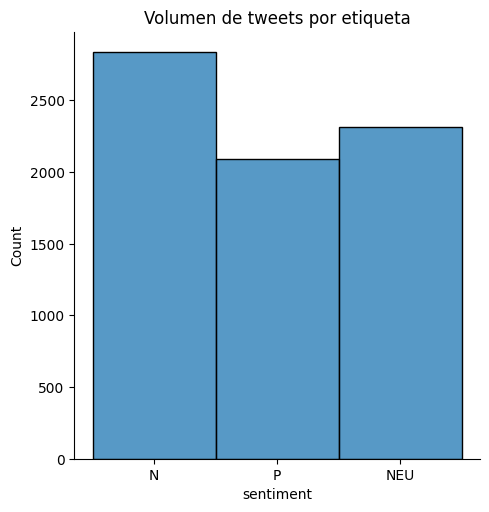

In [ ]:
# Eliminamos los duplicados
df.drop_duplicates(subset = 'content', inplace = True)

# Comprobamos distribución de la etiqueta 'sentiment'
sns.displot(df.sentiment)
plt.title('Volumen de tweets por etiqueta');

print(df.sentiment.value_counts())
print('Tamaño del dataset:', df.shape)

In [ ]:
# Comprobamos nulls
print(df.isnull().sum())

content      0
sentiment    0
dtype: int64


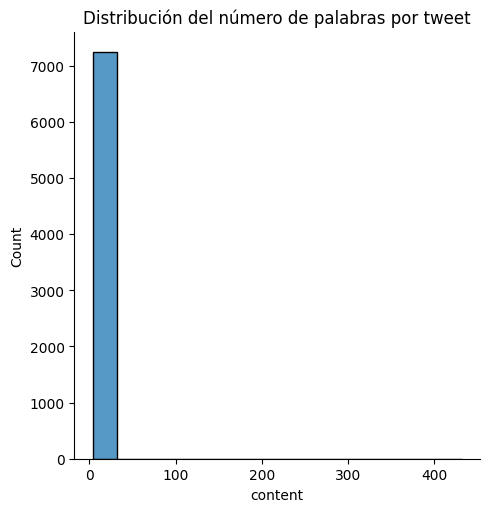

In [ ]:
def count_words(df):
    count = 0
    for word in df.split():
        count += 1
    return count

sns.displot(df['content'].apply(count_words), bins = 15)
plt.title('Distribución del número de palabras por tweet');

## **1.3 Preprocesamiento y Limpieza de Texto**

Los datos de redes sociales son ruidosos. Aquí aplicamos los siguientes filtros:
- **Eliminamos signos de puntuación:** Algunos los eliminaremos y otros será preferible sustituirlos por espacios, ya que de lo contrario habría palabras que podrían juntarse y perderíamos el significado.
- **Normalizamos transformando enlaces por {link}, emojis por {emo_pos/neu/neg}, hashtags por {hash}, divisas por {eur} y menciones por {menc}.**
- **Normalizamos las risas**, ya que puede tener connotaciones muy distintas un 'jajaja' que un 'jijiji'. Cada una puede asociarse a un contexto determinado.
- **Corregimos palabras mal escritas** con PySpellChecker de modo que podremos converger en la misma palabra aquellas que estén escritas con faltas de acentos o letras mal escritas.
- **Corregimos abreviacion** de palabras como 'd' por 'de', 'x' por 'por' y etcétera.
- **Eliminamos las letras repetidas** que puedan aparecer en las palabras para evitar que el modelo entienda, por ejemplo, 'aaaamigo' y 'amigo' como dos palabras diferentes.
- **Eliminamos stop words**, es decir, aquellas palabras como pronombres, artículos o preposiciones, que no aporten un significado intrínseco.
- **Por último, lematizar o stemizamos las frases.** Ambos procesos se refieren a reducir las palabras a su raíz con el objetivo de disminuir el volumen de palabras distintas, y de que palabras muy relacionadas sean interpretadas como palabras diferentes (mesa/mesas, abuelo/abuela/, comeríamos/comer). Para realizar estas transformaciones tenemos dos opciones: La lematización y la estemización. En el primer caso, la palabra se transforma a la raíz (hubiera/haber), en el segundo caso, la palabra se corta (hubiera/hub). La lematización es mucho más costosa computacionalmente pero arroja mejores resultados; la stemización es más rápida pero corre el riesgo de seccionar demasiado la palabra, eliminando su significado y haciéndola similar a otras que no proceden de la misma raíz. Para este caso vamos a emplear la lematización.

In [ ]:
# Eliminamos signos de puntuación y sustituimos por espacios en blanco

def remove_punctuation_space(df):
    PUNCTUATION = re.compile("""(\-)|(\,)|(\..)|(\...)|(\....)|(\.....)|(\......)|(\.......)""")

    return " ".join([PUNCTUATION.sub(" ", word.lower()) for word in df.split()])

In [ ]:
# Eliminamos signos de puntuación sin reemplazo

def remove_punctuation(df):
    PUNCTUATION = re.compile("""(\.)|(\;)|(\:)|(\!)|(\?)|(\¡)|(\¿)| \
    (\")|(\()|(\))|(\[)|(\])|(\d+)|(\/)|(\“)|(\”)|(\')|(\-)|(\")|(\*)""")

    return " ".join([PUNCTUATION.sub("", word.lower()) for word in df.split()])

In [ ]:
# Corregimos abreviaciones
def fix_abbr(x):
    if type(x) == list:
        words = x
    elif type(x) == str:
        words = x.split()
    else:
        raise TypeError('El formato no es válido, debe ser lista o str')

    abbrevs = {'d': 'de',
               'x': 'por',
               'xa': 'para',
               'as': 'has',
               'q': 'que',
               'k': 'que',
               'dl': 'del',
               'xq': 'porqué',
               'dr': 'doctor',
               'dra': 'doctora',
               'sr': 'señor',
               'sra': 'señora',
               'm': 'me'}
    return " ".join([abbrevs[word] if word in abbrevs.keys() else word for word in words])

In [ ]:
# Sustituimos links por {link}
def remove_links(df):
    return " ".join(['{link}' if ('http') in word else word for word in df.split()])

In [ ]:
# Eliminamos vocales repetidas

def remove_repeated_vocals(df):

    list_new_word = []

    for word in df.split(): #separamos en palabras
        new_word = []
        pos = 0

        for letra in word: #separamos cada palabra en letras
            #print(word, letra, pos, '-', new_word)
            if pos>0:
                if letra in ('a', 'e', 'i', 'o', 'u') and letra == new_word[pos-1]:
                    None
                else:
                    new_word.append(letra)
                    pos +=1
            else:
                new_word.append(letra)

                pos += 1
        else:
            list_new_word.append("".join(new_word))

    return " ".join(list_new_word)

In [ ]:
# Normalizamos risas 'jajaja', 'jejeje', 'jojojo'

def normalize_laughts(df):

    list_new_words = []
    for word in df.split(): #separamos en palabras
        count = 0
        vocals_dicc = {'a': 0, 'e': 0, 'i': 0, 'o':0, 'u':0}

        for letra in word:
            #print(word)
            if letra == 'j':
                count+=1
            if letra in vocals_dicc.keys():
                vocals_dicc[letra] += 1
        else:
            if count>3:
                dicc_risa = {'a': 'jaja', 'e': 'jeje', 'i': 'jiji', 'o': 'jojo', 'u': 'juju'}
                risa_type = max(vocals_dicc, key= lambda x: vocals_dicc[x]) #Indica si es a,e,i,o,u
                list_new_words.append(dicc_risa[risa_type])
            else:
                list_new_words.append(word)

    return " ".join(list_new_words)

In [ ]:
# Sustituimos hashtag por {hash}
def remove_hashtags(df):
    return " ".join(['{hash}' if word.startswith('#') else word for word in df.split()])

In [ ]:
# Sustituimos menciones por {mencion}
def remove_mentions(df):
    return " ".join(['{menc}' if word.startswith('“@') or word.startswith('@') else word for word in df.split()])

In [ ]:
# Función para identificar los 'emojis' tradicionales

def transform_icons(df):
    word_list = []
    pos_emojis = [':)', ':D', ':))', ':)))', 'xD', 'xd', 'XD']
    neg_emojis = [':(', ":'(", '>:(', ':,(', ":(("]
    for word in df.split():
        if word in neg_emojis:
            word = '{emoji_neg}'
            word_list.append(word)
        elif word in pos_emojis:
            word = '{emoji_pos}'
            word_list.append(word)
        elif ':O' in word:
            word = '{emoji_neu}'
            word_list.append(word)
        else:
            word_list.append(word)
    return " ".join(word_list)

In [ ]:
# Separamos emojis que vengan juntos
def sep_emojis(df):
    words_list = []
    for token in df.split():
        new_word = []
        for letra in token:
            if emoji.is_emoji(letra):
                words_list.append(letra)
            else:
                new_word.append(letra)
        else:
            words_list.append("".join(new_word))

    return (" ".join(word for word in words_list if word != ''))

In [ ]:
# Creamos diccionario de emojis
import csv

def _build_dict_from_csv(csv_path):
    """ Fork basado en emosent-py de Fintel Labs Inc. """

    emoji_sentiment_rankings = {}

    with open(csv_path, newline='', encoding='utf-8') as csv_file:
        csv_reader = csv.reader(csv_file)
        _header_row = next(csv_reader)
        for row in csv_reader:
            emoji = row[0]
            unicode_codepoint = row[1]
            occurrences = int(row[2])
            negative = float(row[4])
            neutral = float(row[5])
            positive = float(row[6])

            emoji_sentiment_rankings[unicode_codepoint] = {
                'emoji': emoji,
                'occurrences': occurrences,
                'sentiment': [negative, neutral, positive]
            }

    return emoji_sentiment_rankings

EMOJI_SENTIMENT_DICT = _build_dict_from_csv('Emoji_Sentiment_Data_v1.0.csv')

In [ ]:
# Definimos función para identificar sentimiento del emoji
from emosent import get_emoji_sentiment_rank
import emoji

# Devuelve true/false si es emoji
def char_is_emoji(character):
    return emoji.is_emoji(character)

# DEPRECATED - Devuelve si un emoji es neg/pos/neutro o no identificado
def sentiment_emoji(emoji_char):
    try:
        sentiment = get_emoji_sentiment_rank(emoji_char)['sentiment_score']
        if sentiment < -0.3:
            return '{emoji_neg}'
        elif sentiment < 0.3:
            return '{emoji_neu}'
        elif sentiment >= 0.3:
            return '{emoji_pos}'
    except:
        return '{emoji_na}'

# Devuelve si un emoji es neg/pos/neutro o no identificado
def get_emoji_rank(emoji_char):

    emoji_code = f'0x{ord(emoji_char[0]):X}'.lower()

    if emoji_code in EMOJI_SENTIMENT_DICT.keys():
        if EMOJI_SENTIMENT_DICT[emoji_code]['occurrences'] > 80:
            if np.argmax(EMOJI_SENTIMENT_DICT[emoji_code]['sentiment']) == 0:
                return '{emoji_neg}'
            elif np.argmax(EMOJI_SENTIMENT_DICT[emoji_code]['sentiment']) == 1:
                return '{emoji_neu}'
            else:
                return '{emoji_pos}'
        else:
            return '{emoji_neu}'
    else:
        return '{emoji_neu}'

def transform_emoji(df):
    return " ".join([get_emoji_rank(word) if char_is_emoji(word) else word for word in df.split()])

In [ ]:
# Eliminamos stopwords
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
spanish_stopwords = stopwords.words('spanish')
non_stopwords = ['no', 'ni', 'poco', 'mucho', 'nada', 'muchos', 'muy', 'nosotros',
                 'nosotras', 'vosotros', 'vosotras', 'ellos', 'ellas', 'ella', 'él', 'tu', 'tú', 'yo',
                 'pero', 'hasta', 'contra', 'por']
spanish_stopwords = [word for word in stopwords.words('spanish') if word not in non_stopwords]

def remove_stopwords(df):
    return " ".join([word for word in df.split() if word not in spanish_stopwords])

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\darias\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Función para stemizar
from nltk.stem.snowball import SnowballStemmer

def stem(df):
    stemmer = SnowballStemmer('spanish')
    return " ".join([stemmer.stem(word) for word in df.split()])

In [ ]:
!python -m spacy download es_core_news_md

     ---------------------------------------- 0.0/42.3 MB ? eta -:--:--
     --- ------------------------------------ 4.2/42.3 MB 36.1 MB/s eta 0:00:02
     ----------------------- --------------- 25.7/42.3 MB 85.6 MB/s eta 0:00:01
     --------------------------------------- 42.3/42.3 MB 84.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')



[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Función para lematizar

# Creamos el objeto
import spacy
import es_core_news_md
spacy.prefer_gpu() # or spacy.require_gpu()
nlp = es_core_news_md.load()

# Definimos función
def lemmatizer(df):
    word_list = []
    doc = nlp(df)
    for tok in doc:
        if str(tok) == 'menc':
              word_list.append('{menc}')
        elif str(tok) == 'hash':
              word_list.append('{hash}')
        elif str(tok) == 'link':
              word_list.append('{link}')
        elif str(tok) == 'emoji_pos':
              word_list.append('{emoji_pos}')
        elif str(tok) == 'emoji_neu':
              word_list.append('{emoji_neu}')
        elif str(tok) == 'emoji_neg':
              word_list.append('{emoji_neg}')
        elif str(tok) == 'eur':
              word_list.append('{eur}')
        else:
            word_list.append(tok.lemma_.lower())

    return " ".join([word for word in word_list if (word != '{') and (word!='}')])

In [ ]:
from spellchecker import SpellChecker

spell = SpellChecker(language='es', distance=1)

def correcting_words(df):
    words = [word for word in df.split() if word] # Filter out empty strings
    misspelled_words = spell.unknown(words) # Calculate unknown words once
    corrected_output_list = []
    for word in words:
        if word in misspelled_words:
            corrected_word = spell.correction(word)
            # If correction returns None, use the original word
            corrected_output_list.append(corrected_word if corrected_word is not None else word)
        else:
            corrected_output_list.append(word)
    return " ".join(corrected_output_list)

In [ ]:
def remove_eur(df):
    wlist = ['{eur}' if ('€' in word) | ('euro' in word) | ('$' in word) else word for word in df.split()]
    return " ".join(wlist)

In [ ]:
# Put it all together

def transform_tweets(df, mode='lemma'):

    df = remove_links(df)
    df = remove_punctuation_space(df)
    df = remove_mentions(df)
    df = remove_hashtags(df)
    df = remove_eur(df)
    df = transform_icons(df)
    df = sep_emojis(df)
    df = transform_emoji(df)
    df = normalize_laughts(df)
    df = remove_punctuation(df)
    df = remove_repeated_vocals(df)
    df = correcting_words(df)
    df = fix_abbr(df)
    df = remove_stopwords(df)
    if mode=='lemma':
        df = lemmatizer(df)
    elif mode=='stem':
        df = stem(df)
    else:
        raise TypeError('Invalid mode. Must be "lemma" or "stem"')

    return df

In [ ]:
print('Tweet original:\n', df.content[50:51].iloc[0])
print('Tweet lematizado:\n', df.content[50:51].apply(transform_tweets, mode='lemma').iloc[0])
print('Tweet stemizado:\n',df.content[50:51].apply(transform_tweets, mode='stem').iloc[0])


Tweet original:
 Nos encanta hacerte feliz @rubndu
Tweet lematizado:
 encanto hacerte feliz {menc}
Tweet stemizado:
 encant hacert feliz {menc}


In [ ]:
%%time
# Aplicamos
df.content = df.content.apply(transform_tweets, mode='lemma')

CPU times: total: 21.6 s
Wall time: 22.2 s


## **1.4 Arquitecturas y Entrenamiento**
En esta fase exploraremos tres enfoques distintos para la clasificación de los tweets:

* **Modelos de Deep Learning:** Emplearemos arquitecturas avanzadas capaces de
capturar dependencias secuenciales, tales como redes GRU, LSTM, Bidireccionales y Redes Convolucionales 1D (Conv1D). Estas redes utilizan capas de Embedding para representar las palabras en un espacio vectorial continuo.

* **Modelos Clásicos con CountVectorizer:** Evaluaremos modelos tradicionales como RandomForest, Logistic Regression y SVC. Para estos modelos, transformaremos el texto utilizando CountVectorizer, una técnica que convierte una colección de documentos de texto en una matriz de recuento de fichas (frecuencias de palabras), permitiendo al modelo trabajar con vectores numéricos basados en la ocurrencia de términos.

* **Modelos Clásicos con Tf-idf:** Probaremos nuevamente RandomForest, Logistic Regression y SVC, pero esta vez utilizando Tf-idf (Term Frequency-Inverse Document Frequency). A diferencia del simple conteo, esta técnica evalúa la relevancia de una palabra en un documento en relación con todo el corpus. Palabras muy comunes que aportan poco valor (como preposiciones) reciben un peso bajo, mientras que términos específicos y distintivos obtienen una mayor importancia estadística.

### **1.4.1 Deep learning**

#### 1.4.1.1 GRU

In [ ]:
from tensorflow import keras

In [ ]:
# Número de palabras del modelo
tokens = set()
for tweet in df.content:
    for word in tweet.split():
        tokens.add(word)
dim = len(tokens)
print('Número total de palabras:', dim)


Número total de palabras: 10062


In [ ]:
INPUT_LENGTH = 25
EMBED_DIM = 128
#MAX_WORDS = dim
MAX_LEN = 200

# Creamos tokenizador
tokenizer = keras.preprocessing.text.Tokenizer(num_words = dim)
tokenizer.fit_on_texts(df.content)
sequences = tokenizer.texts_to_sequences(df.content)
X = keras.preprocessing.sequence.pad_sequences(
    sequences,
    maxlen = INPUT_LENGTH
)
y = pd.get_dummies(df.sentiment).values

In [ ]:
print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (7239, 25)
Shape y: (7239, 3)


In [ ]:
# Separamos train/test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state = 42,
                                                    test_size = 0.15)

In [ ]:
# Definimos parámetros para el modelo
DROPOUT_VAL = 0.6
BATCH_SIZE = 16
DENSE_DIM = 3
UNITS = 700
EPOCHS = 50

# Creamos el modelo
layers = [
    keras.layers.Embedding(dim,
                           EMBED_DIM,
                           input_length=INPUT_LENGTH),
    keras.layers.SpatialDropout1D(DROPOUT_VAL),
    keras.layers.GRU(UNITS,
                     dropout=DROPOUT_VAL,
                     recurrent_dropout=0),
    keras.layers.Dense(DENSE_DIM,
                       activation='softmax')

]

model = keras.models.Sequential(layers)

# Compilamos modelo
history = model.compile(optimizer = 'adam',
                        loss = 'categorical_crossentropy',
                        metrics = ['accuracy'])

# Añadimos faststopping

callback = keras.callbacks.EarlyStopping(monitor = 'val_loss',
                                         mode = 'min',
                                         verbose = 0,
                                         patience = 5)

checkpoint_1 = keras.callbacks.ModelCheckpoint("Results/GRU_model.keras",
                               monitor='val_accuracy',
                               verbose=1,
                               save_best_only=True,
                               mode='auto',
                               save_weights_only=False)

In [ ]:
# Entrenamos
history = model.fit(X_train,
                    y_train,
                    epochs = EPOCHS,
                    validation_data = (X_test, y_test),
                    batch_size = BATCH_SIZE,
                    callbacks = [callback, checkpoint_1])

Epoch 1/50
385/385 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4022 - loss: 1.0799
Epoch 1: val_accuracy improved from None to 0.49079, saving model to Results/GRU_model.keras

Epoch 1: finished saving model to Results/GRU_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.4174 - loss: 1.0633 - val_accuracy: 0.4908 - val_loss: 0.9998
Epoch 2/50
383/385 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5181 - loss: 0.9772
Epoch 2: val_accuracy improved from 0.49079 to 0.52486, saving model to Results/GRU_model.keras

Epoch 2: finished saving model to Results/GRU_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.5214 - loss: 0.9681 - val_accuracy: 0.5249 - val_loss: 0.9440
Epoch 3/50
384/385 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5966 - loss: 0.8699
Epoch 3: val_accuracy improved from 0.52486 to 0.56169, saving model to Results/GRU_model.keras

Epoch 3: finished saving model to Results/GRU_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/ste

In [ ]:
accuracy_dl_gru = model.evaluate(X_test, y_test)
accuracy_dl_gru

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5433 - loss: 1.0902


[1.0901672840118408, 0.5432780981063843]

In [ ]:
from sklearn.metrics import classification_report
y_pred_1 = model.predict(X_test)
print(classification_report(np.argmax(y_test, axis=1), np.argmax(y_pred_1, axis=1)))

34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
              precision    recall  f1-score   support

           0       0.58      0.61      0.59       408
           1       0.45      0.46      0.45       369
           2       0.61      0.56      0.58       309

    accuracy                           0.54      1086
   macro avg       0.55      0.54      0.54      1086
weighted avg       0.54      0.54      0.54      1086



In [ ]:
from sklearn.metrics import confusion_matrix

def display_cm(y_test, y_pred):
    sns.heatmap(confusion_matrix(np.argmax(y_test, axis=1), np.argmax(y_pred, axis=1), normalize = 'true'),
                annot = True, cmap = 'Blues', fmt='g', cbar=False)
    plt.title('Real vs pred')
    plt.xlabel('Predicted values')
    plt.ylabel('Real values');

    plt.show()

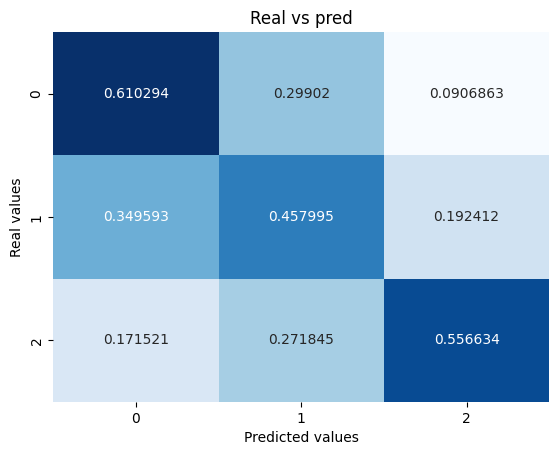

In [ ]:
display_cm(y_test, y_pred_1)

#### 1.4.1.2 RNN - LSTM layers

In [ ]:
from keras.models import Sequential
from keras import layers
from keras import regularizers
from keras import backend as K
from keras.callbacks import ModelCheckpoint

# Definimos parámetros para el modelo
DROPOUT_VAL = 0.5
BATCH_SIZE = 16
#DENSE_DIM = 3
EPOCHS = 50

# Creamos capas

layers = [
    keras.layers.Embedding(dim, 20, input_length = INPUT_LENGTH),
    keras.layers.LSTM(15,dropout = DROPOUT_VAL, return_sequences=True),
    keras.layers.LSTM(15,dropout = DROPOUT_VAL),
    keras.layers.Dense(3, activation = 'softmax')
]

model2 = keras.models.Sequential(layers)

# Compilamos

model2.compile(optimizer='rmsprop',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

# Añadimos faststopping
callback = keras.callbacks.EarlyStopping(monitor = 'val_loss',
                                         mode = 'min',
                                         verbose = 0,
                                         patience = 5)

# Añadimos checkpoint
metric = 'val_accuracy'

checkpoint_2 = keras.callbacks.ModelCheckpoint("Results/RNN-LSTM_model.keras",
                                    monitor = metric,
                                    verbose=1,
                                    save_best_only=True,
                                    mode='auto',
                                    save_weights_only=False)

In [ ]:
# Entrenamos

history_2 = model2.fit(X_train,
                       y_train,
                       epochs = EPOCHS,
                       #validation_split = 0.1,
                       validation_data = (X_test, y_test),
                       batch_size = 16,
                       callbacks=[checkpoint_2, callback])

Epoch 1/50
381/385 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3921 - loss: 1.0879
Epoch 1: val_accuracy improved from None to 0.45304, saving model to Results/RNN-LSTM_model.keras

Epoch 1: finished saving model to Results/RNN-LSTM_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4076 - loss: 1.0796 - val_accuracy: 0.4530 - val_loss: 1.0540
Epoch 2/50
378/385 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4706 - loss: 1.0273
Epoch 2: val_accuracy improved from 0.45304 to 0.48343, saving model to Results/RNN-LSTM_model.keras

Epoch 2: finished saving model to Results/RNN-LSTM_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4921 - loss: 1.0031 - val_accuracy: 0.4834 - val_loss: 0.9871
Epoch 3/50
383/385 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5252 - loss: 0.9608
Epoch 3: val_accuracy improved from 0.48343 to 0.51842, saving model to Results/RNN-LSTM_model.keras

Epoch 3: finished saving model to Results/RNN-LSTM_model.keras
385/385 ━━━━━━━━

In [ ]:
# Evaluamos
accuracy_dl_lstm = model2.evaluate(X_test, y_test)
accuracy_dl_lstm

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5479 - loss: 0.9556 


[0.955584704875946, 0.5478821396827698]

In [ ]:
# Sacamos classification report
y_pred_2 = model2.predict(X_test)
print(classification_report(np.argmax(y_test, axis=1), np.argmax(y_pred_2, axis=1)))

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

           0       0.58      0.65      0.61       408
           1       0.43      0.48      0.45       369
           2       0.68      0.50      0.58       309

    accuracy                           0.55      1086
   macro avg       0.57      0.54      0.55      1086
weighted avg       0.56      0.55      0.55      1086



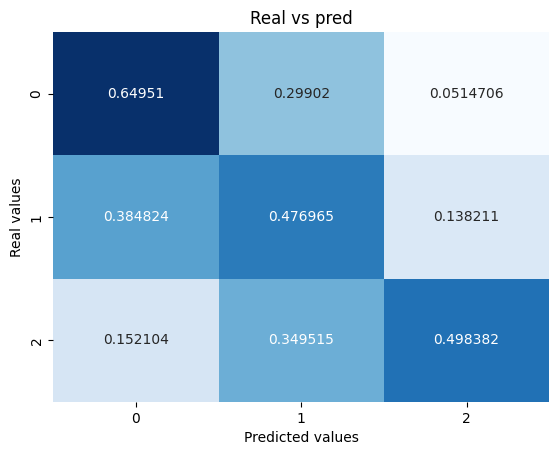

In [ ]:
display_cm(y_test, y_pred_2)

#### 1.4.1.3 RNN - Bidirectional layers

In [ ]:
DROPOUT_VAL = 0.6

layers = [
    keras.layers.Embedding(dim, 40, input_length = INPUT_LENGTH),
    keras.layers.Bidirectional(keras.layers.LSTM(20, dropout = DROPOUT_VAL)),
    keras.layers.Dense(3, activation = 'softmax')
]

model3 = keras.models.Sequential(layers)

# Compilamos modelo
model3.compile(optimizer = 'rmsprop',
                        loss = 'categorical_crossentropy',
                        metrics = ['accuracy'])

# Creamos faststopping
callback = keras.callbacks.EarlyStopping(monitor = 'val_loss',
                                         mode = 'min',
                                         verbose = 0,
                                         patience = 5)
# Creamos checkpoint
checkpoint_3 = keras.callbacks.ModelCheckpoint('Results/RNN-Bidirectional_model.keras',
                                     monitor = 'val_accuracy',
                                     verbose = 1,
                                     save_best_only = True,
                                     mode = 'auto')


In [ ]:
# Entrenamos
history_3 = model3.fit(X_train,
                       y_train,
                       epochs = EPOCHS,
                       validation_data = (X_test, y_test),
                       batch_size = 16,
                       callbacks = [callback, checkpoint_3])

Epoch 1/50
376/385 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3998 - loss: 1.0808
Epoch 1: val_accuracy improved from None to 0.48250, saving model to Results/RNN-Bidirectional_model.keras

Epoch 1: finished saving model to Results/RNN-Bidirectional_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4308 - loss: 1.0601 - val_accuracy: 0.4825 - val_loss: 1.0130
Epoch 2/50
378/385 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5119 - loss: 0.9789
Epoch 2: val_accuracy improved from 0.48250 to 0.49632, saving model to Results/RNN-Bidirectional_model.keras

Epoch 2: finished saving model to Results/RNN-Bidirectional_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5259 - loss: 0.9624 - val_accuracy: 0.4963 - val_loss: 0.9700
Epoch 3/50
382/385 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5701 - loss: 0.8902
Epoch 3: val_accuracy improved from 0.49632 to 0.52394, saving model to Results/RNN-Bidirectional_model.keras

Epoch 3: finished saving model to 

In [ ]:
# Evaluamos
accuracy_dl_bi = model3.evaluate(X_test, y_test)
accuracy_dl_bi

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5663 - loss: 0.9816 


[0.9815981984138489, 0.5662983655929565]

In [ ]:
# Sacamos classification report
y_pred_3 = model3.predict(X_test)
print(classification_report(np.argmax(y_test, axis=1), np.argmax(y_pred_3, axis=1)))

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

           0       0.59      0.70      0.64       408
           1       0.49      0.39      0.44       369
           2       0.60      0.60      0.60       309

    accuracy                           0.57      1086
   macro avg       0.56      0.56      0.56      1086
weighted avg       0.56      0.57      0.56      1086



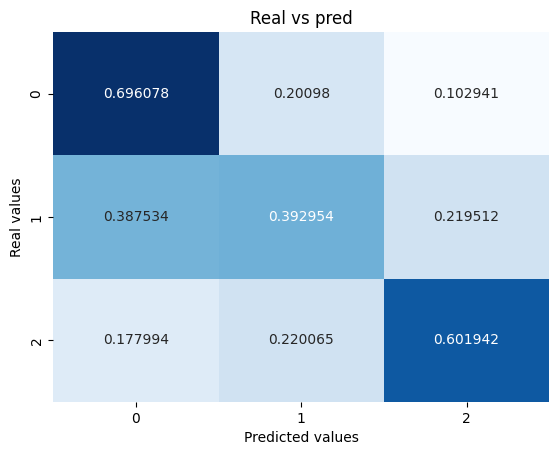

In [ ]:
display_cm(y_test, y_pred_3)

In [ ]:
# Sacamos classification report
y_pred_3 = model3.predict(X_test)
print(classification_report(np.argmax(y_test, axis=1), np.argmax(y_pred_3, axis=1)))

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.59      0.70      0.64       408
           1       0.49      0.39      0.44       369
           2       0.60      0.60      0.60       309

    accuracy                           0.57      1086
   macro avg       0.56      0.56      0.56      1086
weighted avg       0.56      0.57      0.56      1086



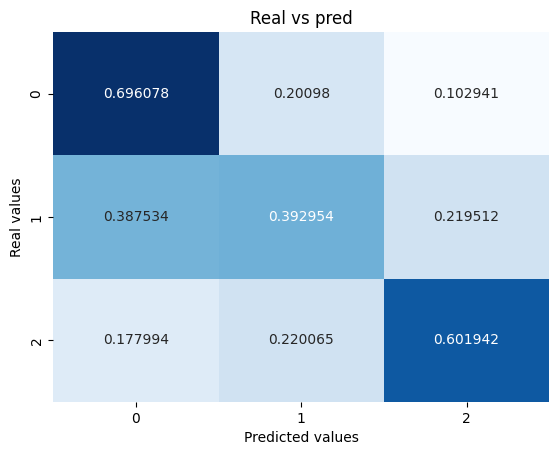

In [ ]:
display_cm(y_test, y_pred_3)

#### 1.4.1.4 Conv1 layers

In [ ]:
# Creamos capas

layers = [
    keras.layers.Embedding(dim, 40, input_length = INPUT_LENGTH),
    keras.layers.Conv1D(20,
                        3,
                        activation = 'relu',
                        kernel_regularizer = regularizers.l1_l2(l1 = 2e-3, l2 = 2e-3),
                        bias_regularizer = regularizers.l2(2e-3)),
    keras.layers.MaxPooling1D(5),
    keras.layers.Conv1D(20,
                        3,
                        activation = 'relu',
                        kernel_regularizer = regularizers.l1_l2(l1 = 2e-3, l2 = 2e-3),
                        bias_regularizer = regularizers.l2(2e-3)),
    keras.layers.GlobalMaxPooling1D(),
    keras.layers.Dense(3, activation = 'softmax')
]

model4 = keras.models.Sequential(layers)

# Compilamos
model4.compile(optimizer = 'rmsprop',
               loss = 'categorical_crossentropy',
               metrics = ['accuracy'])

# Creamos faststopping
callback = keras.callbacks.EarlyStopping(monitor = 'val_loss',
                                         mode = 'min',
                                         verbose = 0,
                                         patience = 5)
# Creamos checkpoint
checkpoint_4 = keras.callbacks.ModelCheckpoint('Results/Conv1_model.keras',
                                     monitor = 'val_accuracy',
                                     verbose = 1,
                                     save_best_only = True,
                                     mode = 'auto')

In [ ]:
# Entrenamos
history_4 = model4.fit(X_train,
                       y_train,
                       epochs = EPOCHS,
                       validation_data = (X_test, y_test),
                       batch_size = 16,
                       callbacks = [callback, checkpoint_4])

Epoch 1/50
369/385 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3765 - loss: 1.4278
Epoch 1: val_accuracy improved from None to 0.37569, saving model to Results/Conv1_model.keras

Epoch 1: finished saving model to Results/Conv1_model.keras
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3933 - loss: 1.2231 - val_accuracy: 0.3757 - val_loss: 1.0981
Epoch 2/50
371/385 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3930 - loss: 1.0942
Epoch 2: val_accuracy did not improve from 0.37569
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3944 - loss: 1.0939 - val_accuracy: 0.3757 - val_loss: 1.0972
Epoch 3/50
368/385 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4001 - loss: 1.0931
Epoch 3: val_accuracy did not improve from 0.37569
385/385 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3944 - loss: 1.0938 - val_accuracy: 0.3757 - val_loss: 1.0964
Epoch 4/50
374/385 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3921 - loss: 1.0945
Epoch 4: val_accuracy did not improve from 0.37

In [ ]:
# Evaluamos
accuracy_dl_conv1d = model4.evaluate(X_test, y_test)
accuracy_dl_conv1d

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3757 - loss: 1.0974 


[1.0973713397979736, 0.37569060921669006]

In [ ]:
# Sacamos classification report
y_pred_4 = model4.predict(X_test)
print(classification_report(np.argmax(y_test, axis=1), np.argmax(y_pred_4, axis=1)))

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.38      1.00      0.55       408
           1       0.00      0.00      0.00       369
           2       0.00      0.00      0.00       309

    accuracy                           0.38      1086
   macro avg       0.13      0.33      0.18      1086
weighted avg       0.14      0.38      0.21      1086



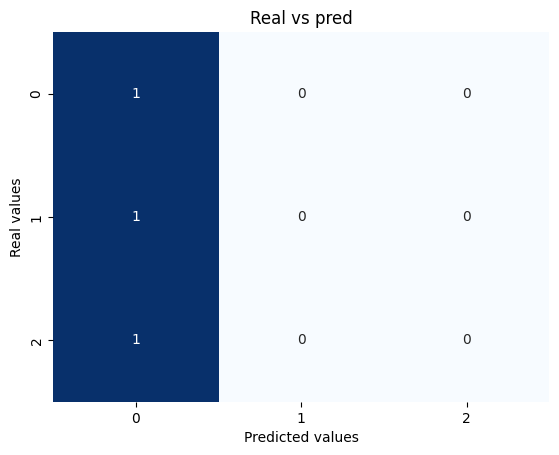

In [ ]:
display_cm(y_test, y_pred_4)

### **1.4.2 CountVectorizer**

In [ ]:
# Creamos X,y

X = df['content']
y = df.replace({'sentiment': {'N': -1, 'NEU': 0, 'P': 1}})['sentiment']
y = y.astype(int)

# Creamos train/test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state = 42,
                                                    test_size = 0.15)

In [ ]:
%%time
# Vectorizamos
from sklearn.feature_extraction.text import CountVectorizer

# Creamos objeto y entrenamos
baseline_vectorizer = CountVectorizer(binary = True,
                                      ngram_range=(1, 3))
baseline_vectorizer.fit(X_train)

# Transformamos X en sparse vector
X_train_baseline = baseline_vectorizer.transform(X_train)
X_test_baseline = baseline_vectorizer.transform(X_test)

CPU times: total: 172 ms
Wall time: 183 ms


#### 1.4.2.1 Random Forest

In [ ]:
# Imprimimos tamaño
print('X_train_baseline:', X_train_baseline.shape)
print('X_test_baseline:', X_test_baseline.shape)

X_train_baseline: (6153, 92457)
X_test_baseline: (1086, 92457)


In [ ]:
# Creamos objeto y entrenamos

random_forest_cv = RandomForestClassifier(n_estimators = 100,
                                          n_jobs = -1)
random_forest_cv.fit(X_train_baseline, y_train)



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
# Evaluamos
random_forest_cv.score(X_test_baseline, y_test)

0.5524861878453039

In [ ]:
# Predecimos
y_pred_rf_cv = random_forest_cv.predict(X_test_baseline)
from sklearn.metrics import classification_report,accuracy_score
print(classification_report(y_test, y_pred_rf_cv))

              precision    recall  f1-score   support

          -1       0.53      0.77      0.63       408
           0       0.48      0.35      0.40       369
           1       0.70      0.50      0.59       309

    accuracy                           0.55      1086
   macro avg       0.57      0.54      0.54      1086
weighted avg       0.56      0.55      0.54      1086



In [ ]:
# Sacamos el accuracy
accuracy_rf_cv = accuracy_score(y_test, y_pred_rf_cv)
accuracy_rf_cv

0.5524861878453039

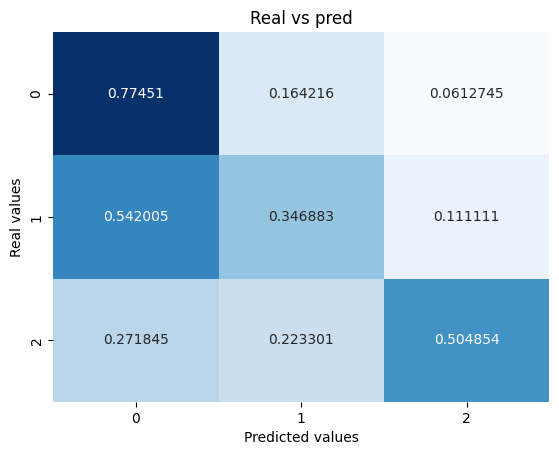

In [ ]:
#display_cm(y_test, y_pred_rf_cv)
from sklearn.metrics import confusion_matrix

y_pred_rf_cv = random_forest_cv.predict(X_test_baseline)
sns.heatmap(confusion_matrix(y_test, y_pred_rf_cv, normalize = 'true'),
            annot=True, fmt='g', cmap = 'Blues', cbar = False);

plt.title('Real vs pred')
plt.xlabel('Predicted values')
plt.ylabel('Real values');

plt.show()

#### 1.4.2.2 Logistic Regression

In [ ]:
%%time
from sklearn.linear_model import LogisticRegression

# Creamos modelo
lr_cv_params = dict(C = [0.25, 0.5, 0.75],
                    penalty = ['l1', 'l2'],
                    class_weight = [None, 'balanced'],
                    solver = ['newton-cg', 'sag', 'lbfgs'])

lr_cv_grid = GridSearchCV(LogisticRegression(max_iter = 300),
                     lr_cv_params,
                     cv = 5,
                     n_jobs = -1,
                     scoring = 'accuracy').fit(X_train_baseline,
                                               y_train)
print('Best score:', lr_cv_grid.best_score_)
print('Best params:', lr_cv_grid.best_params_)

Best score: 0.569967043780917
Best params: {'C': 0.75, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
CPU times: total: 2.25 s
Wall time: 24.3 s


In [ ]:
y_pred_log_reg_cv_proba = lr_cv_grid.predict_proba(X_test_baseline)
y_pred_log_reg_cv = np.argmax(y_pred_log_reg_cv_proba, axis=1)
accuracy_log_reg_cv = accuracy_score(y_test, y_pred_log_reg_cv)
accuracy_log_reg_cv

0.19244935543278086

In [ ]:
from __future__ import print_function
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

def get_label(probas, i=0.55):
    if np.argmax(probas)==0:
        return -1
    elif np.argmax(probas)==2:
        return 1
    elif np.argmax(probas)==1 and probas[1]<i:
        if probas[2] > probas[0]:
            return 1
        else:
            return -1
    else:
        return 0

y_new = np.array(list(map(lambda x: get_label(x), y_pred_log_reg_cv_proba)))

def interact_proba(i):
    plt.clf()

    y_new = np.array(list(map(lambda x: get_label(x, i), y_pred_log_reg_cv_proba)))

    # Evaluamos modelo
    sns.heatmap(confusion_matrix(y_test, y_new, normalize = 'true'),
                annot=True, fmt='g', cmap = 'Blues', cbar = False);

    plt.title("""Accuracy para cada clase en función
    del threshold controlado por el parámetro i""")
    plt.xlabel('Predicted values')
    plt.ylabel('Real values');

    plt.show()

In [ ]:
interact(interact_proba, i=(0.0,1.0,0.01));

interactive(children=(FloatSlider(value=0.5, description='i', max=1.0, step=0.01), Output()), _dom_classes=('w…

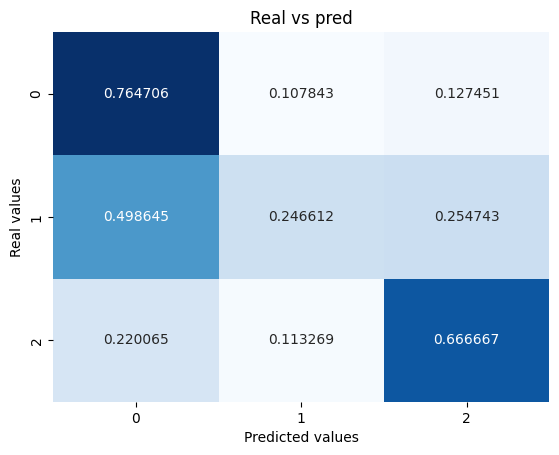

In [ ]:
# Evaluamos modelo
sns.heatmap(confusion_matrix(y_test, y_new, normalize = 'true'),
            annot=True, fmt='g', cmap = 'Blues', cbar = False);

plt.title('Real vs pred')
plt.xlabel('Predicted values')
plt.ylabel('Real values');

plt.show()

#### 1.4.2.3 Linear SVC

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe_lin_svc = Pipeline([
    ('scaler', StandardScaler(with_mean=False)),
    ('svc', LinearSVC())
])
pipe_lin_svc_params = dict(svc__C = [0.01, 0.1, 0.25, 0.5, 1])

lin_svc_cv = GridSearchCV(pipe_lin_svc,
                          pipe_lin_svc_params,
                          cv = 5,
                          n_jobs = -1,
                          scoring = 'accuracy')
lin_svc_cv.fit(X_train_baseline, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...LinearSVC())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate 

In [ ]:
# Best params
lin_svc_cv.best_params_

{'svc__C': 0.01}

In [ ]:
# Predecimos

y_pred_lin_svc_cv = lin_svc_cv.predict(X_test_baseline)
accuracy_lin_svc_cv = accuracy_score(y_test, y_pred_lin_svc_cv)
accuracy_lin_svc_cv

0.5386740331491713

In [ ]:
# Sacamos matriz de correlación
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_lin_svc_cv))

              precision    recall  f1-score   support

          -1       0.53      0.67      0.59       408
           0       0.48      0.42      0.45       369
           1       0.64      0.50      0.56       309

    accuracy                           0.54      1086
   macro avg       0.55      0.53      0.53      1086
weighted avg       0.54      0.54      0.53      1086



### **1.4.3 TF-IDF**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Creamos X,y

X = df['content']
y = df.replace({'sentiment': {'N': -1, 'NEU': 0, 'P': 1}})['sentiment']
y = y.astype(int)

# Creamos train/test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state = 42,
                                                    test_size = 0.15)

# Vectorizamos
tfidf = TfidfVectorizer()
tfidf.fit(X_train)
X_train_tfidf = tfidf.transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

#### 1.4.3.1 Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Creamos objeto y entrenamos
rand_forest_tfidf = RandomForestClassifier(n_estimators = 100,
                                           n_jobs = -1)
rand_forest_tfidf.fit(X_train_tfidf, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
# Evaluamos
accuracy_rand_forest_tfidf = rand_forest_tfidf.score(X_test_tfidf, y_test)
accuracy_rand_forest_tfidf

0.5534069981583793

In [ ]:
# Predecimos
y_pred_rf_tfidf = rand_forest_tfidf.predict(X_test_tfidf)
print(classification_report(y_test, y_pred_rf_tfidf))

              precision    recall  f1-score   support

          -1       0.56      0.70      0.62       408
           0       0.47      0.41      0.44       369
           1       0.64      0.53      0.58       309

    accuracy                           0.55      1086
   macro avg       0.56      0.55      0.55      1086
weighted avg       0.55      0.55      0.55      1086



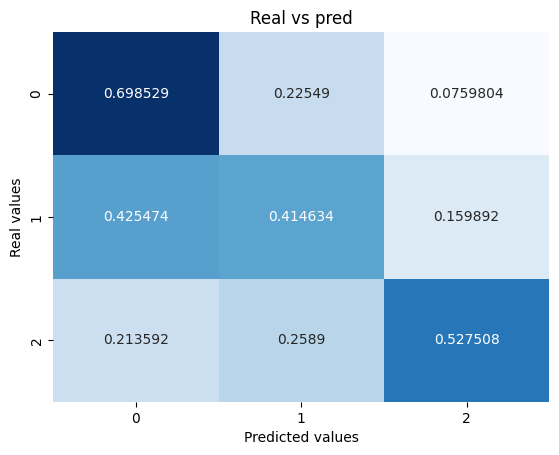

In [ ]:
# Evaluamos modelo
sns.heatmap(confusion_matrix(y_test, y_pred_rf_tfidf, normalize = 'true'),
            annot=True, fmt='g', cmap = 'Blues', cbar = False);

plt.title('Real vs pred')
plt.xlabel('Predicted values')
plt.ylabel('Real values');

plt.show()

#### 1.4.3.2 Logistic Regression

In [ ]:
# Entrenamos reg. log
from sklearn.linear_model import LogisticRegression

lr_tfidf_params = dict(
    C = [0.5, 1, 1.5, 2]
)
lr_tfidf = GridSearchCV(LogisticRegression(),
                        lr_tfidf_params,
                        cv = 5,
                        scoring = 'accuracy',
                        n_jobs = -1).fit(X_train_tfidf, y_train)

print('Best score:', lr_tfidf.best_score_)
print('Best params:', lr_tfidf.best_params_)

Best score: 0.5602159656040102
Best params: {'C': 1}


In [ ]:
# Predecimos
y_pred_lr_tfidf = lr_tfidf.predict(X_test_tfidf)
accuracy_lr_tfidf = accuracy_score(y_test, y_pred_lr_tfidf)
accuracy_lr_tfidf

0.578268876611418

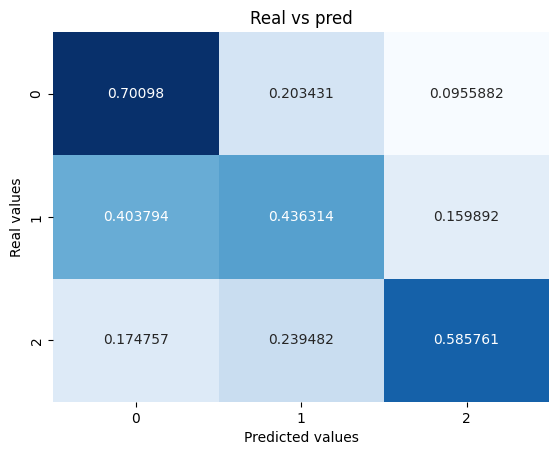

In [ ]:
# Evaluamos modelo
sns.heatmap(confusion_matrix(y_test, y_pred_lr_tfidf, normalize = 'true'),
            annot=True, fmt='g', cmap = 'Blues', cbar = False);

plt.title('Real vs pred')
plt.xlabel('Predicted values')
plt.ylabel('Real values');

plt.show()

#### 1.4.3.3. Linear SVC

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


lin_svc_tfidf_params = dict(C = [0.01, 0.1, 0.25, 0.5, 1])

lin_svc_tfidf = GridSearchCV(LinearSVC(),
                          lin_svc_tfidf_params,
                          cv = 5,
                          n_jobs = -1,
                          scoring = 'accuracy')
lin_svc_tfidf.fit(X_train_tfidf, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearSVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate parameter indexes are al

In [ ]:
# Predecimos

y_pred_lin_svc_tfidf = lin_svc_tfidf.predict(X_test_tfidf)
accuracy_lin_svc_tfidf = accuracy_score(y_test, y_pred_lin_svc_tfidf)
accuracy_lin_svc_tfidf

0.5681399631675875

In [ ]:
# Sacamos matriz de correlación
print(classification_report(y_test, y_pred_lin_svc_tfidf))

              precision    recall  f1-score   support

          -1       0.56      0.74      0.64       408
           0       0.50      0.37      0.43       369
           1       0.65      0.58      0.62       309

    accuracy                           0.57      1086
   macro avg       0.57      0.56      0.56      1086
weighted avg       0.57      0.57      0.56      1086



## **1.5 Escogiendo el mejor modelo**
Tras completar el entrenamiento de las diversas arquitecturas, consolidamos los resultados de precisión (Accuracy) en una tabla comparativa. Este paso es fundamental para identificar qué estrategia de procesamiento y qué algoritmo ofrecen el mejor rendimiento sobre los datos de validación.

In [ ]:
# Tabla con accuracy de todos ellos
accuracy_list = [accuracy_dl_gru[1],
                 accuracy_dl_lstm[1],
                 accuracy_dl_bi[1],
                 accuracy_dl_conv1d[1],
                 accuracy_rf_cv,
                 accuracy_log_reg_cv,
                 accuracy_lin_svc_cv,
                 accuracy_rand_forest_tfidf,
                 accuracy_lr_tfidf,
                 accuracy_lin_svc_tfidf]

columns = ['NN GRU layers', 'NN LSTM layers', 'RNN Bidirectional', 'RNN Conv1d', 'RandForest CountVectorizer',
           'LinReg CountVectorizer', 'Linear SVC CountVectorizer', 'RandForest TFIDF', 'LinReg TFIDF',
           'Linear SVC TFIDF']
df_scores = pd.DataFrame(np.c_[columns, round(pd.Series(accuracy_list), 4)], columns = ['Model', 'Val score']).set_index('Model')
df_scores

,Val score
Model,
NN GRU layers,0.5433
NN LSTM layers,0.5479
RNN Bidirectional,0.5663
RNN Conv1d,0.3757
RandForest CountVectorizer,0.5525
LinReg CountVectorizer,0.1924
Linear SVC CountVectorizer,0.5387
RandForest TFIDF,0.5534
LinReg TFIDF,0.5783


## **1.6 Interpretación de Predicciones**
Para que un modelo de IA sea confiable, no basta con que sea preciso; debemos entender por qué toma sus decisiones. Utilizaremos la librería ELI5 para inspeccionar los pesos del modelo y extraer las palabras o n-gramas que más influyen en la clasificación de cada sentimiento.

In [ ]:
# Usamos eli5 para sacar las features más predictoras. MÉTODO 2
import eli5
from eli5 import explain_weights, explain_prediction


eli5.show_weights(lr_cv_grid.best_estimator_,
                  vec = baseline_vectorizer,
                  target_names = df['sentiment'],
                  horizontal_layout=False)

Weight?,Feature
+1.540,triste
+1.256,peor
+1.166,feo
+1.085,odio
+0.964,horrible
+0.893,miedo
+0.840,pobre
+0.831,malo
+0.828,puta
+0.802,asiento


## **1.7 Predecimos con el modelo escogido**
Antes de empezar a predecir, vamos a establecer una lógica de salida más granular. Con el objetivo de reducir el porcentaje de negativos/positivos que acaban clasificados como neutros, vamos a crear un threshold (umbral). Aquellos tweets predichos originalmente como neutros cuya probabilidad sea menor al 50% serán reclasificados como Neutro-Positivo o Neutro-Negativo según el peso de las otras clases.

In [ ]:
# Función para establecer el threshold en 0.5 y expandir a 5 niveles
def get_label_5_levels(probas, i=0.5):
    # probas = [P(Neg), P(Neu), P(Pos)]
    idx_max = np.argmax(probas)

    if idx_max == 0: # Negativo
        return 0
    elif idx_max == 2: # Positivo
        return 4
    elif idx_max == 1: # Predicción primaria: Neutro
        if probas[1] < i: # Si la confianza en neutro es baja
            if probas[2] > probas[0]:
                return 3 # Neutro-positivo
            else:
                return 1 # Neutro-negativo
        else:
            return 2 # Neutro sólido


### Ejemplo 1: Modelo CountVectorizer (Logistic Regression)
Opciones de modelos entrenados en la seccion 1.4.2 disponibles para probar:
1. `random_forest_cv` (Random Forest)
2. `lr_cv_grid` (Logistic Regression, usado por defecto en este ejemplo)
3. `lin_svc_cv` (Linear SVC)*

* Nota sobre Linear SVC: Este modelo no tiene el metodo predict_proba por defecto.
Si deseas probarlo, deberas cambiar `lr_cv_grid.predict_proba` por `lin_svc_cv.predict`
y adaptar la logica de salida, ya que no devolvera probabilidades.

In [ ]:
def pred_tweet_cv(text):
    clean_text = transform_tweets(text)
    X_vec = baseline_vectorizer.transform([clean_text])
    probas = lr_cv_grid.predict_proba(X_vec)[0]

    sentiments = ['Negativo', 'Neutro-negativo', 'Neutro', 'Neutro-positivo', 'Positivo']
    result = sentiments[get_label_5_levels(probas)]
    print(f"Probabilidades: {probas}")
    print(f"Sentimiento (CV): {result}")

pred_tweet_cv('Losantos contrata a la farmacéutica Pfizer \
para que descubra una vacuna contra el comunismo')
pred_tweet_cv("""Que el 90% de los mensajes que se están dando de cara \
a las navidades están hechos pensando en familias nucleares estándar es algo que me fascina.
El no te juntes con nadie puede ser un poquito duro si vives solo, por ejemplo, y no es precisamente el caso de poca gente.""")
pred_tweet_cv('¡Enhorabuena! Trabajazo de @susanasolisp como \
negociadora del @Europarl_ES de los fondos estructurales. \
Explicación en el hilo.')

Probabilidades: [0.57698813 0.22079234 0.20221953]
Sentimiento (CV): Negativo
Probabilidades: [0.83157029 0.13578744 0.03264227]
Sentimiento (CV): Negativo
Probabilidades: [0.28929582 0.33193641 0.37876777]
Sentimiento (CV): Positivo


### Ejemplo 2: Modelo Tf-idf (SVC/LogReg)
Opciones de modelos entrenados en la seccion 1.4.3 disponibles para probar:
1. `rand_forest_tfidf` (Random Forest)
2. `lr_tfidf` (Logistic Regression, usado por defecto en este ejemplo)
3. `lin_svc_tfidf` (Linear SVC)*

* Nota sobre Linear SVC: Al igual que en el ejemplo anterior, carece de `predict_proba`.

In [ ]:
def pred_tweet_tfidf(text):
    clean_text = transform_tweets(text)
    X_vec = tfidf.transform([clean_text])
    # Suponiendo que el modelo SVC tiene probability=True o usamos LogReg
    probas = lr_tfidf.predict_proba(X_vec)[0]

    sentiments = ['Negativo', 'Neutro-negativo', 'Neutro', 'Neutro-positivo', 'Positivo']
    result = sentiments[get_label_5_levels(probas)]
    print(f"Probabilidades: {probas}")
    print(f"Sentimiento (Tf-idf): {result}")

pred_tweet_tfidf('Losantos contrata a la farmacéutica Pfizer \
para que descubra una vacuna contra el comunismo')
pred_tweet_tfidf("""Que el 90% de los mensajes que se están dando de cara \
a las navidades están hechos pensando en familias nucleares estándar es algo que me fascina.
El no te juntes con nadie puede ser un poquito duro si vives solo, por ejemplo, y no es precisamente el caso de poca gente.""")
pred_tweet_tfidf('¡Enhorabuena! Trabajazo de @susanasolisp como \
negociadora del @Europarl_ES de los fondos estructurales. \
Explicación en el hilo.')

Probabilidades: [0.58272795 0.17470966 0.24256239]
Sentimiento (Tf-idf): Negativo
Probabilidades: [0.6180437  0.24009319 0.1418631 ]
Sentimiento (Tf-idf): Negativo
Probabilidades: [0.26757376 0.28221289 0.45021335]
Sentimiento (Tf-idf): Positivo


### Ejemplo 3: Modelo Deep Learning (GRU/LSTM)
Opciones de arquitecturas entrenadas en la seccion 1.4.1 disponibles para probar:
1. `model` (Red GRU, usado por defecto en este ejemplo)
2. `model2` (Red RNN con capas LSTM)
3. `model3` (Red RNN Bidireccional)
4. `model4` (Red Convolucional 1D)

In [ ]:
def pred_tweet_dl(text):
    clean_text = transform_tweets(text)
    # Tokenización y padding siguiendo el proceso de entrenamiento
    seq = tokenizer.texts_to_sequences([clean_text])
    padded = keras.preprocessing.sequence.pad_sequences(seq, maxlen=INPUT_LENGTH)

    probas = model.predict(padded)[0]

    sentiments = ['Negativo', 'Neutro-negativo', 'Neutro', 'Neutro-positivo', 'Positivo']
    result = sentiments[get_label_5_levels(probas)]
    print(f"Probabilidades: {probas}")
    print(f"Sentimiento (Deep Learning): {result}")

pred_tweet_dl('Losantos contrata a la farmacéutica Pfizer \
para que descubra una vacuna contra el comunismo')
pred_tweet_dl("""Que el 90% de los mensajes que se están dando de cara \
a las navidades están hechos pensando en familias nucleares estándar es algo que me fascina.
El no te juntes con nadie puede ser un poquito duro si vives solo, por ejemplo, y no es precisamente el caso de poca gente.""")
pred_tweet_dl('¡Enhorabuena! Trabajazo de @susanasolisp como \
negociadora del @Europarl_ES de los fondos estructurales. \
Explicación en el hilo.')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Probabilidades: [0.6869963  0.09958525 0.2134184 ]
Sentimiento (Deep Learning): Negativo
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Probabilidades: [0.65981823 0.25170568 0.08847606]
Sentimiento (Deep Learning): Negativo
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Probabilidades: [0.39455    0.25134695 0.35410312]
Sentimiento (Deep Learning): Negativo


# **2. Categorizacion de Texto**
Consiste en clasificar un texto en una clase mas grande pero en el caso de este ejemplo sin nesesidad de entrenar el modelo en esas categorias One-shot ya que proveemos un ejemplo

In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## **Predecir Paises de sus Capitales:**

### **Parte 1:** Importar la informacion

In [ ]:
data = pd.read_csv('.\capitals.txt', delimiter=' ')
data.columns = ['city1', 'country1', 'city2', 'country2']

# print first five elements in the DataFrame
data.head(50)

,city1,country1,city2,country2
0,Athens,Greece,Bangkok,Thailand
1,Athens,Greece,Beijing,China
2,Athens,Greece,Berlin,Germany
3,Athens,Greece,Bern,Switzerland
4,Athens,Greece,Cairo,Egypt
5,Athens,Greece,Canberra,Australia
6,Athens,Greece,Hanoi,Vietnam
7,Athens,Greece,Havana,Cuba
8,Athens,Greece,Helsinki,Finland
9,Athens,Greece,Islamabad,Pakistan


In [ ]:
import nltk
nltk.download('punkt_tab')
from gensim.models import KeyedVectors


embeddings = KeyedVectors.load_word2vec_format('.\GoogleNews-vectors-negative300.bin', binary = True)
f = open('.\capitals.txt', 'r').read()
set_words = set(nltk.word_tokenize(f))
select_words = words = ['king', 'queen', 'oil', 'gas', 'happy', 'sad', 'city', 'town', 'village', 'country', 'continent', 'petroleum', 'joyful']
for w in select_words:
    set_words.add(w)

def get_word_embeddings(embeddings):

    word_embeddings = {}
    for word in embeddings.index_to_key:
        if word in set_words:
            word_embeddings[word] = embeddings[word]
    return word_embeddings


# Testing your function
word_embeddings = get_word_embeddings(embeddings)
print(len(word_embeddings))
pickle.dump( word_embeddings, open( ".\word_embeddings_subset.p", "wb" ) )

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\darias\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
25792 | INFO | loading projection weights from .\GoogleNews-vectors-negative300.bin
25792 | INFO | KeyedVectors lifecycle event {'msg': 'loaded (3000000, 300) matrix of type float32 from .\\GoogleNews-vectors-negative300.bin', 'binary': True, 'encoding': 'utf8', 'datetime': '2026-02-27T09:02:24.404081', 'gensim': '4.4.0', 'python': '3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'event': 'load_word2vec_format'}


243


#### Para cargar despues el modelo :

In [ ]:
word_embeddings = pickle.load(open(".\word_embeddings_subset.p", "rb"))
len(word_embeddings)

243

#### Funciones importantes para calcular la distiancia y similitud

In [ ]:
def cosine_similarity(A, B):
    dot = np.dot(A,B)
    norma = np.sqrt(np.dot(A,A))
    normb = np.sqrt(np.dot(B,B))
    cos = dot / (norma*normb)
    return cos

def euclidean(A, B):
    d = np.linalg.norm(A-B)
    return d

In [ ]:
king = word_embeddings['king']
queen = word_embeddings['queen']

cosine_similarity(king, queen)

np.float32(0.6510956)

In [ ]:
euclidean(king, queen)

np.float32(2.4796925)

### **Parte 2:** Encontrar el país de cada capital

Ahora, utilizarás las funciones anteriores para calcular similitudes entre vectores
y las utilizarás para hallar las capitales de los países. Escribiremos una función que
toma tres palabras y el diccionario de incrustaciones. Su tarea consiste en encontrar las
capitales. Por ejemplo, dadas las siguientes palabras

- 1: Atenas 2: Grecia 3: Bagdad,

tu tarea es predecir el país 4: Irak.

1. Para predecir la capital, tal vez quieras fijarte en el ejemplo *Rey - Hombre + Mujer = Reina* anterior, e implementar ese esquema en una función matemática, utilizando las incrustaciones de palabras y una función de similitud.

2. Itere sobre el diccionario de incrustaciones y calcule la puntuación de similitud coseno entre su vector y la incrustación de palabras actual.

3. Debería añadir una comprobación para asegurarse de que la palabra que devuelve no es ninguna de las palabras que introdujo en su función. Devuelve la que tenga la puntuación más alta.

In [ ]:
def get_country(city1, country1, city2, embeddings):
    # store the city1, country 1, and city 2 in a set called group
    group = set((city1, country1, city2))

    # get embeddings of city 1
    city1_emb = word_embeddings[city1]

    # get embedding of country 1
    country1_emb =  word_embeddings[country1]

    # get embedding of city 2
    city2_emb = word_embeddings[city2]

    # get embedding of country 2 (it's a combination of the embeddings of country 1, city 1 and city 2)
    # Remember: King - Man + Woman = Queen
    vec = country1_emb - city1_emb + city2_emb

    # Initialize the similarity to -1 (it will be replaced by a similarities that are closer to +1)
    similarity = -1

    # initialize country to an empty string
    country = ''

    # loop through all words in the embeddings dictionary
    for word in embeddings.keys():

        # first check that the word is not already in the 'group'
        if word not in group:

            # get the word embedding
            word_emb = word_embeddings[word]

            # calculate cosine similarity between embedding of country 2 and the word in the embeddings dictionary
            cur_similarity = cosine_similarity(vec,word_emb)

            # if the cosine similarity is more similar than the previously best similarity...
            if cur_similarity > similarity:

                # update the similarity to the new, better similarity
                similarity = cur_similarity

                # store the country as a tuple, which contains the word and the similarity
                country = (word, similarity)

    return country

In [ ]:
get_country('Russia', 'Sweden', 'Hanoi', word_embeddings)

('Vientiane', np.float32(0.5397004))

#### Precisión del modelo

Ahora probará su nueva función en el conjunto de datos y comprobará la precisión del modelo:

In [ ]:
def get_accuracy(word_embeddings, data):
    # initialize num correct to zero
    num_correct = 0

    # loop through the rows of the dataframe
    for i, row in data.iterrows():

        # get city1
        city1 = row['city1']

        # get country1
        country1 = row['country1']

        # get city2
        city2 =  row['city2']

        # get country2
        country2 = row['country2']

        # use get_country to find the predicted country2
        predicted_country2, _ = get_country(city1,country1,city2,word_embeddings)

        # if the predicted country2 is the same as the actual country2...
        if predicted_country2 == country2:
            # increment the number of correct by 1
            num_correct += 1

    # get the number of rows in the data dataframe (length of dataframe)
    m = len(data)

    # calculate the accuracy by dividing the number correct by m
    accuracy = num_correct/m

    return accuracy

In [ ]:
accuracy = get_accuracy(word_embeddings, data)
print(f"Accuracy is {accuracy:.2f}")

Accuracy is 0.92


### **Parte 3:** Trazado de los vectores mediante PCA

Ahora exploraremos la distancia entre los vectores de palabras después de reducir su dimensión.
La técnica que emplearemos se conoce como
[*análisis de componentes principales* (PCA)](https://en.wikipedia.org/wiki/Principal_component_analysis).
Como hemos visto, en este caso estamos trabajando en un espacio de 300 dimensiones.
Aunque desde una perspectiva computacional pudimos realizar un buen trabajo,
es imposible visualizar los resultados en espacios de tan alta dimensión.

El PCA es un método que proyecta nuestros vectores en un espacio de dimensión reducida, manteniendo la máxima información sobre los vectores.
dimensión reducida, manteniendo la máxima información sobre los vectores
sus contrapartes reducidas. En este caso, por *máxima información* entendemos que la distancia
distancia euclidiana entre los vectores originales y sus hermanos proyectados es
mínima. Por lo tanto, los vectores que originalmente estaban próximos en el diccionario de incrustaciones
...producirán vectores de menor dimensión que aún están cerca unos de otros.

Verá que cuando mapee las palabras, las palabras similares se agruparán
unas junto a otras. Por ejemplo, las palabras "triste", "feliz", "alegre" describen emociones y se supone que están cerca unas de otras.
emoción y se supone que al trazarlas deben estar cerca unas de otras.
Las palabras petróleo", "gas" y "petróleo" describen recursos naturales.
Las palabras "ciudad", "aldea", "pueblo" pueden considerarse sinónimos y describen algo similar.
algo similar.

Antes de trazar las palabras, primero hay que reducir cada vector de palabras
con PCA en 2 dimensiones y luego trazarlo.

In [ ]:
def compute_pca(X, n_components=2):
    # mean center the data
    X_demeaned = X - np.mean(X,axis=0)
    print('X_demeaned.shape: ',X_demeaned.shape)

    # calculate the covariance matrix
    covariance_matrix = np.cov(X_demeaned, rowvar=False)

    # calculate eigenvectors & eigenvalues of the covariance matrix
    eigen_vals, eigen_vecs = np.linalg.eigh(covariance_matrix, UPLO='L')

    # sort eigenvalue in increasing order (get the indices from the sort)
    idx_sorted = np.argsort(eigen_vals)

    # reverse the order so that it's from highest to lowest.
    idx_sorted_decreasing = idx_sorted[::-1]

    # sort the eigen values by idx_sorted_decreasing
    eigen_vals_sorted = eigen_vals[idx_sorted_decreasing]

    # sort eigenvectors using the idx_sorted_decreasing indices
    eigen_vecs_sorted = eigen_vecs[:,idx_sorted_decreasing]

    # select the first n eigenvectors (n is desired dimension
    # of rescaled data array, or dims_rescaled_data)
    eigen_vecs_subset = eigen_vecs_sorted[:,0:n_components]

    # transform the data by multiplying the transpose of the eigenvectors
    # with the transpose of the de-meaned data
    # Then take the transpose of that product.
    X_reduced = np.dot(eigen_vecs_subset.transpose(),X_demeaned.transpose()).transpose()
    return X_reduced

def get_vectors(embeddings, words):
    """
    Input:
        embeddings: a word
        fr_embeddings:
        words: a list of words
    Output:
        X: a matrix where the rows are the embeddings corresponding to the rows on the list

    """
    m = len(words)
    X = np.zeros((1, 300))
    for word in words:
        english = word
        eng_emb = embeddings[english]
        X = np.row_stack((X, eng_emb))
    X = X[1:,:]
    return X

In [ ]:
words = ['oil', 'gas', 'happy', 'sad', 'city', 'town',
         'village', 'country', 'continent', 'petroleum', 'joyful','Athens', 'Greece', 'Cairo','Egypt']

# given a list of words and the embeddings, it returns a matrix with all the embeddings
X = get_vectors(word_embeddings, words)

print('You have 15 words each of 300 dimensions thus X.shape is:', X.shape)

You have 15 words each of 300 dimensions thus X.shape is: (15, 300)


X_demeaned.shape:  (15, 300)


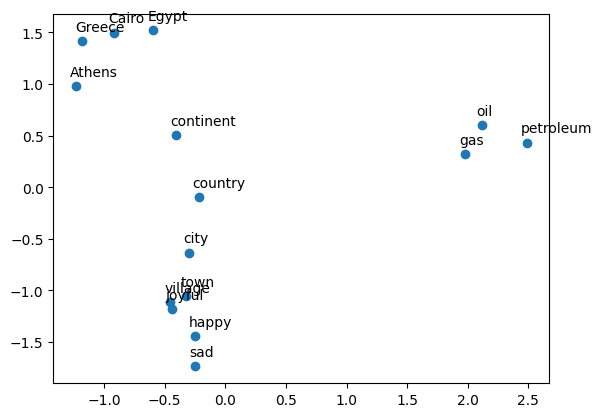

In [ ]:
result = compute_pca(X, 2)
plt.scatter(result[:, 0], result[:, 1])
for i, word in enumerate(words):
    plt.annotate(word, xy=(result[i, 0] - 0.05, result[i, 1] + 0.1))

plt.show()

# **3. Part-of-Speech (POS) Tagging**
Etiquetado gramatical (part-of-speech tagging) y extracción de palabras clave para textos en español. Estos métodos nos ayudarán a analizar oraciones computacionalmente y a entender mejor el contexto de las palabras.

Primero, Importamos spacy y displacy (un módulo especial de spaCy para visualización de dependencias).

In [ ]:
import spacy
from spacy import displacy
from collections import Counter
import pandas as pd

In [ ]:
!python -m spacy download es_core_news_md

     ---------------------------------------- 0.0/42.3 MB ? eta -:--:--
     --------------- ----------------------- 16.8/42.3 MB 96.0 MB/s eta 0:00:01
     ------------------------------------ -- 39.3/42.3 MB 99.9 MB/s eta 0:00:01
     --------------------------------------- 42.3/42.3 MB 95.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')



[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
nlp = spacy.load('es_core_news_md')

## **3.1 Creación de un Documento Procesado**
El primer paso es crear un objeto `document` procesado por spaCy. En esta línea se realiza la mayor parte del trabajo pesado de NLP: identificación de límites de oraciones y asignación de partes de la oración a cada palabra.

In [ ]:
filepath = '.\es.txt'
text = open(filepath, encoding='utf-8').read()
document = nlp(text)

## **3.2 Etiquetas Gramaticales (Part-of-Speech)**
Las etiquetas de spaCy se basan en las [Universal Dependencies](https://universaldependencies.org/) un estándar internacional para que las etiquetas funcionen en múltiples idiomas.

| POS | Description | Examples |
|:-----:|:-------------------------:|:---------------------------------------------:|
| ADJ | Adjetivo: Describe cualidades del sustantivo. | grande, viejo, verde, primero |
| ADP | Adposición: Preposiciones y posposiciones. | en, para, durante, con |
| ADV | Adverbio: Modifica verbos, adjetivos u otros adverbios. | muy, mañana, abajo, donde |
| AUX | Auxiliar: Verbos que acompañan al verbo principal. | es, ha (hecho), debe (hacer) |
| CONJ | Conjunción: Categoría general para conectores. | y, o, pero, si, que |
| CCONJ | Conjunción Coordinante: Une elementos de igual rango. | y, o, pero, ni, sino |
| DET | Determinante: Palabras que limitan o precisan al sustantivo. | un, el, la, los, esta |
| INTJ | Interjección: Expresiones de sentimientos o llamadas. | psss, ay, bravo, hola |
| NOUN | Sustantivo: Nombres de objetos, personas o ideas. | niña, gato, árbol, aire, belleza |
| NUM | Numeral: Expresiones numéricas. | 1, 2017, uno, setenta, IV |
| PART | Partícula: Palabras invariables con función gramatical. | 's, no |
| PRON | Pronombre: Palabras que sustituyen al sustantivo. | yo, tú, él, nosotros, alguien |
| PROPN | Nombre propio: Nombres de entidades específicas. | María, Juan, Madrid, OTAN, HBO |
| PUNCT | Puntuación: Signos ortográficos. | ., (, ), ?, ¡, ¿ |
| SCONJ | Conjunción Subordinante: Une oraciones dependientes. | si, mientras, que, porque |
| SYM | Símbolo: Caracteres especiales. | $, %, ©, +, =, :), 😝 |
| VERB | Verbo: Expresan acciones o estados. | corre, comió, comiendo, comer |
| X | Otro: Palabras no categorizadas o extranjerismos. | sfpksdpsxmsa |
| SPACE | Espacio: Espacios en blanco y saltos de línea. | |



---


**Diferencia técnica:** Mientras que ***CONJ*** se utiliza como una etiqueta general en algunos esquemas antiguos, ***CCONJ*** (Coordinante) se usa específicamente para palabras que vinculan palabras o frases de igual importancia jerárquica (como "pan **y** leche"). Por otro lado, ***SCONJ*** (Subordinante) vincula una cláusula dependiente a una principal (como "Dijo **que** vendría").



In [ ]:
# Iteramos por cada token en el documento procesado
for token in document[:20]: # Limitamos a los primeros 20 para visualización
    # Imprimimos la raíz (lemma), la categoría gramatical (pos) y su función sintáctica (dep)
    print(f"Palabra: {token.text:12} | Raíz: {token.lemma_:12} | Categoría: {token.pos_:6}")

Palabra: ﻿INTRODUCCION | Raíz: ﻿introduccion | Categoría: NOUN  
Palabra: .            | Raíz: .            | Categoría: PUNCT 
Palabra: 


          | Raíz: 


          | Categoría: SPACE 
Palabra: ECONOMÍA     | Raíz: economía     | Categoría: NOUN  
Palabra: POLÍTICA     | Raíz: político     | Categoría: ADJ   
Palabra: .            | Raíz: .            | Categoría: PUNCT 
Palabra: 

           | Raíz: 

           | Categoría: SPACE 
Palabra: El           | Raíz: el           | Categoría: DET   
Palabra: sombrío      | Raíz: sombrío      | Categoría: ADJ   
Palabra: Prudhon      | Raíz: Prudhon      | Categoría: PROPN 
Palabra: ,            | Raíz: ,            | Categoría: PUNCT 
Palabra: imbuído      | Raíz: imbuído      | Categoría: ADJ   
Palabra: ,            | Raíz: ,            | Categoría: PUNCT 
Palabra: sin          | Raíz: sin          | Categoría: ADP   
Palabra: duda         | Raíz: duda         | Categoría: NOUN  
Palabra: ,            | Raíz: ,            | Categorí

## **3.3 Visualización de Estructura Sintáctica**
Utilizamos `displacy` para generar visualizaciones que faciliten la comprensión de la jerarquía de la oración.

In [ ]:
# Visualizamos la estructura sintáctica de una oración específica
# style="dep" muestra el árbol de dependencias
displacy.render(list(document.sents)[0:3], style="dep", jupyter=True, options={'distance': 100})

## **3.4 Análisis Práctico de Categorías**
Extracción de Adjetivos y Verbos

In [ ]:
# Extraemos lemas de adjetivos y verbos únicamente
adjs = [token.lemma_ for token in document if token.pos_ == 'ADJ']
verbs = [token.lemma_ for token in document if token.pos_ == 'VERB']

# Realizamos el conteo de frecuencia individual
adjs_tally = Counter(adjs)
verbs_tally = Counter(verbs)

# Visualizamos el Top 10 de adjetivos en un DataFrame de Pandas
df_adjs = pd.DataFrame(adjs_tally.most_common(10), columns=['Adjetivo', 'Frecuencia'])
display(df_adjs)

,Adjetivo,Frecuencia
0,_,29
1,primero,16
2,solo,16
3,buen,16
4,último,11
5,bello,11
6,jóven,11
7,gran,11
8,fuerte,10
9,pobre,10


In [ ]:
# Visualizamos el Top 10 de verbos en un DataFrame de Pandas
df_verbs = pd.DataFrame(verbs_tally.most_common(10), columns=['Adjetivo', 'Frecuencia'])
display(df_verbs)

,Adjetivo,Frecuencia
0,hacer,55
1,decir,36
2,tener,33
3,dar,26
4,venir,25
5,ver,22
6,saber,20
7,querer,20
8,creer,19
9,hablar,19


## **3.5 Extracción de Palabras Clave en Contexto**

In [ ]:
def buscar_oraciones_clave(palabra_clave, documento):
    # Iteramos por las oraciones identificadas automáticamente por spaCy
    for oracion in documento.sents:
        texto_oracion = oracion.text
        if palabra_clave.lower() in texto_oracion.lower():
            texto_limpio = re.sub('\n', ' ', texto_oracion)
            texto_final = re.sub(f"({palabra_clave})", r"**\1**", texto_limpio, flags=re.IGNORECASE)
            display(Markdown(texto_final))

# Ejemplo de uso
buscar_oraciones_clave(palabra_clave="español", documento=document)


## **3.6 Contexto de Palabras Clave (N-gramas)**
También podemos explorar el contexto más inmediato de una palabra clave —sus palabras vecinas a la izquierda y a la derecha— y podemos ajustar nuestra búsqueda utilizando el etiquetado POS.

Para hacerlo, primero crearemos una lista de lo que se denomina ngrams. Los "Ngrams" son cualquier secuencia de n tokens en un texto. Son un concepto fundamental en lingüística computacional y NLP.

A continuación, crearemos una lista de bigramas, es decir, todas las combinaciones de dos palabras del texto de muestra. Utilizaremos estos bigramas para encontrar las palabras vecinas que aparecen junto a palabras clave particulares.

In [ ]:
# Creamos una lista de tokens y etiquetas POS del documento si el token es una palabra
tokens_and_labels = [(token.text, token.pos_) for token in document if token.is_alpha]

# Función para obtener todas las combinaciones de N palabras consecutivas
def get_bigrams(word_list, number_consecutive_words=2):
    ngrams = []
    adj_length_of_word_list = len(word_list) - (number_consecutive_words - 1)

    # Iteramos desde 0 hasta la longitud ajustada de la lista de palabras
    for word_index in range(adj_length_of_word_list):
        # Indexamos la lista en cada número, tomando la palabra en ese índice y las N siguientes
        ngram = word_list[word_index : word_index + number_consecutive_words]
        # Añadimos este combo de palabras a la lista maestra "ngrams"
        ngrams.append(ngram)

    return ngrams

bigrams = get_bigrams(tokens_and_labels)

# Echamos un vistazo a los bigramas generados
bigrams[5:20]

[[('imbuído', 'ADJ'), ('sin', 'ADP')],
 [('sin', 'ADP'), ('duda', 'NOUN')],
 [('duda', 'NOUN'), ('en', 'ADP')],
 [('en', 'ADP'), ('las', 'DET')],
 [('las', 'DET'), ('ideas', 'NOUN')],
 [('ideas', 'NOUN'), ('de', 'ADP')],
 [('de', 'ADP'), ('los', 'DET')],
 [('los', 'DET'), ('Santos', 'PROPN')],
 [('Santos', 'PROPN'), ('Padres', 'PROPN')],
 [('Padres', 'PROPN'), ('de', 'ADP')],
 [('de', 'ADP'), ('la', 'DET')],
 [('la', 'DET'), ('Iglesia', 'PROPN')],
 [('Iglesia', 'PROPN'), ('que', 'PRON')],
 [('que', 'PRON'), ('predicaban', 'VERB')],
 [('predicaban', 'VERB'), ('el', 'DET')]]

Ahora que tenemos nuestra lista de bigramas, crearemos la función `get_neighbor_words()`. Esta función devolverá las palabras más frecuentes que aparecen junto a una palabra clave específica. La función también se puede ajustar para devolver palabras vecinas que coincidan con una determinada categoría gramatical cambiando el parámetro `pos_label`.

In [ ]:
def get_neighbor_words(keyword, bigrams, pos_label = None):
    neighbor_words = []
    keyword = keyword.lower()

    for bigram in bigrams:
        # Extraemos solo las palabras en minúsculas (sin las etiquetas) para cada bigrama
        words = [word.lower() for word, label in bigram]

        # Comprobamos si la palabra clave está en el bigrama
        if keyword in words:
            for word, label in bigram:
                # Nos enfocamos en la palabra vecina, no en la palabra clave
                if word.lower() != keyword:
                    # Si la palabra vecina coincide con la etiqueta POS correcta (o no se especifica ninguna)
                    if label == pos_label or pos_label == None:
                        neighbor_words.append(word.lower())

    return Counter(neighbor_words).most_common()

# Ejemplo: Buscar vecinos de la palabra "bien"
get_neighbor_words("bien", bigrams)

# Ejemplo: Buscar vecinos de "bien" que sean específicamente verbos
get_neighbor_words("bien", bigrams, pos_label='VERB')

[('duerme', 1), ('charlábamos', 1)]

## **3.7 Tu Turno**
Prueba las funciones anteriores con tus propias palabras de interés para explorar el corpus y entender cómo se comportan gramaticalmente.

In [ ]:
# Ejemplo: Busca oraciones con tu propia palabra clave personalizada
buscar_oraciones_clave(palabra_clave="TU_PALABRA", documento=document)

# Ejemplo: Busca vecinos para una palabra clave específica
get_neighbor_words(keyword="TU_PALABRA", bigrams=bigrams, pos_label=None)

# Ejemplo: Conteo de sustantivos propios (PROPN)
prop_nouns = [t.text for t in document if t.pos_ == 'PROPN']
print(Counter(prop_nouns).most_common(10))


[('Mauricio', 122), ('Julia', 27), ('Ridel', 18), ('Buenos', 16), ('Aires', 16), ('Renata', 12), ('»', 11), ('«', 10), ('Cárlos', 10), ('Dios', 8)]


# **4. Named Entity Recognition (NER)**
Reconocimiento de Entidades Nombradas (NER, por sus siglas en inglés) aplicado al español. Este método nos ayudará a identificar computacionalmente personas, lugares y organizaciones en un texto o colección de textos.

## **4.1 Dataset y Contexto**
El texto de ejemplo utilizado para el análisis en español es [Oasis en la vida ](https://www.gutenberg.org/ebooks/62564)de Juana Manuela Gorriti.

Es importante notar que, al comparar los resultados con modelos en inglés, el NER en español a veces presenta mayores dificultades para distinguir tipos específicos de entidades (como diferenciar entre una Organización y una Localización). Esto se debe a que los modelos requieren una enorme cantidad de datos etiquetados para alcanzar una precisión perfecta; actualmente, el modelo de inglés es uno de los más robustos en esta distinción.

In [ ]:
# Visualización previa del etiquetado NER en el documento
# Esto resaltará visualmente las entidades detectadas por spaCy
displacy.render(document, style="ent", jupyter=True)


## **4.2 Preparación**
Importar Librerías

In [ ]:
import spacy
from spacy import displacy
from collections import Counter
import pandas as pd

# Configuramos pandas para visualizar mejor los resultados tabulares
pd.options.display.max_rows = 600
pd.options.display.max_colwidth = 400

### Descargar y Cargar el Modelo de Lenguaje

Utilizaremos el modelo medio para español. Puedes consultar las fuentes de entrenamiento en la página oficial de [modelos de spaCy](https://spacy.io/models/es).

In [ ]:
# Descargamos el modelo de noticias en español
!python -m spacy download es_core_news_md

# Cargamos el modelo como un objeto nlp
import es_core_news_md
nlp = es_core_news_md.load()



[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached https://github.com/explosion/spacy-models/releases/download/es_core_news_md-3.8.0/es_core_news_md-3.8.0-py3-none-any.whl (42.3 MB)
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')


## **4.3 Procesamiento del Documento**
El paso fundamental es procesar el texto con nuestro modelo cargado. El objeto `document` resultante contendrá toda la información lingüística necesaria.

In [ ]:
# Definimos la ruta del archivo y procesamos el contenido
filepath = './es.txt'
text = open(filepath, encoding='utf-8').read()
document = nlp(text)

# Acceso rápido a todas las entidades encontradas
document.ents

(﻿INTRODUCCION,
 ECONOMÍA POLÍTICA,
 Prudhon,
 imbuído,
 Santos
 Padres de la Iglesia,
 teorías,
 La industria,
 VACA-GUZMAN,
 OASIS,
 OASIS,
 I,
 Mauricio Ridel,
 Fin,
 Mauricio,
 copas de los árboles,
 Enrique,
 María,
 á Dios,
 »--¿Muere?,
 --¡Perdon!--se,
 Mauricio.--La,
 trabajo!--replicó,
 Catorce horas,
 Un poco de sueño,
 Hablando,
 Mauricio,
 Diez horas! ¡Ah! hombres,
 Redaccion,
 Emilio,
 Sábelo,
 Mauricio,
 Suma,
 Mauricio,
 Emilio,
 ánsia,
 fruicion!--exclamó:--¿qué,
 Mauricio,
 Uncido,
 Enigma,
 Emilio,
 Mauricio,
 Cárlos Ridel,
 Mauricio,
 Europa,
 Francia,
 Paris,
 La bondad característica de los hijos de aquella tierra,
 sábio Blain,
 Colombe,
 Los exámenes,
 .....,
 Sagrado Libro y jura ser virtuoso y bueno,
 Mauricio,
 Mr,
 Blain,
 Colombe,
 Notre Dame du bon Secour,
 Envíaselo,
 carta.--,
 Colombe,
 La luz de un lejano recuerdo,
 Sonrióle,
 Colombe,
 Besó,
 guardóla,
 Mauricio,
 A la
 inquieta turbulencia del niño,
 Allons enfants de la patrie,
 Mauricio,
 Allá,
 Mau

## **4.4 Extracción de Entidades Específicas**
Cada entidad en `document.ents` contiene información sobre el texto original y su etiqueta (*label*). Podemos filtrar estas entidades utilizando bucles `for` y condicionales `if`.

### Listar todas las entidades y sus tipos

In [ ]:
# Iteramos por cada entidad detectada para ver su categoría
for named_entity in document.ents:
    print(f"Entidad: {named_entity.text:25} | Etiqueta: {named_entity.label_}")


Entidad: ﻿INTRODUCCION             | Etiqueta: MISC
Entidad: ECONOMÍA POLÍTICA         | Etiqueta: MISC
Entidad: Prudhon                   | Etiqueta: LOC
Entidad: imbuído                   | Etiqueta: LOC
Entidad: Santos
Padres de la Iglesia | Etiqueta: ORG
Entidad: teorías                   | Etiqueta: PER
Entidad: La industria              | Etiqueta: MISC
Entidad: VACA-GUZMAN               | Etiqueta: ORG
Entidad: OASIS                     | Etiqueta: ORG
Entidad: OASIS                     | Etiqueta: ORG
Entidad: I                         | Etiqueta: MISC
Entidad: Mauricio Ridel            | Etiqueta: PER
Entidad: Fin                       | Etiqueta: MISC
Entidad: Mauricio                  | Etiqueta: LOC
Entidad: copas de los árboles      | Etiqueta: MISC
Entidad: Enrique                   | Etiqueta: PER
Entidad: María                     | Etiqueta: PER
Entidad: á Dios                    | Etiqueta: PER
Entidad: »--¿Muere?                | Etiqueta: MISC
Entidad: --¡Perdon!--s

### Filtrar solo por Personas (PER)

In [ ]:
# Extraemos únicamente los nombres de personas identificados
for named_entity in document.ents:
    if named_entity.label_ == "PER":
        print(named_entity.text)

teorías
Mauricio Ridel
Enrique
María
á Dios
--¡Perdon!--se
Hablando
Mauricio
Emilio
Mauricio
Mauricio
Emilio
fruicion!--exclamó:--¿qué
Mauricio
Uncido
Emilio
Cárlos Ridel
Mauricio
Paris
sábio Blain
Mauricio
Mr
Blain
Sonrióle
Colombe
Besó
guardóla
Mauricio
Mauricio
Cárlos
  Ridel
Mauricio Ridel
Ridel
V.
réstame
Mauricio
Paris
Arrojóse
Paris
Valerio--su
Mauricio
Vd.
sócio bribon
sócio
Ridel
Cárlos Ridel
Mauricio
Cárlos Ridel
Había
Vd.
Mauricio
Mauricio
Blain
Colombe
Paris
Mauricio
Lloraba
.....


Acojido
abrióse
Sr. Santa Coloma
Vice-Cónsul Argentino
Julia
Rendidos
Julia Lopez
Dios
Mauricio
Julia Lopez
Mauricio
Mauricio
Mauricio
Julia
Lopez
Mauricio
Vice-Cónsul
Mauricio
amargura.--Sí
Mauricio
Mauricio
Mauricio
madame Bazan
Madame Bazan
Mauricio
Capricho
madame Bazan
Mauricio
Mauricio
damasco azul
Mauricio
madame Bazan
Mauricio
Mauricio
Mauricio
Steinway
Mauricio
Ora
Mauricio
Mauricio
Paris
Jesucristo
Paris
Barrieres
madame Arnaud
Mauricio
Renata
Renata déme Vd.
Julia Lopez
Mauricio
Renat

## **4.5 Procesamiento de Textos Largos (Chunking)**
Cuando trabajamos con libros completos o colecciones masivas, es más eficiente dividir el texto en fragmentos (*chunks*) y utilizar `nlp.pipe` para procesarlos de forma optimizada.

In [ ]:
import math

# Definimos el número de fragmentos
number_of_chunks = 80
chunk_size = math.ceil(len(text) / number_of_chunks)

text_chunks = []
for number in range(0, len(text), chunk_size):
    text_chunk = text[number:number+chunk_size]
    text_chunks.append(text_chunk)

# Procesamos los fragmentos de forma eficiente
chunked_documents = list(nlp.pipe(text_chunks))

## **4.6 Análisis Estadístico de Entidades**
Podemos cuantificar la presencia de personajes (PER) o lugares (LOC) para obtener una visión general del contenido del texto.

### Conteo de Personajes

In [ ]:
people = []
for doc in chunked_documents:
    for ent in doc.ents:
        if ent.label_ == "PER":
            people.append(ent.text)

# Creamos una tabla con los personajes más mencionados
people_tally = Counter(people)
df_people = pd.DataFrame(people_tally.most_common(), columns=['Personaje', 'Menciones'])
df_people.head(20)

,Personaje,Menciones
0,Mauricio,76
1,Julia,19
2,Cárlos Ridel,10
3,Renata,7
4,Paris,6
5,Jesús,5
6,Emilio,4
7,Ridel,4
8,Vd.,4
9,Julia Lopez,4


### Conteo de Lugares

In [ ]:
places = []
for doc in chunked_documents:
    for ent in doc.ents:
        if ent.label_ == "LOC":
            places.append(ent.text)

# Tabla de las localizaciones más frecuentes
places_tally = Counter(places)
df_places = pd.DataFrame(places_tally.most_common(), columns=['Lugar', 'Menciones'])
df_places.head(20)

,Lugar,Menciones
0,Mauricio,33
1,Buenos Aires,12
2,Francia,4
3,Burdeos,4
4,Senegal,4
5,Rio Janeiro,4
6,Colombe,3
7,Sanabria,3
8,ánsia,2
9,Europa,2


## **4.7 NER en Contexto**
Esta función avanzada permite buscar una palabra clave dentro de las entidades y mostrar la oración completa donde aparece, resaltando la entidad y su categoría.

In [ ]:
from IPython.display import Markdown, display
import re

def obtener_ner_en_contexto(keyword, document, labels_deseados=False):
    # Si no se especifican etiquetas, usamos todas las disponibles en el modelo
    if not labels_deseados:
        labels_deseados = list(nlp.get_pipe('ner').labels)

    # Iteramos por las oraciones del documento
    for sentence in document.sents:
        sentence_doc = nlp(sentence.text)
        for ent in sentence_doc.ents:
            # Verificamos si la palabra clave está en la entidad y si el tipo es el deseado
            if keyword.lower() in ent.text.lower() and ent.label_ in labels_deseados:

                # Limpiamos y resaltamos el texto
                texto_final = re.sub('\n', ' ', sentence.text)
                texto_final = re.sub(f"{ent.text}", f"**{ent.text}**", texto_final, flags=re.IGNORECASE)

                print('---')
                display(Markdown(f"Categoría: **{ent.label_}**"))
                display(Markdown(texto_final))


In [ ]:
# Ejemplo de uso: Buscamos el contexto de la entidad "Francia"
for doc in chunked_documents:
    obtener_ner_en_contexto('Francia', doc)

---


Categoría: **LOC**

Por dicha suya fué el «bello país de **Francia**,» la hospitalaria Paris, el lugar de su destierro.  

---


Categoría: **LOC**

Sin embargo, Mauricio amaba tambien la **Francia**.  

... (2 outputs left out)

Quizá es de **Francia**.

---


Categoría: **LOC**

--A **Francia**, amada mia, para pedir al sepulcro los restos que lloras y devolverlos á la tierra de la patria.  

# **5. Traduccion**:
En esta sección exploraremos cómo el Procesamiento de Lenguaje Natural puede utilizarse para traducir texto entre diferentes idiomas. Comenzaremos con un enfoque fundamental basado en la alineación de espacios vectoriales de palabras.

## **5.1 Naive Machine Translation**
La idea central de este método es que, si tenemos representaciones vectoriales (embeddings) de palabras en dos idiomas distintos (por ejemplo, inglés y francés), existe una transformación lineal que puede mapear un espacio al otro. Esto se basa en la premisa de que las relaciones semánticas entre palabras son similares a través de las culturas e idiomas.


### Configuración Inicial y Librerías
Primero, importamos las herramientas necesarias para el manejo de vectores, visualización y procesamiento de lenguaje.

In [ ]:
import pdb
import pickle
import string
import time
import gensim
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import scipy
import sklearn
from gensim.models import KeyedVectors
from nltk.corpus import stopwords, twitter_samples
from nltk.tokenize import TweetTokenizer

In [ ]:
# Funciones de utilidad
def get_dict(file_name):
    my_file = pd.read_csv(file_name, delimiter=' ', header=None)
    etof = {}
    for i in range(len(my_file)):
        # Usar iloc en lugar de loc para indexación posicional
        en = my_file.iloc[i][0]
        fr = my_file.iloc[i][1]
        etof[en] = fr
    return etof

In [ ]:
# Descargamos los vectores de palabras en francés
#!curl -o ./wiki.multi.fr.vec [https://dl.fbaipublicfiles.com/arrival/vectors/wiki.multi.fr.vec](https://dl.fbaipublicfiles.com/arrival/vectors/wiki.multi.fr.vec)

### Carga de Diccionarios y Embeddings
Cargamos los modelos pre-entrenados de Google News (inglés) y Wiki (francés) para obtener la representación numérica de las palabras.

In [ ]:
from gensim.models import KeyedVectors

# Cargamos los embeddings (este paso requiere que los archivos existan en la ruta)
en_embeddings = KeyedVectors.load_word2vec_format('.\GoogleNews-vectors-negative300.bin', binary=True)
fr_embeddings = KeyedVectors.load_word2vec_format('.\wiki.multi.fr.vec')

25792 | INFO | loading projection weights from .\GoogleNews-vectors-negative300.bin
25792 | INFO | KeyedVectors lifecycle event {'msg': 'loaded (3000000, 300) matrix of type float32 from .\\GoogleNews-vectors-negative300.bin', 'binary': True, 'encoding': 'utf8', 'datetime': '2026-02-27T09:02:52.602368', 'gensim': '4.4.0', 'python': '3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'event': 'load_word2vec_format'}
25792 | INFO | loading projection weights from .\wiki.multi.fr.vec
25792 | INFO | KeyedVectors lifecycle event {'msg': 'loaded (200000, 300) matrix of type float32 from .\\wiki.multi.fr.vec', 'binary': False, 'encoding': 'utf8', 'datetime': '2026-02-27T09:03:22.084417', 'gensim': '4.4.0', 'python': '3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'event': 'load_word2vec_format'}


In [ ]:
# Cargamos los diccionarios de entrenamiento y prueba
en_fr_train = get_dict('en-fr.train.txt')
en_fr_test = get_dict('en-fr.test.txt')

# Filtramos los embeddings para incluir solo las palabras presentes en nuestros diccionarios
english_set = set(en_embeddings.index_to_key)
french_set = set(fr_embeddings.index_to_key)
en_embeddings_subset = {}
fr_embeddings_subset = {}

for en_word, fr_word in en_fr_train.items():
    if fr_word in french_set and en_word in english_set:
        en_embeddings_subset[en_word] = en_embeddings[en_word]
        fr_embeddings_subset[fr_word] = fr_embeddings[fr_word]

import os

# Crear la carpeta si no existe
os.makedirs("Modelos Entrenados", exist_ok=True)

# Guardamos los subconjuntos procesados para agilizar cargas futuras
pickle.dump(en_embeddings_subset, open("Modelos Entrenados/en_embeddings.p", "wb"))
pickle.dump(fr_embeddings_subset, open("Modelos Entrenados/fr_embeddings.p", "wb"))


#### Cargar despues de reducir

In [ ]:
en_embeddings_subset = pickle.load(open("Modelos Entrenados/en_embeddings.p", "rb"))
fr_embeddings_subset = pickle.load(open("Modelos Entrenados/fr_embeddings.p", "rb"))

In [ ]:
en_fr_train = get_dict('en-fr.train.txt')
print('The length of the English to French training dictionary is', len(en_fr_train))
en_fr_test = get_dict('en-fr.test.txt')
print('The length of the English to French test dictionary is', len(en_fr_train))

The length of the English to French training dictionary is 5000
The length of the English to French test dictionary is 5000


### **Parte 1: Generar matrices de incrustación y transformación**

Implementamos la función `get_matrices` para organizar nuestros datos en matrices $X$ e $Y$, donde cada fila es el vector de una palabra en su respectivo idioma.

In [ ]:
def get_matrices(en_fr, french_vecs, english_vecs):
    X_l = list()
    Y_l = list()

    # Detectamos si es un KeyedVectors de Gensim o un diccionario normal
    if hasattr(english_vecs, 'index_to_key'):
        english_set = set(english_vecs.index_to_key)
    else:
        english_set = set(english_vecs.keys())

    if hasattr(french_vecs, 'index_to_key'):
        french_set = set(french_vecs.index_to_key)
    else:
        french_set = set(french_vecs.keys())

    # Emparejamos los vectores según el diccionario
    for en_word, fr_word in en_fr.items():
        if fr_word in french_set and en_word in english_set:
            X_l.append(english_vecs[en_word])
            Y_l.append(french_vecs[fr_word])

    # Convertimos las listas en matrices de NumPy
    X = np.vstack(X_l)
    Y = np.vstack(Y_l)
    return X, Y

# Generamos las matrices de entrenamiento
X_train, Y_train = get_matrices(en_fr_train, fr_embeddings_subset, en_embeddings_subset)

### **Parte 2: La traducción como transformación lineal**

Buscamos una matriz de transformación $R$ tal que al multiplicar un vector de inglés $e$ por $R$, obtengamos un vector $f$ que se aproxime al vector real en francés.

#### **Minimización y Función de Pérdida**
Buscamos minimizar la diferencia entre la transformación $XR$ y el objetivo real $Y$ mediante la Norma de Frobenius:


$$ \frac{1}{m} \| \mathbf{X R} - \mathbf{Y} \|_{F}^{2} $$

In [ ]:
def compute_loss(X, Y, R):
    """
    Calcula la pérdida cuadrática media basada en la norma de Frobenius.
    """
    m = X.shape[0] # Número de ejemplos
    # Calculamos la diferencia residual
    diff = np.dot(X, R) - Y
    # Elevamos al cuadrado elemento por elemento y sumamos
    loss = np.sum(diff**2) / m
    return loss

def compute_gradient(X, Y, R):
    """
    Calcula el gradiente de la pérdida respecto a R.
    Formula: (2/m) * X^T * (XR - Y)
    """
    m = X.shape[0]
    # Aplicamos la derivada matricial para obtener la dirección del descenso
    gradient = np.dot(X.transpose(), np.dot(X, R) - Y) * (2/m)
    return gradient

def align_embeddings(X, Y, train_steps=100, learning_rate=0.0003):
    """
    Alinea los espacios vectoriales mediante descenso de gradiente.
    """
    np.random.seed(129)
    # Inicializamos R con valores aleatorios
    R = np.random.rand(X.shape[1], X.shape[1])

    for i in range(train_steps):
        if i % 25 == 0:
            print(f"Pérdida en iteración {i}: {compute_loss(X, Y, R):.4f}")

        # Actualizamos R en la dirección opuesta al gradiente
        gradient = compute_gradient(X, Y, R)
        R -= learning_rate * gradient
    return R

# Entrenamos la matriz de transformación
R_train = align_embeddings(X_train, Y_train, train_steps=400, learning_rate=0.8)


Pérdida en iteración 0: 963.0146
Pérdida en iteración 25: 97.8292
Pérdida en iteración 50: 26.8329
Pérdida en iteración 75: 9.7893
Pérdida en iteración 100: 4.3776
Pérdida en iteración 125: 2.3281
Pérdida en iteración 150: 1.4480
Pérdida en iteración 175: 1.0338
Pérdida en iteración 200: 0.8251
Pérdida en iteración 225: 0.7145
Pérdida en iteración 250: 0.6534
Pérdida en iteración 275: 0.6185
Pérdida en iteración 300: 0.5981
Pérdida en iteración 325: 0.5858
Pérdida en iteración 350: 0.5782
Pérdida en iteración 375: 0.5735


### **Parte 3: Evaluación de la Traducción**

Para traducir una palabra, multiplicamos su vector por $R$ y buscamos el vecino más cercano (**k-Nearest Neighbors**) en el espacio francés utilizando la **Similitud Coseno**.

In [ ]:
def nearest_neighbor(v, candidates, k=1):
    """
    Busca los k vectores más similares en la matriz de candidatos
    usando operaciones vectorizadas de NumPy para máxima velocidad.
    """
    # 1. Producto punto de v contra TODAS las filas de candidates al mismo tiempo
    dot_products = np.dot(candidates, v)

    # 2. Calculamos la norma de v
    norm_v = np.linalg.norm(v)

    # 3. Calculamos la norma de todas las filas de candidates de golpe (axis=1)
    norms_candidates = np.linalg.norm(candidates, axis=1)

    # 4. Calculamos la similitud coseno para todos los candidatos
    cos_sims = dot_products / (norm_v * norms_candidates)

    # 5. Obtenemos los índices ordenados y devolvemos los k más altos
    sorted_ids = np.argsort(cos_sims)

    return sorted_ids[-k:]

def test_vocabulary(X, Y, R):
    """
    Calcula la precisión del modelo en el conjunto de prueba.
    """
    pred = np.dot(X, R)
    num_correct = 0

    for i in range(len(pred)):
        # Obtenemos el vecino más cercano para la predicción
        pred_idx = nearest_neighbor(pred[i], Y)
        # Si el índice coincide con el real, la traducción es correcta
        if pred_idx == i:
            num_correct += 1

    return num_correct / len(pred)

# Evaluación final en el conjunto de test
X_val, Y_val =  get_matrices(en_fr_test, fr_embeddings, en_embeddings)
acc = test_vocabulary(X_val, Y_val, R_train)
print(f"Precisión en el conjunto de prueba: {acc:.3f}")


Precisión en el conjunto de prueba: 0.556


## **5.2 Traducción Automática Neuronal (NMT)**
En esta sección, implementaremos un modelo de traducción automática neuronal (Neural Machine Translation) para traducir frases del Inglés al Español. Utilizaremos una arquitectura de redes recurrentes basada en GRU (Gated Recurrent Units) con un esquema de Codificador (Encoder) y Decodificador (Decoder).

A diferencia de los métodos estadísticos o simples, los modelos NMT procesan oraciones completas y aprenden representaciones semánticas profundas, lo que permite traducciones mucho más fluidas y contextuales.

### **Configuración e Importación de Librerías**
Preparamos el entorno con las herramientas de Deep Learning necesarias, principalmente TensorFlow y Keras, para construir nuestra red neuronal.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import re
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Detect GPU natively
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

Using device: cuda
NVIDIA GeForce RTX 5060 Ti


### **Parte 1: Conjunto de Datos**
Utilizaremos el conjunto de datos de [Europarl](http://www.statmt.org/europarl/), que contiene pares de oraciones extraídas de las actas del Parlamento Europeo. Es un recurso fundamental en la investigación de traducción automática.



In [ ]:
import sys
import os
import urllib.request
import tarfile
import zipfile

########################################################################


def _print_download_progress(count, block_size, total_size):
    """
    Function used for printing the download progress.
    Used as a call-back function in maybe_download_and_extract().
    """

    # Percentage completion.
    pct_complete = float(count * block_size) / total_size

    # Limit it because rounding errors may cause it to exceed 100%.
    pct_complete = min(1.0, pct_complete)

    # Status-message. Note the \r which means the line should overwrite itself.
    msg = "\r- Download progress: {0:.1%}".format(pct_complete)

    # Print it.
    sys.stdout.write(msg)
    sys.stdout.flush()


########################################################################

def download(base_url, filename, download_dir):
    """
    Download the given file if it does not already exist in the download_dir.

    :param base_url: The internet URL without the filename.
    :param filename: The filename that will be added to the base_url.
    :param download_dir: Local directory for storing the file.
    :return: Nothing.
    """

    # Path for local file.
    save_path = os.path.join(download_dir, filename)

    # Check if the file already exists, otherwise we need to download it now.
    if not os.path.exists(save_path):
        # Check if the download directory exists, otherwise create it.
        if not os.path.exists(download_dir):
            os.makedirs(download_dir)

        print("Downloading", filename, "...")

        # Download the file from the internet.
        url = base_url + filename
        file_path, _ = urllib.request.urlretrieve(url=url,
                                                  filename=save_path,
                                                  reporthook=_print_download_progress)

        print(" Done!")


def maybe_download_and_extract(url, download_dir):
    """
    Download and extract the data if it doesn't already exist.
    Assumes the url is a tar-ball file.

    :param url:
        Internet URL for the tar-file to download.
        Example: "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"

    :param download_dir:
        Directory where the downloaded file is saved.
        Example: "data/CIFAR-10/"

    :return:
        Nothing.
    """

    # Filename for saving the file downloaded from the internet.
    # Use the filename from the URL and add it to the download_dir.
    filename = url.split('/')[-1]
    file_path = os.path.join(download_dir, filename)

    # Check if the file already exists.
    # If it exists then we assume it has also been extracted,
    # otherwise we need to download and extract it now.
    if not os.path.exists(file_path):
        # Check if the download directory exists, otherwise create it.
        if not os.path.exists(download_dir):
            os.makedirs(download_dir)

        # Download the file from the internet.
        file_path, _ = urllib.request.urlretrieve(url=url,
                                                  filename=file_path,
                                                  reporthook=_print_download_progress)

        print()
        print("Download finished. Extracting files.")

        if file_path.endswith(".zip"):
            # Unpack the zip-file.
            zipfile.ZipFile(file=file_path, mode="r").extractall(download_dir)
        elif file_path.endswith((".tar.gz", ".tgz")):
            # Unpack the tar-ball.
            tarfile.open(name=file_path, mode="r:gz").extractall(download_dir)

        print("Done.")
    else:
        print("Data has apparently already been downloaded and unpacked.")

In [ ]:
import os
data_dir = "data/europarl/"

# Base-URL for the data-sets on the internet.
data_url = "http://www.statmt.org/europarl/v7/"

def maybe_download_and_extract_2(language_code="da"):
    """
    Download and extract the Europarl data-set if the data-file doesn't
    already exist in data_dir. The data-set is for translating between
    English and the given language-code (e.g. 'da' for Danish, see the
    list of available language-codes above).
    """

    # Create the full URL for the file with this data-set.
    url = data_url + language_code + "-en.tgz"

    maybe_download_and_extract(url=url, download_dir=data_dir)


def load_data(english=True, language_code="da", start="", end=""):
    """
    Load the data-file for either the English-language texts or
    for the other language (e.g. "da" for Danish).

    All lines of the data-file are returned as a list of strings.

    :param english:
      Boolean whether to load the data-file for
      English (True) or the other language (False).

    :param language_code:
      Two-char code for the other language e.g. "da" for Danish.
      See list of available codes above.

    :param start:
      Prepend each line with this text e.g. "ssss " to indicate start of line.

    :param end:
      Append each line with this text e.g. " eeee" to indicate end of line.

    :return:
      List of strings with all the lines of the data-file.
    """

    if english:
        # Load the English data.
        filename = "europarl-v7.{0}-en.en".format(language_code)
    else:
        # Load the other language.
        filename = "europarl-v7.{0}-en.{0}".format(language_code)

    # Full path for the data-file.
    path = os.path.join(data_dir, filename)

    # Open and read all the contents of the data-file.
    with open(path, encoding="utf-8") as file:
        # Read the line from file, strip leading and trailing whitespace,
        # prepend the start-text and append the end-text.
        texts = [start + line.strip() + end for line in file]

    return texts

#### La lista de idiomas soportados actualmente y sus códigos son los siguientes:
* bg - Bulgaro      
* cs - Checo
* da - Danes
* de - Aleman
* el - Griego
* es - Español
* et - Estonio
* fi - Finlandes
* fr - Frances
* hu - Hungaro
* it - Italiano
* lt - Lituano
* lv - Leton
* nl - Holandes
* pl - Polaco
* pt - Portugues
* ro - Rumano
* sk - Eslovaco
* sl - Esloveno
* sv - Sueco

In [ ]:
language_code='es'

Para que el decodificador sepa cuándo comenzar y terminar una oración, debemos marcar el comienzo y el final de cada oración con palabras que probablemente no aparezcan en el conjunto de datos.

In [ ]:
mark_start = 'ssss '
mark_end = ' eeee'

In [ ]:
maybe_download_and_extract_2(language_code=language_code)

Data has apparently already been downloaded and unpacked.


Cargue los textos para el idioma de origen, aquí usamos Español. y Cargue los textos para el idioma de destino, aquí usamos inglés.

In [ ]:
data_src = load_data(english=False,language_code=language_code)
data_dest = load_data(english=True,
                               language_code=language_code,
                               start=mark_start,
                               end=mark_end)

#### Datos de ejemplo

Los datos son solo una lista de textos que se ordenan para que coincidan los textos de origen y destino.

In [ ]:
idx = 2
print(data_src[idx])
print(data_dest[idx])

Como todos han podido comprobar, el gran "efecto del año 2000" no se ha producido. En cambio, los ciudadanos de varios de nuestros países han sido víctimas de catástrofes naturales verdaderamente terribles.
ssss Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful. eeee


### **Parte 2: Tokenización y Secuenciación**

Las redes neuronales no procesan texto directamente. Primero convertimos las palabras en tokens enteros. Usaremos un vocabulario limitado a las 10,000 palabras más frecuentes para optimizar la memoria.

In [ ]:
class PyTorchTokenizer:
    def __init__(self, num_words=10000):
        self.num_words = num_words
        # 0 is padding, 1 is unknown word
        self.word2idx = {'<pad>': 0, '<unk>': 1}
        self.idx2word = {0: '<pad>', 1: '<unk>'}
        self.vocab_size = 2
        self.max_tokens = 0

    def clean_text(self, text):
        text = text.lower()
        text = re.sub(r"[^\w\s]", "", text) # Remove basic punctuation
        return text.split()

    def fit_on_texts(self, texts):
        counter = Counter()
        for text in texts:
            counter.update(self.clean_text(text))

        # Keep only the most common words
        for word, _ in counter.most_common(self.num_words - 2):
            self.word2idx[word] = self.vocab_size
            self.idx2word[self.vocab_size] = word
            self.vocab_size += 1

    def texts_to_sequences(self, texts, reverse=False, padding='post'):
        sequences = []
        for text in texts:
            words = self.clean_text(text)
            if reverse:
                words = list(reversed(words))
            # Convert to indices, fallback to <unk> (1) if not found
            seq = [self.word2idx.get(w, 1) for w in words]
            sequences.append(seq)

        # Calculate max length based on mean + 2*std
        lengths = [len(s) for s in sequences]
        self.max_tokens = int(np.mean(lengths) + 2 * np.std(lengths))

        # Pad or truncate sequences
        padded = []
        for seq in sequences:
            if len(seq) > self.max_tokens:
                seq = seq[:self.max_tokens] if padding == 'post' else seq[-self.max_tokens:]
            else:
                pad_len = self.max_tokens - len(seq)
                if padding == 'post':
                    seq = seq + [0] * pad_len
                else:
                    seq = [0] * pad_len + seq
            padded.append(seq)
        return np.array(padded)

# Create Tokenizers
num_words = 10000
tokenizer_src = PyTorchTokenizer(num_words=num_words)
tokenizer_src.fit_on_texts(data_src)

tokenizer_dest = PyTorchTokenizer(num_words=num_words)
tokenizer_dest.fit_on_texts(data_dest)

# Get tokens for special markers
token_start = tokenizer_dest.word2idx['ssss']
token_end = tokenizer_dest.word2idx['eeee']

# Process the data
# Truncating to 300,000 sentences as you did previously to save memory
tokens_src = tokenizer_src.texts_to_sequences(data_src[:300000], reverse=True, padding='pre')
tokens_dest = tokenizer_dest.texts_to_sequences(data_dest[:300000], reverse=False, padding='post')

encoder_input_data = tokens_src
decoder_input_data = tokens_dest[:, :-1]
decoder_output_data = tokens_dest[:, 1:]

### **Parte 3: Arquitectura del Modelo (Encoder-Decoder)**

Utilizamos la API funcional de Keras para conectar el Encoder (que procesa la frase original) con el Decoder (que genera la traducción).

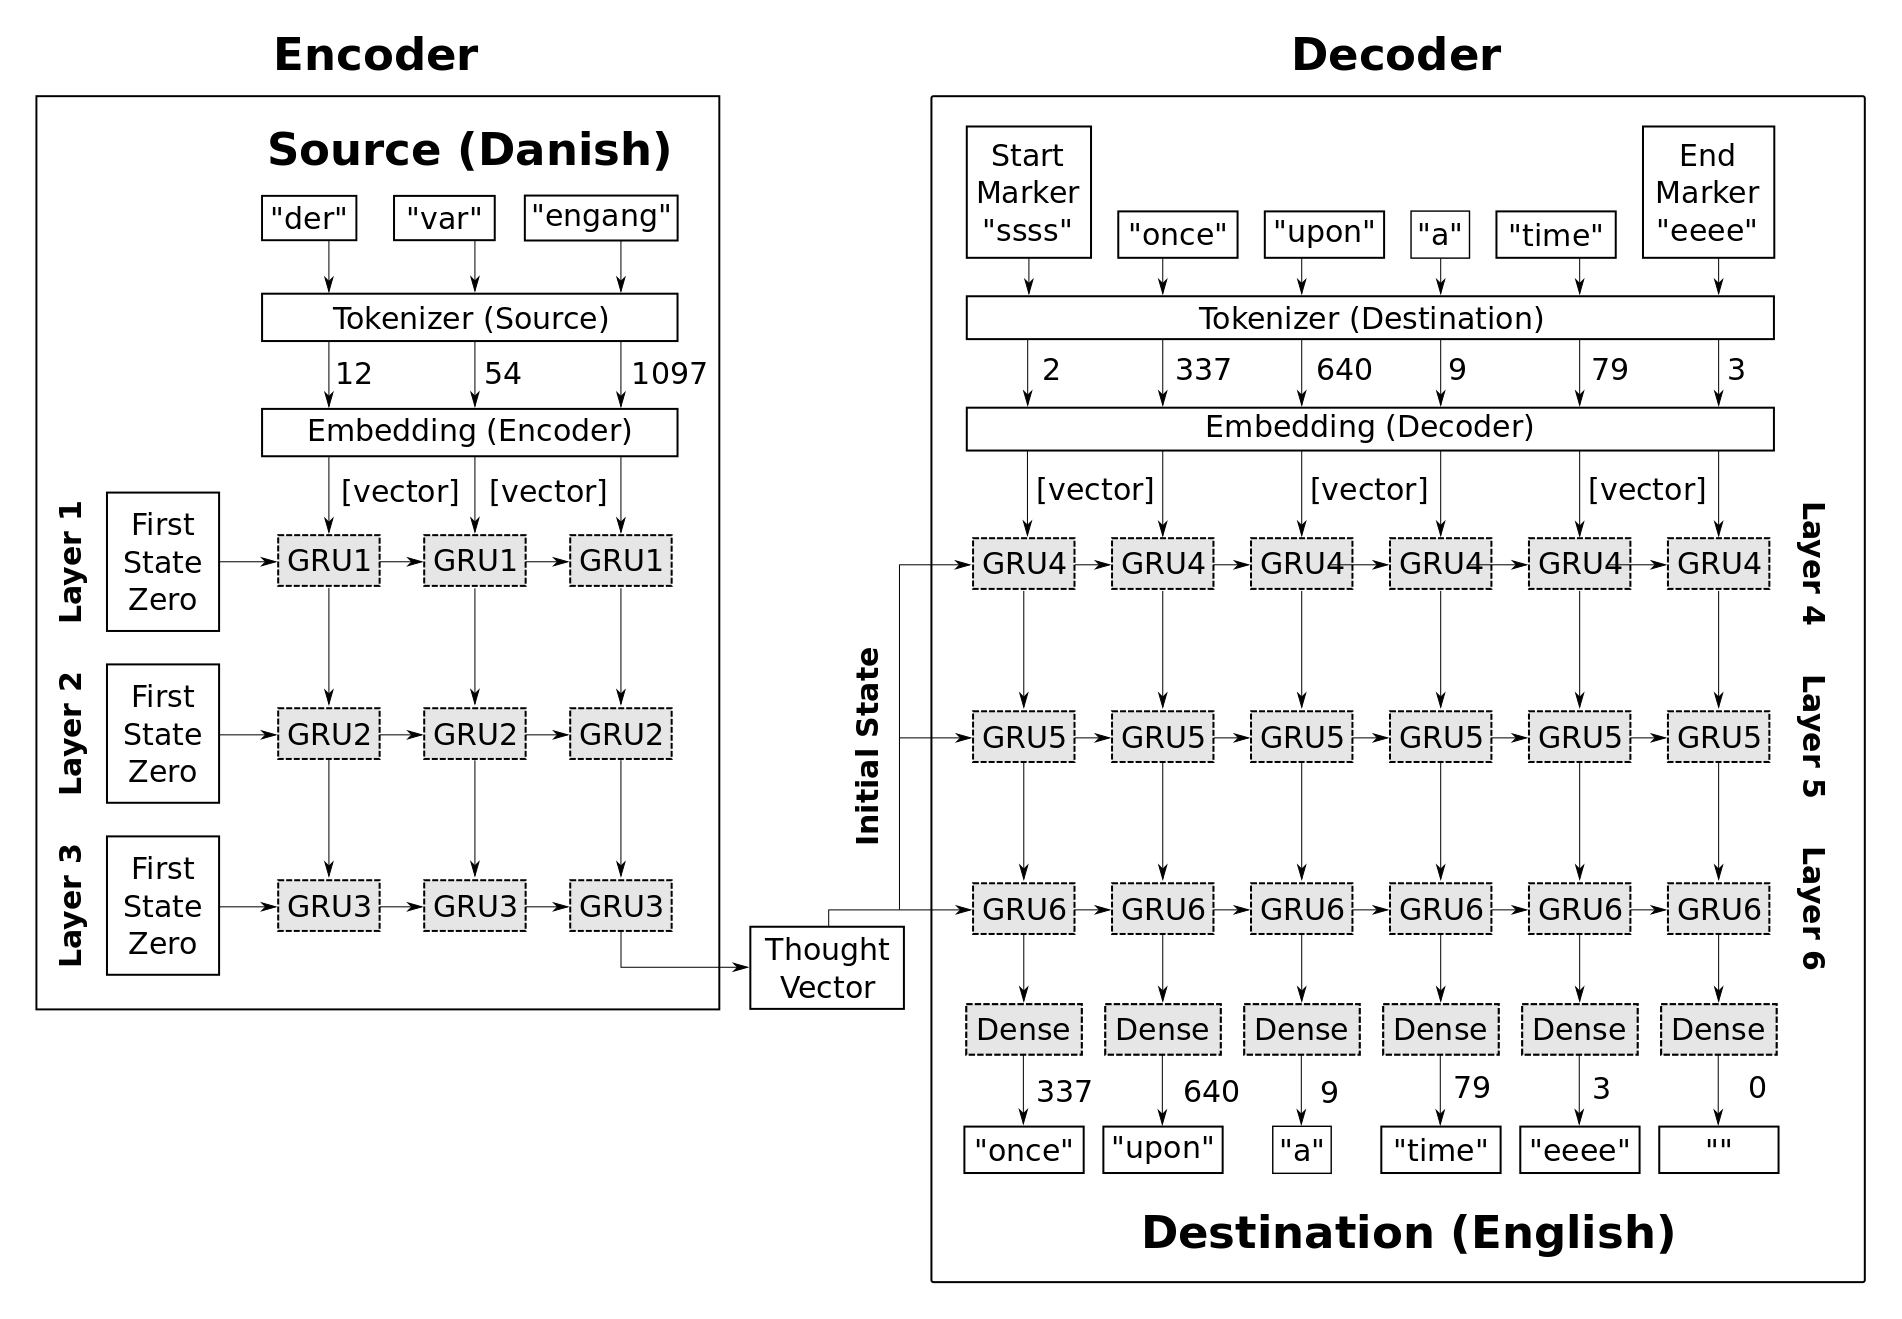

In [ ]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers=3):
        super(Encoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.gru = nn.GRU(embed_size, hidden_size, num_layers, batch_first=True)

    def forward(self, x):
        embedded = self.embedding(x)
        outputs, hidden = self.gru(embedded)
        # We only need the hidden state to pass to the decoder
        return hidden

class Decoder(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers=3):
        super(Decoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.gru = nn.GRU(embed_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden):
        embedded = self.embedding(x)
        outputs, hidden = self.gru(embedded, hidden)
        predictions = self.fc(outputs)
        return predictions, hidden

# Instantiate Models and move them to GPU
embed_size = 128
hidden_size = 512

encoder = Encoder(num_words, embed_size, hidden_size).to(device)
decoder = Decoder(num_words, embed_size, hidden_size).to(device)

### **Parte 4: Entrenamiento**
configuramos los parámetros de optimización y entrenamos.

In [ ]:
# Setup DataLoaders
batch_size = 256

dataset = TensorDataset(torch.tensor(encoder_input_data, dtype=torch.long),
                        torch.tensor(decoder_input_data, dtype=torch.long),
                        torch.tensor(decoder_output_data, dtype=torch.long))

dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Optimizer and Loss
optimizer = optim.RMSprop(list(encoder.parameters()) + list(decoder.parameters()), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=0)

epochs = 50
best_loss = float('inf')

print("Starting training...")
for epoch in range(epochs):
    encoder.train()
    decoder.train()
    total_loss = 0

    # Iterate through batches silently
    for batch_idx, (src, trg_in, trg_out) in enumerate(dataloader):
        src, trg_in, trg_out = src.to(device), trg_in.to(device), trg_out.to(device)

        optimizer.zero_grad()

        # Forward pass
        hidden = encoder(src)
        output, _ = decoder(trg_in, hidden)

        # Reshape for CrossEntropyLoss
        output = output.reshape(-1, output.shape[2])
        trg_out = trg_out.reshape(-1)

        # Compute loss and backpropagate
        loss = criterion(output, trg_out)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # --- END OF EPOCH PRINTING ---
    avg_loss = total_loss / len(dataloader)

    # Print only once per epoch
    print(f"Epoch [{epoch+1}/{epochs}] Completed | Last Batch Loss: {loss.item():.4f} | Average Loss: {avg_loss:.4f}")

    # Checkpoint logic
    if avg_loss < best_loss:
        best_loss = avg_loss
        print(f"Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...")
        torch.save(encoder.state_dict(), 'encoder_best_50.pth')
        torch.save(decoder.state_dict(), 'decoder_best_50.pth')

Starting training...
Epoch [1/50] Completed | Last Batch Loss: 3.8516 | Average Loss: 4.7374
Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...
Epoch [2/50] Completed | Last Batch Loss: 3.3917 | Average Loss: 3.6264
Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...
Epoch [3/50] Completed | Last Batch Loss: 3.1268 | Average Loss: 3.1941
Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...
Epoch [4/50] Completed | Last Batch Loss: 2.9213 | Average Loss: 2.9398
Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...
Epoch [5/50] Completed | Last Batch Loss: 2.8425 | Average Loss: 2.7629
Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...
Epoch [6/50] Completed | Last Batch Loss: 2.6784 | Average Loss: 2.6280
Loss improved! Saving model weights to 'encoder_best.pth' and 'decoder_best.pth'...
Epoch [7/50] Completed | Last Batch Loss: 2

### **Parte 5: Traducción e Inferencia**

Implementamos la función para generar traducciones a partir de nuevas oraciones de entrada.

In [ ]:
# Ensure the models are instantiated and on the correct device
# (If you restarted the notebook, you must run the Architecture cell first)

print("Loading saved model weights...")
try:
    # Load the state dictionaries
    encoder.load_state_dict(torch.load('encoder_best_100.pth', map_location=device, weights_only=True))
    decoder.load_state_dict(torch.load('decoder_best_100.pth', map_location=device, weights_only=True))
    print("Model weights loaded successfully! You are ready for inference.")
except FileNotFoundError:
    print("Warning: Weight files not found. Did the training loop finish successfully?")
except Exception as e:
    print(f"An error occurred while loading weights: {e}")

# Set models to evaluation mode (turns off dropout/batchnorm if you add them later)
encoder.eval()
decoder.eval()

Loading saved model weights...
Model weights loaded successfully! You are ready for inference.


Decoder(
  (embedding): Embedding(10000, 128)
  (gru): GRU(128, 512, num_layers=3, batch_first=True)
  (fc): Linear(in_features=512, out_features=10000, bias=True)
)

In [ ]:
def translate(input_text, true_output_text=None):
    encoder.eval()
    decoder.eval()

    with torch.no_grad():
        # Process input string
        input_tokens = tokenizer_src.texts_to_sequences([input_text], reverse=True, padding='pre')
        src_tensor = torch.tensor(input_tokens, dtype=torch.long).to(device)

        # Get encoder hidden state
        hidden = encoder(src_tensor)

        # Start the decoder with the 'ssss' token
        trg_tensor = torch.tensor([[token_start]], dtype=torch.long).to(device)
        output_text = []

        max_len = tokenizer_dest.max_tokens

        for _ in range(max_len):
            # Pass the current token and previous hidden state
            output, hidden = decoder(trg_tensor, hidden)

            # Get the predicted token index (argmax)
            pred_token = output.argmax(2).item()

            # Stop if we hit the 'eeee' token
            if pred_token == token_end:
                break

            # Add to our translation
            sampled_word = tokenizer_dest.idx2word.get(pred_token, '<unk>')
            output_text.append(sampled_word)

            # Set the current prediction as the input for the next time step
            trg_tensor = torch.tensor([[pred_token]], dtype=torch.long).to(device)

    print("Input text:")
    print(input_text)
    print("\nTranslated text:")
    print(" ".join(output_text))

    if true_output_text is not None:
        print("\nTrue output text:")
        print(true_output_text)
    print("-" * 50)

In [ ]:
translate(input_text="Perdone, me puede indicar cómo ir al metro al centro",
          true_output_text='Excuse me, can you tell me how to go to the subway to the center')

Input text:
Perdone, me puede indicar cómo ir al metro al centro

Translated text:
i can tell you about the constituent clarifications and how to use the way surrounding the exercise of the <unk> <unk> for the purpose of the meantime to be encouraged to use the euro information to replace the public with the <unk>

True output text:
Excuse me, can you tell me how to go to the subway to the center
--------------------------------------------------


In [ ]:
idx = 3
translate(input_text=data_src[idx],
          true_output_text=data_dest[idx])

Input text:
Sus Señorías han solicitado un debate sobre el tema para los próximos días, en el curso de este período de sesiones.

Translated text:
you have requested a debate on this subject for you on a recent occasion for the debate 2000 on journeys initiated in this house

True output text:
ssss You have requested a debate on this subject in the course of the next few days, during this part-session. eeee
--------------------------------------------------


# **6. Clasificación**
En esta sección exploraremos cómo utilizar modelos de aprendizaje profundo para categorizar textos según criterios específicos. Nos enfocaremos en la identificación de estilos literarios.

## **6.1 Clasificación de Autores con Redes Recurrentes**
En este apartado, vamos a crear una Red Neuronal Recurrente capaz de clasificar si una secuencia de una novela pertenece a **Benito Pérez Galdós** o a **Emilia Pardo Bazán**. Este problema de atribución de autoría es un caso clásico de clasificación binaria de texto basado en patrones estilísticos.

### **Importación de Bibliotecas**
Preparamos el entorno con las herramientas necesarias para la descarga de datos, procesamiento de texto y construcción del modelo con TensorFlow.

In [ ]:
import csv
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tqdm import tqdm
import requests
print(tf.__version__)

2.20.0


### **Preparación del Dataset**
Descargaremos tres novelas representativas de cada autor directamente desde el portal de Project Gutenberg para construir nuestro corpus de entrenamiento.

In [ ]:
URLS = [
    ("galdos", "http://www.gutenberg.org/cache/epub/52392/pg52392.txt"),  # Miau
    ("galdos", "http://www.gutenberg.org/cache/epub/15725/pg15725.txt"),  # Doña Perfecta
    ("galdos", "http://www.gutenberg.org/cache/epub/17013/pg17013.txt"),  # Fortunata y Jacinta
    ("bazan", "https://www.gutenberg.org/files/65632/65632-0.txt"),  # La prueba
    ("bazan", "https://www.gutenberg.org/files/58059/58059-0.txt"),  # La Madre Naturaleza
    ("bazan", "https://www.gutenberg.org/cache/epub/17491/pg17491.txt"),  # La Tribuna
]

galdos = ""
bazan = ""
for author, url in tqdm(URLS):
    work_text = requests.get(url).text
    start_mark = "START OF "
    end_mark = "END OF "
    work_text = work_text[work_text.index(start_mark):work_text.index(end_mark)]
    if author == "galdos":
        galdos += "\n" + work_text
    else:
        bazan += "\n" + work_text

100%|██████████| 6/6 [00:07<00:00,  1.28s/it]


Vamos a dividir las novelas en secuencias de una longitud de 250 palabras. Podemos probar con una longitud superior e inferior. Al fin y al cabo es un parámetro a tener en cuenta cuando se define una RNN

In [ ]:
n = 250

galdos_splits = galdos.split()
galdos_chunks = [galdos_splits[i:i + n] for i in range(0, len(galdos_splits), n)]

bazan_splits = bazan.split()
bazan_chunks = [bazan_splits[i:i + n] for i in range(0, len(bazan_splits), n)]

Ahora construiremos una tabla (`DataFrame`) con los textos de cada extracto y una segunda columna indicando si pertenecen la obra de Galdós con un 1 o de Pardo Bazán con un 0.

In [ ]:
galdos_len = len(galdos_chunks)
bazan_len = len(bazan_chunks)
galdos_len, bazan_len

(2425, 868)

In [ ]:
galdos_df = pd.DataFrame(
    [" ".join(chunk) for chunk in galdos_chunks],
    columns=["text"]
).assign(labels=1).sample(frac=1).reset_index(drop=True)
bazan_df = pd.DataFrame(
    [" ".join(chunk) for chunk in bazan_chunks],
    columns=["text"]
).assign(labels=0).sample(frac=1).reset_index(drop=True)

In [ ]:
galdos_df

,text,labels
0,"dissimulation, surreptitiousness. =disipar= _t_ dispel; _r_ melt away. =disonancia= _f_ dissonance. =disparadero= _m_ trigger; =en el---- de= ready for ... on the slightest impulse. =disparar= _t_ discharge, fire, let fly (_w. person as subject_; =despedir= _w. gun etc. as subject); (not in A._) fire on, fire at. =disparatado= ill-assorted, incongruous. =disparate= _m_ absurdity, unreasonable ...",1
1,"vinieron los años bonancibles y el capitalito de la viuda ascendió a dos mil duros, iniciose un periodo de buena suerte que debía de ser pronto increíble prosperidad. Cayó en las combinadas redes de los dos prestamistas un pobre señor, más desgraciado que perverso (que había sido director general y vivía con gran rumbo a pesar de estar a la cuarta pregunta), y no quiero decir cómo le pusieron....",1
2,"la noche convidaba a estar al aire libre), corrió la voz de que la visionaria se había acostado. Fortunata, que pocos días antes fue trasladada al dormitorio en que estaba Mauricia, vio que esta se había acostado vestida y descalza. Acercose a ella y por su bronca respiración creyó entender que dormía profundamente. Mucho le daba qué pensar el singular estado en que su amiga se había puesto, y...",1
3,"_f_ ounce; N =92= 28. =opacidad= _f_ opacity. =opaco= opaque. =ópera= _f_ opera. =operación= _f_ operation. =opinar= _i_ think, be of opinion, one's opinion is. =opinión= _f_ opinion, judgment, mind; public opinion. =oponer= _t_ oppose (_acc._ the obstacle, =a= the thing resisted). =oportunidad= _f_ opportuneness, timeliness, pertinence; good time, favorable time. =oportuno= opportune, favorab...",1
4,"defines this as stretching and twisting in order to shake off either =pereza= (in the sense ""repugnance to rising from one's bed or seat"") or the numbness of a sleepy limb. =131= 31 =ya no se estilan=: 'are no longer good form.' =132= 14 =Al mirar=: 'when she looked.' =133= 5 =pára=: from =parar=. =133= 19 =cinco=: the Madrid edition has =cincos=. =136= 18 =te confieso=, etc.: 'confess to you-...",1
...,...,...
2420,"of confidence. =descreído= disbelieving, unbeliever. =descreimiento= _m_ disbelief, unbelief. =describir= _t_ describe. =descripción= _f_ description, describing. =descriptivo= descriptive. =descuartizar= _t_ cut into quarters, cut up. =descubrir= _t_ uncover, expose, discover; =al--ierto= openly, exposed. =descuidar= _i_ be careless, be negligent; not worry. =descuidillo= _m_ little oversight...",1
2421,"del jabón. Puestas una frente a otra a los dos lados de la artesa, mirábanse cara a cara en aquellos cortos intervalos de descanso, y después volvían con furor al trabajo sin parar por eso la lengua. «Hasta para ser honrada--repitió Fortunata, echando todo el peso de su cuerpo sobre las manos, para estrujar el rollo de tela como si lo amasara--. De eso no se hable, porque hazte cuenta... yo, u...",1
2422,"miseria, con tus _vísperas_ de chiquillo y en poder de _Juárez el Negro_? --Ningún rencor te guardo: Entonces estaba rabiosa. La rabia y la miseria me llevaron con _Juárez el Negro_. ¿Creerás lo que te voy a decir? Pues me fui con él por lo mucho que le aborrecía. Cosa rara, ¿verdad?... Y como no tenía un triste pedazo de pan que llevar a la boca, y él me lo daba, ahí tienes... Yo dije: «me ve...",1
2423,"para que me lo agradezca nadie. Vaya un puñado de anís... Doña Pura estaba radiante, y Villaamil, desconcertado en su pesimismo, parecía un combatiente á quien le destruyen de improviso las defensas que le amparan, dejándole inerme y desnudo ante las balas enemigas. Esforzábase en recobrar su aplomo pesimista... «Historias... Bueno, y aunque fuese verdad que Juan, Pedro y Diego me recomendaran...",1


In [ ]:
bazan_df

,text,labels
0,"noz efenderá, de eguro.... Yo debo ar ejemplo de manzedumbre.... No hizo caso _míter Ezmite_, por demás mohíno y amostazado con el bombardeo de comestibles; pero antes de que llegase al grupo cumpliose la profecía del ministro, interponiéndose más de treinta personas, que rodearon a los malaventurados apóstoles apretándolos en términos que no les dejaban respirar. A poca distancia un agente de...",0
1,"clavando en mí las pupilas, intensas y escrutadoras, repitió: --¿Estás seguro de que ese hombre no tiene celos? --No --repliqué con energía--. _Siento_, conozco que no los tiene. Aunque me lo jurasen frailes descalzos. No tiene celos. --¡Cosa más rara! --murmuró mi amigo, sacudiendo la cabeza meditabundo--. Porque no puedo convencerme de que sea únicamente cuestión de la boda del suegro... Eso...",0
2,"disimuladamente a Lola y le apretó con ira el brazo. Baltasar intercedió una vez más: era su santo, un día en el año. Sobrado padre tartamudeó también disculpas de su hija, a quien quería entrañablemente; y Borrén, siempre obsequioso, acabó de repartir las golosinas. Carmela la encajera y Amparo rehusaron con dignidad su parte; pero la chiquillería despachó su ración atragantándose, en las mis...",0
3,"evitar la ingerencia de elementos extraños o heteróclitos. La media docena de damas que, con mi tití enmedio, presidían moralmente el baile, realizando una ingeniosa captación de los divanes, extendiendo las faldas, haciendo que no veían, habían obtenido el deseado aislamiento. Dos o tres tentativas de inmixtión fueron desconcertadas rápidamente. Pero sobrevino una que demostró la unión, la so...",0
4,"con rapidez, subía y bajaba la cuchilla picando la hoja, el otro, con los brazos enterrados en el tabaco, lo revolvía para que el ya picado fuese deslizándose y quedase sólo en la mesa el entero, operación que requería gran agilidad y tino, porque era fácil que al caer la cuchilla segase los dedos o la mano que encontrara a su alcance. Como se trabajaba a destajo, los picadores no se daban pun...",0
...,...,...
863,"Eran bien intencionados, eso sí; pero indiscretos, inoportunos, fuera de sazón, como suelen ser los afectos en la zonza é ingrata edad de la adolescencia. Empeñábanse en divertirlo, en llevárselo al café, ó á ver una compañía de zarzuela... ¡De zarzuela! Gabriel necesitaba un médico. A los ocho días se le declaraba una fiebre nerviosa, en la cual le contaron que había delirado con su _mamita_,...",0
864,"pitillos las muchachas de Marineda: apenas se veían aldeanas; así es que abundaban los lindos palmitos, los rostros juveniles. Abajo, la mayor parte de las operarias eran madres de familia, que acuden a ganar el pan de sus hijos, agobiadas de trabajo, rebujadas en un mantón, indiferentes a la compostura, pensando en las criaturitas, que quedaron confiadas al cuidado de una vecina; en el recién...",0
865,"manifiestos, proclamas y hojas sueltas, y que a ella y a otras cuantas que pronunciaron vivas subversivos y cantaron canciones alusivas a la Unión del Norte las suspendieran, como suele decirse, de empleo y sueldo. -XVIII- Tribuna del pueblo El Círculo Rojo echa el resto; no se habla en Marineda sino del banquete que ofrece a los delegados de Cantrabria y Cantabrialta. No tiene el Círculo Rojo...",0
866,"historia. No la canté ninguna trova, ni la propuse _la fuga_. ¡Ha sido lo más vulgarón!... En vez de afincarme de hinojos, fui y la pagué el tranvía... --¿Y diez a diez céntimos, entruchasteis la inglesa y tú? --No sé si puede llamarse entruchar --prosiguió el oportunista--. A las tres veces que pagué ya me saludó. Al otro viaje después del saludo, me pidió prestado _El Imparcial_, que yo acab...",0


Combinamos los datos y los dividimos para asegurar que el modelo sea evaluado con textos que no ha visto durante el entrenamiento.

In [ ]:
train_df = pd.concat(
    [galdos_df[:int(galdos_len*.2)], bazan_df[:int(bazan_len*.2)]],
    ignore_index=True
).sample(frac=1).reset_index(drop=True)
train_df

,text,labels
0,"Estaba tranquilo, y como hablara de algo distinto de aquellas manías de la emanación del alma y de la doctrina que iba a predicar, se expresaba con seso y hasta con donaire. Poco a poco iban siendo menos los ratos de extravío, y se pasaba largas horas completamente despejado y tratando de cualquier asunto con discreta naturalidad. Fortunata hacía que le ayudase a estirar la ropa o a devanar ma...",1
1,"=impertinente= irrelevant, intrusive, ungracious. =imperturbabilidad= _f_ imperturbability. =imperturbable= imperturbable. =impetrar= _t_ beseech. =ímpetu= _m_ impetus, rush; impetuosity; ardor. =impetuoso= impetuous. =impiedad= _f_ impiety. =impío= impious. =implacable= implacable; _adv._ =--mente=. =imponente= imposing. =imponer= _t_ impose; inform. =impopularidad= _f_ unpopularity. =importa...",1
2,"decía de su timidez era conversación. «Que tú seas buena, honrada y leal es lo que importa: lo demás corre de mi cuenta, déjame a mí, tú déjame a mí». Poco después almorzaba Fortunata, y Maximiliano estudiaba, cambiando de vez en cuando algunas palabras. Toda aquella tarde dominaron en el espíritu de la joven las ideas optimistas, porque él se dejó decir algo de su herencia, de tierras e hipot...",1
3,"menos ante mujeres y en reuniones de confianza; pero la importuna verbosidad agresiva del canónigo necesitaba, según él, un correctivo. [5] Para dárselo le pareció mal sistema exponer ideas que, concordando con las del canónigo, halagasen a éste, y decidió manifestar las opiniones que más contrariaran y más acerbamente mortificasen al mordaz Penitenciario. --Quieres divertirte conmigo--dijo pa...",1
4,"vio Jacinta unas plantas muy raras, de vástagos escuetos y pencas enormes, que llamaron su atención. «Mira, mira, qué esperpento de árbol. ¿Será el de los higos chumbos?». --No, hija mía, los higos chumbos los da esa otra planta baja, compuesta de unas palas erizadas de púas. Aquello otro es la pita, que da por fruto las sogas. --Y el esparto, ¿dónde está? --Hasta eso no llega mi sabiduría. Po...",1
...,...,...
653,"bien, con _una persona decente_...!». Era lo más que podía desear... ¡Tener un nombre, no tratar más con gentuza, sino con caballeros y señoras! Maximiliano era un bienaventurado, y seguramente la haría feliz. Esto pensaba por la mañana, después de lavarse y encender la lumbre, cuando cogía la cesta para ir a la compra. Púsose el manto y el pañuelo por la cabeza, y bajó a la calle. Lo mismo fu...",1
654,"vez iban más apretados, porque el Arcipreste, reclinando la cabeza en la esquina, y cubriéndose la cara con un pañuelo blanco, adoptaba postura más cómoda, y ocupaba todavía más sitio. --¿Dice usted que las elecciones en que figuró el Marqués de Ulloa?... --Sí señor, sí señor...--repuso Trampeta, todo esponjado y contento de acertar con algo que interesaba al viajero y le hacía dar señales de ...",0
655,"que á los pillos... ¿Crees que espero algo ni del Ministro ni de Dios? Todos son lo mismo... ¡Arriba y abajo farsa, favoritismo, polaquería! Ya ves lo que sacamos de tanta humillación y de tanto rezo. Aquí me tienes desairado siempre y sin que nadie me haga caso, mientras que ese pasmarote, embustero y trapisondista... Se dió con la palma de la mano un golpe tan recio en el cráneo, que Luisito...",1
656,"jirones de púrpura de las pocas hojas restantes. Algún racimo negreaba en lo alto. En unas tinas viejas arrimadas al banco de piedra, había botellas vacías que semejaban embarcaciones náufragas varadas en un arenal. Amparo sentía mucho frío cuando Baltasar llegó. Sentose este al lado de la muchacha, que le presentó un paquete de sus cigarrillos predilectos, emboquillados, bastante largos, liad...",0


In [ ]:
eval_df = pd.concat(
    [galdos_df[int(galdos_len*.8):], bazan_df[int(bazan_len*.8):]],
    ignore_index=True
).sample(frac=1).reset_index(drop=True)
eval_df

,text,labels
0,"como si tal cosa. ¿Creerás que me dijo algo de amor? ¿Creerás que se acordaba de cumplir las promesas que me había hecho? Buen cumplimiento nos dé Dios. Hija, frialdad igual no he visto. Te aseguro, que me dan ganas, _por ejemplo_, de clavarle un puñal... Cierto que me ofreció lo que yo quisiera para establecerme... pero no quise tomar nada de aquellas manos. ¡Monstruo! Cuando le dio al primo ...",1
1,"su voz la molestaba y hería, y por primera vez en su vida pensó de él lo siguiente: «¿Qué me importa á mí que duermas ó no, ni que estés bueno ni que estés malo, ni que te lleven los demonios?» Luisito, hecho á ver á su tía muy cariñosa, no se resignaba á callar. Quería palique á todo trance, y con voz de mimo, dijo á su compañera de habitación: --Tía, ¿viste tu por casualidad á Dios alguna ve...",1
2,"¡La lotería!, ¡qué atraso tan grande! Es de las cosas que debieran suprimirse; mata el ahorro; es la Providencia de las haraganes. Con la lotería no puede haber prosperidad pública... ¿Qué?, te marchas otra vez. ¡Bonita manera de cuidar a un enfermo! Y vamos a ver, ¿qué demonios tienes tú que hacer por esas calles toda la mañana? A ver, explícame, quiero saberlo; porque es ya lo de todos los d...",1
3,"á desabrocharse las botas. Ni un segundo tardó Perucho en hincársele de rodillas delante. --Yo te descalzo.... yo. Como cuando eras una _cativa_: ¿te acuerdas? un tapón así... y yo te descalzaba y te vestía.... y hasta te tengo peinado mil veces. Medio riendo, medio enfadándose, la muchacha no retiró el pie de las manos de su amigo. Éste hacía ya saltar uno tras otro los botoncitos de la botin...",0
4,"primer momento con limpieza y claridad. La salita en que estaba tenía ese lujo allegadizo que sustituye al verdadero allí donde el concubinato elegante vive aún en condiciones de timidez y más bien como ensayo. Había muebles forrados de seda y cortinas hermosas; pero aquellos eran feotes, de amaranto combinado con verde-limón; las cortinas estaban torcidas, las guardamalletas mal colocadas, la...",1
...,...,...
654,"_la mona del Padre Eterno_, ya la negaba. «Daría yo cualquier cosa--exclamaba invocando al Cielo--, por saber esa verdad que ahora no saben más que Dios y ella, pues el tercero que la sabía se ha muerto. Lo sabrá también el confesor de Jacinta, si es que lo ha confesado. Pero nadie más, nadie más. Pues no sé qué daría yo por salir de la duda. Esta curiosidad me quema la sangre... Flojilla dife...",1
655,"quitar los extáticos ojos de aquel semblante que le parecía angelical. Y cuanto ella dijo lo oyó como si fuera una sarta de conceptos ingeniosísimos. «¡Si es un ángel!... No ha dicho ni una palabra malsonante... ¡Y qué metal de voz! No he oído en mi vida música tan grata... ¿Cómo será el decir esta mujer un _te quiero_, diciéndolo con verdad y con alma?». Esta idea produjo en la mente de Rubín...",1
656,"pitillos las muchachas de Marineda: apenas se veían aldeanas; así es que abundaban los lindos palmitos, los rostros juveniles. Abajo, la mayor parte de las operarias eran madres de familia, que acuden a ganar el pan de sus hijos, agobiadas de trabajo, rebujadas en un mantón, indiferentes a la compostura, pensando en las criaturitas, que quedaron confiadas al cuidado de una vecina; en el recién...",0
657,"coco, mamarracho, mal hombre y peor amigo, que además no sabe poner una minuta? --Cabalmente, cabalmente por eso, por ser una inutilidad--afirmó Villaamil con inmenso pesimismo,--tiene asegurada su carrera. --Yo me sublevo--declaró con rabia _el caballero de Felipe IV_ dando una patada.--Si ascienden á ése antes que á mí, me voy al Ministro y le digo... vamos, le suelto una frescura. Esto es p...",1


In [ ]:
train_df['labels'].value_counts()

labels
1    485
0    173
Name: count, dtype: int64

In [ ]:
eval_df['labels'].value_counts()

labels
1    485
0    174
Name: count, dtype: int64

### **Construcción del Modelo**
Utilizaremos una red neuronal con una capa de Embedding seguida de una LSTM Bidireccional. La bidireccionalidad permite al modelo capturar el contexto de las palabras tanto de izquierda a derecha como de derecha a izquierda, lo cual es vital para capturar el estilo literario.



* `vocab_size`: cómo de largo queremos que sea nuestro vocabulario. Si es
demasiado corto, el rendimiento de la red sería muy pobre pues habría muchos tokens desconocidos. Si es demasiado grande, nuestra red tardará más en entrenar.

* `embedding_dim`: Este parámetro nos dice cómo de grandes queremos que sean los vectores que representan cada palabra de nuestro vocabulario. Normalmente, cuanto más grandes sean, mayor 'calidad' en la representación de las mismas.

* `max_length`: Debemos definir una longitud máxima de secuencia puesto que nuestra red espera que todas tenga la misma longitud. En nuestro caso, como partimos el dataset en secuencias de 250 palabras, usaremos ese valor.

* `trunc_type`: si una secuencia es más larga de 250 palabras la cortamos por detrás (post).

* `padding_type` = nos dice que en caso de que la secuencia se más corta de 250 tokens en qué parte de ésta se añade los tokens de padding (post = al final).

* `oov_tok = <OOV>` da un valor a las palabras/tokens que estén fuera de esas 5000 como máximo que hemos definido para nuestro vocabulario.

In [ ]:
vocab_size = 5000
embedding_dim = 64
max_length = 250
trunc_type = 'post'
padding_type = 'post'
oov_tok = '<OOV>'

In [ ]:
train_articles = train_df['text'].tolist()
train_labels = train_df['labels'].tolist()

validation_articles = eval_df['text'].tolist()
validation_labels = eval_df['labels'].tolist()

print(len(train_articles))
print(len(train_labels))
print(len(validation_articles))
print(len(validation_labels))

658
658
659
659


#### Creamos el Tokenizer

Le vamos a decir cuál es el número máximo de palabras, el token para palabras que no estén en el vocabulario y que las pase minúsculas para reducir el tamaño del mismo

In [ ]:
tokenizer = Tokenizer(num_words = vocab_size, oov_token=oov_tok, lower=True)
tokenizer.fit_on_texts(train_articles)
word_index = tokenizer.word_index
dict(list(word_index.items())[0:10])

{'<OOV>': 1,
 'de': 2,
 'que': 3,
 'la': 4,
 'y': 5,
 'el': 6,
 'a': 7,
 'en': 8,
 'no': 9,
 'se': 10}

No hemos filtrado las `STOPWORDS` pero se podría.

Tokenizamos nuestro dataset de entrenamiento una vez que ya tenemos nuestro vocabulario listo.

In [ ]:
train_sequences = tokenizer.texts_to_sequences(train_articles)
print(train_sequences[10])

[2863, 1, 6, 2396, 362, 259, 1, 11, 328, 5, 95, 3, 4, 260, 2, 1478, 4, 1, 9, 528, 1, 2, 4, 461, 5, 1825, 1, 160, 53, 56, 244, 9, 98, 1, 7, 12, 343, 30, 12, 343, 53, 98, 1, 41, 244, 25, 515, 31, 9, 119, 88, 2, 834, 5, 6, 217, 28, 19, 315, 124, 97, 52, 2, 84, 11, 6, 307, 2, 4, 123, 3, 28, 9, 4503, 7, 934, 4, 1076, 5, 18, 1, 1, 320, 2, 4, 271, 558, 114, 119, 40, 1, 7, 2397, 7, 1, 7, 1, 5, 172, 13, 3, 26, 1213, 5, 26, 111, 1016, 4, 3, 10, 1, 11, 12, 2, 14, 689, 267, 133, 151, 30, 4, 3, 665, 11, 835, 348, 111, 4504, 4, 1076, 9, 607, 627, 98, 529, 82, 16, 462, 836, 28, 19, 718, 719, 294, 4505, 212, 9, 19, 1, 17, 309, 27, 7, 140, 1, 9, 1, 85, 3, 16, 343, 103, 9, 33, 1, 12, 3, 10, 33, 1017, 316, 45, 67, 489, 3, 10, 1, 120, 7, 4, 1, 17, 244, 5, 247, 3, 46, 1, 2, 1, 5, 7, 196, 12, 3, 18, 1, 7, 120, 9, 10, 754, 17, 1, 5, 22, 118, 5, 22, 1018, 167, 114, 10, 557, 11, 628, 2083, 215, 935, 8, 4, 1, 2, 21, 213, 166, 17, 42, 52, 2, 84, 71, 1, 9, 24, 1345, 2, 81, 9, 30, 114, 483, 65, 1, 212, 3531, 1479,

Aplicamos padding a nuestras secuencias de entrenamientoi para que todas tengan la misma longitud (para este dataset no es neceario porque las dividimos con la misma longitud, pero en otros casos suele ser útil).

In [ ]:
train_padded = pad_sequences(train_sequences, maxlen=max_length, padding=padding_type, truncating=trunc_type)
print(len(train_sequences[0]))
print(len(train_padded[0]))

print(len(train_sequences[1]))
print(len(train_padded[1]))

print(len(train_sequences[10]))
print(len(train_padded[10]))

249
250
249
250
254
250


In [ ]:
print(train_padded[10])

[2863    1    6 2396  362  259    1   11  328    5   95    3    4  260
    2 1478    4    1    9  528    1    2    4  461    5 1825    1  160
   53   56  244    9   98    1    7   12  343   30   12  343   53   98
    1   41  244   25  515   31    9  119   88    2  834    5    6  217
   28   19  315  124   97   52    2   84   11    6  307    2    4  123
    3   28    9 4503    7  934    4 1076    5   18    1    1  320    2
    4  271  558  114  119   40    1    7 2397    7    1    7    1    5
  172   13    3   26 1213    5   26  111 1016    4    3   10    1   11
   12    2   14  689  267  133  151   30    4    3  665   11  835  348
  111 4504    4 1076    9  607  627   98  529   82   16  462  836   28
   19  718  719  294 4505  212    9   19    1   17  309   27    7  140
    1    9    1   85    3   16  343  103    9   33    1   12    3   10
   33 1017  316   45   67  489    3   10    1  120    7    4    1   17
  244    5  247    3   46    1    2    1    5    7  196   12    3   18
    1 

Hacemos lo propio con el dataset de validación

In [ ]:
validation_sequences = tokenizer.texts_to_sequences(validation_articles)
validation_padded = pad_sequences(validation_sequences, maxlen=max_length, padding=padding_type, truncating=trunc_type)

print(len(validation_sequences))
print(validation_padded.shape)

659
(659, 250)


Codificamos correctamente las `labels`

In [ ]:
training_label_seq = np.array(train_labels, dtype=np.int8)
validation_label_seq = np.array(validation_labels, dtype=np.int8)
print(training_label_seq[0])
print(training_label_seq[1])
print(training_label_seq[2])
print(training_label_seq.shape)

print(validation_label_seq[0])
print(validation_label_seq[1])
print(validation_label_seq[2])
print(validation_label_seq.shape)

1
1
1
(658,)
1
1
1
(659,)


Veamos cómo somos capaces de decodificar una secuencia tokenizada a texto de nuevo gracias al tokenizer que creamos

In [ ]:
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])

def decode_article(text):
    return ' '.join([reverse_word_index.get(i, '?') for i in text])
print(decode_article(train_padded[10]))
print('---')
print(train_articles[10])

garcía <OOV> el pleito están medio <OOV> con ellas y eso que la mayor de sobrado la <OOV> no quiso <OOV> de la amiga y sigue <OOV> allá bien pues ellos no nos <OOV> a los demás pero los demás bien nos <OOV> sin ellos para comer yo no les he de pedir y el hijo si me quiere decir algo ha de ser con el cura de la mano que si no echose a reír la comadreja y le <OOV> <OOV> dentro de la misma fábrica ¿qué les había <OOV> a antonia a <OOV> a <OOV> y eran las que más hablaban y más cosas decían la que se <OOV> con los de su clase aún menos mal pero la que andaba con señores esas cosas añadía la comadreja no tienen remedio nos hacen ver lo negro blanco si me quisiera perder exclamó ofendida amparo no me <OOV> por dónde como a todas <OOV> no <OOV> mujer que lo demás también no te <OOV> los que se te pusieron delante porque hay hombres que se <OOV> uno a la <OOV> por ellos y otros que ni <OOV> de <OOV> y a veces los que le <OOV> a uno no se dan por <OOV> y al fin y al cabo hija ¿qué se gana con v

#### Construimos nuestra red neuronal

- Utilizaremos la `Sequential` API de Keras
- Creamos una primera capa de `Embedding`que tiene por tamaño `vocab_size`x `embedding_dim`
- Despues añadimos nuestra capa de recurrencia. En este caso será una `LSTM` bidireccional (aprende de izquerida a derecha y de derecha a izquierda)
- Conectamos la salida de esa capa a una capa `Dense`.
- Por último, conectamos todo a una capa `Dense`con función de activación `sigmoid`ya que nuestro problema de clasificación es binario.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size, embedding_dim),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(embedding_dim)),
    tf.keras.layers.Dense(embedding_dim, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

### **Entrenamos nuestro modelo**

In [ ]:
num_epochs = 4
history = model.fit(train_padded, training_label_seq, epochs=num_epochs, validation_data=(validation_padded, validation_label_seq), verbose=2)

Epoch 1/4
21/21 - 3s - 123ms/step - accuracy: 0.7143 - loss: 0.6471 - val_accuracy: 0.7360 - val_loss: 0.5849
Epoch 2/4
21/21 - 1s - 44ms/step - accuracy: 0.7371 - loss: 0.5629 - val_accuracy: 0.7360 - val_loss: 0.5512
Epoch 3/4
21/21 - 1s - 42ms/step - accuracy: 0.7781 - loss: 0.4229 - val_accuracy: 0.8118 - val_loss: 0.4033
Epoch 4/4
21/21 - 1s - 43ms/step - accuracy: 0.9362 - loss: 0.1569 - val_accuracy: 0.8816 - val_loss: 0.2803


### **Visualizamos los resultados**

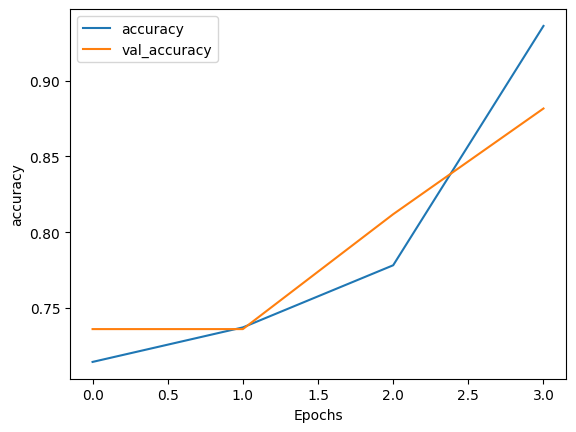

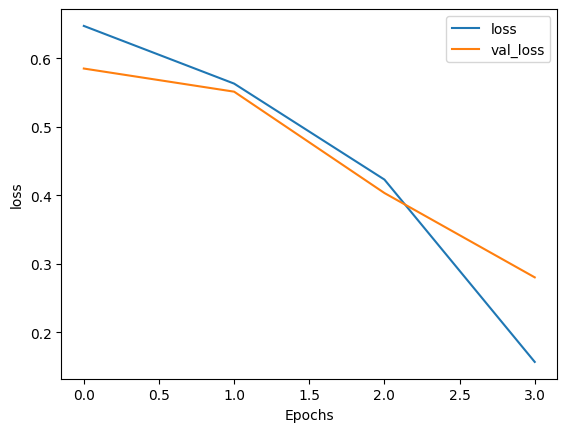

In [ ]:
def plot_graphs(history, string):
  plt.plot(history.history[string])
  plt.plot(history.history['val_'+string])
  plt.xlabel("Epochs")
  plt.ylabel(string)
  plt.legend([string, 'val_'+string])
  plt.show()

plot_graphs(history, "accuracy")
plot_graphs(history, "loss")

### **Probemos nuestro modelo**

In [ ]:
validation_articles[50], validation_label_seq[50]

('Doña Lupe la amenazaba con mandarla a la _galera_ o con llamar una pareja, con escabecharla y ponerla en salmuera, y poco a poco se iba aplacando la fierecilla hasta que se quedaba como un guante. --vi-- Maximiliano, gozoso de ver que su tía con aquel gran alboroto, no se ocupaba de él, poníase de parte de la autoridad y en contra de Papitos. Sí, sí; era muy mala, muy descarada, y había que atarla corto. Azuzaba la cólera de doña Lupe para que esta no se revolviese contra él hablándole de su cambio de costumbres y de lo que hacía fuera de casa. Doña Lupe fue aquella noche a casa de las de la Caña, y se estuvo allá las horas muertas. Maximiliano entró a las once. Había dejado a Fortunata acostada y casi dormida, y se retiró decidido a afrontar las chafalditas de su tía y a explicarse con ella. Porque después del caso de la herencia, ya no podía dudar de que la Providencia le favorecía, abriéndole camino. Nunca había sido él muy religioso; pero aquella noche parecíale desacato y aun in

In [ ]:
txt = ['''
para que el triunfo fuese completo era menester que a Maxi le entrase una enfermedad asquerosa, repugnante y pestífera, de esas que ahuyentan hasta a los más allegados. Ella, entonces, daría pruebas de ser tan ángel como otra cualquiera, y tendría alma, paciencia, valor y estómago para todo. «Y entonces vería _esa_ si aquí hay perfecciones o no hay perfecciones, y que cada una es cada una... Lo malo sería que no lo viese, porque acá no ha de venir...». Maximiliano la distrajo de esta meditación, dando quejidos profundos. Ya conocía aquello su mujer y sabía el remedio, que era volverlo suavemente del otro lado... «¡Qué sueño!--murmuró Maxi medio despierto--. Soñaba que te habías marchado... y yo te había cogido de un pie, y tú tirabas, y yo tiraba más, y tirando se me rompía la bolsa del aneurisma, y todo el cuarto se llenaba de sangre, todo el cuarto, hasta el techo...». Le arrulló para que se durmiera, y ella se durmió también. Levantose temprano porque tenía que trabajar. Después de las nueve, cuando entró en la alcoba a ver si a su marido se le ofrecía alguna cosa, este se estaba vistiendo, y en una disposición de ánimo muy distinta de la que tuviera la noche anterior. No sólo parecía recobrado de su debilidad, sino que estaba inquieto, ágil y como si acabara de tomar un excitante muy enérgico. En cuanto entró su mujer, se fue derecho a ella, abotonándose el cuello de la camisa, y en tono
''']
seq = tokenizer.texts_to_sequences(txt)
padded = pad_sequences(seq, maxlen=max_length)
pred = model.predict(padded)
print(pred)
print("Parece una secuencia de una novela de Galdós" if pred[0] > 0.5 else "Parece que esta novela pertenece a Emilia Pardo Bazán")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
[[0.9178185]]
Parece una secuencia de una novela de Galdós


## **6.2 Clasificación de textos con Transformers**

En este apartado aprenderemos cómo realizar el ajuste fino (*fine-tuning*) de un modelo **RoBERTa** preentrenado para el español. El objetivo es clasificar reseñas de Amazon según su puntuación de estrellas (del 1 al 5).

### Cargar y explorar los datos

In [ ]:
import pandas as pd
import numpy as np
import torch
import evaluate
import random
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    pipeline
)
from IPython.display import display, HTML

## 1. Load train, test, and validation CSVs into independent DataFrames
# (Make sure these filenames match your actual files)
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")
df_val = pd.read_csv("validation.csv")

## 2. Filter each dataset for Spanish ('es') and reset the index
es_train = df_train[df_train["language"] == "es"].reset_index(drop=True)
es_test = df_test[df_test["language"] == "es"].reset_index(drop=True)
es_val = df_val[df_val["language"] == "es"].reset_index(drop=True)

## 3. Simplified random sampling function for Pandas
def show_random_elements(df, num_examples=10):
    """Displays random rows from a pandas DataFrame."""
    assert num_examples <= len(df), "Can't pick more elements than there are in the dataset."

    # Pandas has a built-in method for this, no loops needed!
    random_sample = df.sample(n=num_examples)
    display(HTML(random_sample.to_html()))

## 4. Data Exploration (Using the training set as an example)
print("--- Random Examples ---")
show_random_elements(es_train)

print("\n--- First 5 Rows ---")
display(es_train.head())

print("\n--- Product Category Distribution ---")
print(es_train["product_category"].value_counts())

print("\n--- Stars Distribution ---")
print(es_train["stars"].value_counts())

25792 | INFO | PyTorch version 2.12.0.dev20260224+cu128 available.
25792 | INFO | TensorFlow version 2.20.0 available.


--- Random Examples ---


,Unnamed: 0,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
187393,587393,es_0644567,product_es_0861398,reviewer_es_0053463,5,"Robusto, como todo lo de Hunter",Ok,es,lawn_and_garden
167797,567797,es_0428867,product_es_0300237,reviewer_es_0286167,5,Se instalan muy fácil y se pueden poner las sillas de los niños encima sin problemas que es para lo que las queríamos. Incluso con el isofix.,Cumple su función.,es,baby_product
40951,440951,es_0345034,product_es_0126888,reviewer_es_0368015,2,"No me ha gustado este tipo de ratón, lo veo demasiado grande.",Demasiado grande,es,pc
160528,560528,es_0529804,product_es_0102292,reviewer_es_0287550,5,Muy buen precio y buena calidad,Wella,es,beauty
161386,561386,es_0496247,product_es_0366210,reviewer_es_0087746,5,"Me encanta la marca de estas proteínas, porque no caen pesadas y el sabor es buenísimo, el de tiramisú es delicioso y he comprado la de banana y también está riquísimo! Además el envío es rápido y con BCAA de regalo!",Excelente calidad! La recomiendo!,es,drugstore
58922,458922,es_0427894,product_es_0271636,reviewer_es_0986516,2,"Me parecen de malísima calidad, tanto que he puesto uno y lo he sacado al momento, se ensucia con mirarlo y no se adapta muy bien, ademas que he podido comprobar que se raya con mucha facilidad.",Nada recomentable,es,electronics
164175,564175,es_0716039,product_es_0281381,reviewer_es_0610836,5,Muy bueno para jugar e construir figuras con los imanes,Bueno,es,toy
33616,433616,es_0623394,product_es_0019975,reviewer_es_0159304,1,"Muy gorda. Además, la palanca para extraer las tarjetas está muy dura. No recomiendo su compra",Tamaño excesivo y poco práctica,es,luggage
136744,536744,es_0587765,product_es_0425421,reviewer_es_0360243,4,Me ha gustado desde que lo vi. Se conectó perfectamente y cumple las expectativas que yo tenía.Para una habitación va bien.,Cumple expectativas,es,wireless
170246,570246,es_0750732,product_es_0250840,reviewer_es_0166870,5,Me gusta mucho está tarde lo usaré que tengo muchas ganas de ver como va,Práctico,es,home



--- First 5 Rows ---


,Unnamed: 0,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
0,400000,es_0491108,product_es_0296024,reviewer_es_0999081,1,Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante,television Nevir,es,electronics
1,400001,es_0869872,product_es_0922286,reviewer_es_0216771,1,"Horrible, nos tuvimos que comprar otro porque ni nosotros que sabemos inglés, ni un informático, después de una hora fue capaz de instalarlo",Dinero tirado a la basura con esta compra,es,electronics
2,400002,es_0811721,product_es_0474543,reviewer_es_0929213,1,"Te obligan a comprar dos unidades y te llega solo una y no hay forma de reclamar, una autentica estafa, no compreis!!",solo llega una unidad cuando te obligan a comprar dos,es,drugstore
3,400003,es_0359921,product_es_0656090,reviewer_es_0224702,1,"No entro en descalificar al vendedor, solo puedo decir que tras dos meses de espera.... sigo sin el producto y tuve que contactar con Amazon para reclamar su reembolso. Amazon un 10 . Se hace cargo del problema, pero yo e desembolsado mi dinero y en dos meses me lo devuelven Perdida de tiempo TOTAL. Sin palabras. Y Ustedes deciden",PRODUCTO NO RECIBIDO.,es,wireless
4,400004,es_0068940,product_es_0662544,reviewer_es_0224827,1,Llega tarde y co la talla equivocada,Devuelto,es,shoes



--- Product Category Distribution ---
product_category
home                        26962
wireless                    25886
toy                         13647
sports                      13189
pc                          11191
home_improvement            10879
electronics                 10385
beauty                       7337
automotive                   7143
kitchen                      6695
apparel                      5737
drugstore                    5513
book                         5264
furniture                    5229
baby_product                 4881
office_product               4771
lawn_and_garden              4237
other                        3937
pet_products                 3713
personal_care_appliances     3573
luggage                      3328
camera                       3029
shoes                        2754
digital_ebook_purchase       1843
video_games                  1733
jewelry                      1598
musical_instruments          1530
watch                     

### Mapear las clasificaciones por estrellas

In [ ]:
from datasets import Dataset, DatasetDict

# Mapeo de 5 clases: De (1-5 estrellas) a (0-4 etiquetas)
# Simplemente restamos 1 al valor de las estrellas
es_train["labels"] = es_train["stars"] - 1
es_test["labels"] = es_test["stars"] - 1
es_val["labels"] = es_val["stars"] - 1

# Convertimos a formato Hugging Face Dataset
dataset = DatasetDict({
    "train": Dataset.from_pandas(es_train),
    "test": Dataset.from_pandas(es_test),
    "validation": Dataset.from_pandas(es_val)
})

print("Distribución de etiquetas en train:")
print(es_train["labels"].value_counts())

Distribución de etiquetas en train:
labels
0    40000
1    40000
2    40000
3    40000
4    40000
Name: count, dtype: int64


### Tokenizar las reseñas

In [ ]:
from transformers import AutoTokenizer

model_checkpoint = "tabularisai/multilingual-sentiment-analysis"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

25792 | INFO | HTTP Request: HEAD https://huggingface.co/tabularisai/multilingual-sentiment-analysis/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/tabularisai/multilingual-sentiment-analysis/87d9f8398d4d78e211657ade39ff5f37bb30c9ee/config.json "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/tabularisai/multilingual-sentiment-analysis/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/tabularisai/multilingual-sentiment-analysis/87d9f8398d4d78e211657ade39ff5f37bb30c9ee/tokenizer_config.json "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/tabularisai/multilingual-sentiment-analysis/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/tabularisai/mu

### Tokenización de las reseñas

In [ ]:
# 2. Explorar cómo funciona tu tokenizador (Tu código original)
print(f"Tamaño del vocabulario: {tokenizer.vocab_size}")

text = "¡hola, me llamo lewis!"
tokenized_text = tokenizer.encode(text)

print("\n--- Tokens Individuales ---")
for token in tokenized_text:
    print(f"{token} -> {tokenizer.decode([token])}")

encoded_text = tokenizer(text, return_tensors="pt")
print("\n--- Texto Codificado como Tensor de PyTorch ---")
print(encoded_text)

Tamaño del vocabulario: 119547

--- Tokens Individuales ---
101 -> [CLS]
199 -> ¡
110516 -> hol
10113 -> ##a
117 -> ,
10911 -> me
22469 -> ll
39884 -> ##amo
10141 -> le
83648 -> ##wis
106 -> !
102 -> [SEP]

--- Texto Codificado como Tensor de PyTorch ---
{'input_ids': tensor([[   101,    199, 110516,  10113,    117,  10911,  22469,  39884,  10141,
          83648,    106,    102]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}


In [ ]:
def tokenize_reviews(examples):
    # Añadimos truncamiento y max_length para evitar el IndexError
    return tokenizer(examples["review_body"], truncation=True, max_length=512)

# Eliminamos todas las columnas originales excepto 'labels'
columns_to_remove = dataset["train"].column_names
if "labels" in columns_to_remove:
    columns_to_remove.remove("labels")

encoded_dataset = dataset.map(
    tokenize_reviews,
    batched=True,
    remove_columns=columns_to_remove
)

Map:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

### Afinar el modelo preentrenado

Si quiere entender más profundamente cómo funciona el Entrenador, vea el siguiente vídeo:

In [ ]:
print("--- Diagnóstico de Hardware ---")
print(f"Versión de PyTorch: {torch.__version__}")
cuda_available = torch.cuda.is_available()
print(f"¿CUDA disponible?: {cuda_available}")

if cuda_available:
    device = "cuda"
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
else:
    device = "cpu"
    print("ADVERTENCIA: Entrenando en CPU. Esto causará que el proceso parezca no terminar.")

--- Diagnóstico de Hardware ---
Versión de PyTorch: 2.12.0.dev20260224+cu128
¿CUDA disponible?: True
GPU detectada: NVIDIA GeForce RTX 5060 Ti


In [ ]:
from transformers import DataCollatorWithPadding  # Importado para solucionar el error de padding
# Cargamos el modelo para 5 clases
model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=5,
    ignore_mismatched_sizes=True
)
# Definimos el Data Collator para manejar el padding dinámico
# Esto corrige el ValueError: expected sequence of length...
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Métricas
metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

# Configuración de Entrenamiento
batch_size = 16
num_train_samples = 0 # Pon 0 para usar todo el dataset
num_val_samples = 0    # Pon 0 para usar todo el dataset

# Define los límites reales evaluando si la variable es 0
train_limit = len(encoded_dataset["train"]) if num_train_samples == 0 else min(num_train_samples, len(encoded_dataset["train"]))
val_limit = len(encoded_dataset["validation"]) if num_val_samples == 0 else min(num_val_samples, len(encoded_dataset["validation"]))

# Aplica la selección con los nuevos límites
train_dataset = encoded_dataset["train"].shuffle(seed=42).select(range(train_limit))
val_dataset = encoded_dataset["validation"].shuffle(seed=42).select(range(val_limit))

args = TrainingArguments(
    output_dir="results-5-classes",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=20,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=50,
    save_total_limit=1,
    push_to_hub=True, # Lo habilitamos para configurar el repo, pero el push final será manual
    hub_model_id="multilingual-sentiment-analysis-amazon-reviews-2",
    fp16=True if cuda_available else False,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

25792 | INFO | HTTP Request: HEAD https://huggingface.co/tabularisai/multilingual-sentiment-analysis/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/tabularisai/multilingual-sentiment-analysis/87d9f8398d4d78e211657ade39ff5f37bb30c9ee/config.json "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

25792 | INFO | HTTP Request: POST https://huggingface.co/api/repos/create "HTTP/1.1 409 Conflict"


### Testeo Inicial

In [ ]:
def run_test_logic(model_to_test, stage_name):
    print(f"\n{'='*20} PRUEBAS {stage_name.upper()} {'='*20}")

    # Pipeline con truncamiento automático
    classifier = pipeline(
        "text-classification",
        model=model_to_test,
        tokenizer=tokenizer,
        truncation=True,
        max_length=512
    )

    # 1. Tus reseñas personalizadas
    custom_reviews = [
        "Es un desastre total, no funciona y llegó roto. Dinero tirado.",
        "No está mal, cumple su función pero la calidad es mejorable.",
        "Increíble, el mejor producto que he comprado en años. Calidad 10/10."
    ]

    # 2. Buscar segundas ocurrencias de cada clase (0, 1, 2, 3, 4) en el set de prueba
    db_reviews = []
    db_labels = []

    for target_label in range(5):
        indices = [i for i, label in enumerate(dataset["test"]["labels"]) if label == target_label]
        if len(indices) >= 2:
            idx = indices[1] # La segunda ocurrencia
            db_reviews.append(dataset["test"]["review_body"][idx])
            db_labels.append(target_label)

    # Unir todo
    all_texts = custom_reviews + db_reviews
    results = classifier(all_texts)

    # Mostrar resultados
    print("\n--- RESEÑAS PERSONALIZADAS ---")
    for i, text in enumerate(custom_reviews):
        print(f"Texto: {text[:50]}... -> Pred: {results[i]}")

    print("\n--- RESEÑAS DE LA BASE DE DATOS (Segundas ocurrencias) ---")
    offset = len(custom_reviews)
    for i in range(len(db_reviews)):
        print(f"REALIDAD: LABEL_{db_labels[i]} | PREDICCIÓN: {results[offset + i]['label']} ({results[offset + i]['score']:.4f})")
        print(f"Texto: {db_reviews[i][:100]}...\n")

In [ ]:
# PRUEBA 1: Antes del entrenamiento (Visual e Inferencia)
run_test_logic(model, "antes del entrenamiento")

# EVALUACIÓN BASELINE: Métricas formales antes de entrenar
print("\nObteniendo métricas de referencia (baseline) en el set de validación...")
baseline_metrics = trainer.evaluate()
print(f"Métricas iniciales: {baseline_metrics}")



==================== PRUEBAS ANTES DEL ENTRENAMIENTO ====================

--- RESEÑAS PERSONALIZADAS ---
Texto: Es un desastre total, no funciona y llegó roto. Di... -> Pred: {'label': 'Very Negative', 'score': 0.8910667896270752}
Texto: No está mal, cumple su función pero la calidad es ... -> Pred: {'label': 'Positive', 'score': 0.8394848108291626}
Texto: Increíble, el mejor producto que he comprado en añ... -> Pred: {'label': 'Very Positive', 'score': 0.7107106447219849}

--- RESEÑAS DE LA BASE DE DATOS (Segundas ocurrencias) ---
REALIDAD: LABEL_0 | PREDICCIÓN: Very Negative (0.5920)
Texto: la mensajería horrible, no compro mas...

REALIDAD: LABEL_1 | PREDICCIÓN: Neutral (0.8226)
Texto: Utilizado para exterior de un vehículo, se despega, tuvimos que usar otro adhesivo, la moldura flexi...

REALIDAD: LABEL_2 | PREDICCIÓN: Negative (0.8684)
Texto: Lo vi en una tienda de mi barrio mucho más económico. No me gusto la base de la casa, y las varillas...

REALIDAD: LABEL_3 | PREDICCIÓN: N

Métricas iniciales: {'eval_loss': 1.8617855310440063, 'eval_model_preparation_time': 0.001, 'eval_accuracy': 0.3408, 'eval_runtime': 2.8957, 'eval_samples_per_second': 1726.72, 'eval_steps_per_second': 108.093}


### Entrenamiento

In [ ]:
# INICIO DEL ENTRENAMIENTO
print("\nIniciando entrenamiento...")
trainer.train()


Iniciando entrenamiento...


Epoch,Training Loss,Validation Loss,Model Preparation Time,Accuracy
1,0.975177,0.988567,0.001000,0.562600
2,0.906247,0.971177,0.001000,0.565800
3,0.901026,1.010770,0.001000,0.553000
4,0.784634,1.042482,0.001000,0.558800
5,0.714192,1.130671,0.001000,0.548600
6,0.671461,1.205729,0.001000,0.542200
7,0.615434,1.278125,0.001000,0.535000
8,0.520664,1.408193,0.001000,0.529600
9,0.444118,1.518957,0.001000,0.530600
10,0.384263,1.774308,0.001000,0.533200


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/preupload/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1.git/info/lfs/objects/batch "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: GET https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/xet-write-token/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/commit/main "HTTP/1.1 200 OK"


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/preupload/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1.git/info/lfs/objects/batch "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/commit/main "HTTP/1.1 200 OK"


... (33 outputs left out)

25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/preupload/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1.git/info/lfs/objects/batch "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: GET https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/xet-write-token/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/commit/main "HTTP/1.1 200 OK"


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].
25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/preupload/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1.git/info/lfs/objects/batch "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/commit/main "HTTP/1.1 200 OK"


TrainOutput(global_step=250000, training_loss=0.4410908273077011, metrics={'train_runtime': 10340.378, 'train_samples_per_second': 386.833, 'train_steps_per_second': 24.177, 'total_flos': 1.3007008626293904e+17, 'train_loss': 0.4410908273077011, 'epoch': 20.0})

### Subir a Huggingface

In [ ]:
# 6. SUBIDA FINAL AL HUB (Último paso)
print("\n--- PASO FINAL: SUBIDA AL HUB ---")
print("Subiendo el modelo entrenado y probado a Hugging Face...")
try:
    trainer.push_to_hub(commit_message="Entrenamiento completado y validado en Amazon Reviews ES")
    print("¡Modelo subido con éxito!")
except Exception as e:
    print(f"Error al subir al Hub: {e}")
    print("Asegúrate de haber ejecutado notebook_login() o tener el token configurado.")


--- PASO FINAL: SUBIDA AL HUB ---
Subiendo el modelo entrenado y probado a Hugging Face...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

25792 | INFO | HTTP Request: GET https://huggingface.co/api/models/tabularisai/multilingual-sentiment-analysis "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/validate-yaml "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/preupload/main "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: POST https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1.git/info/lfs/objects/batch "HTTP/1.1 200 OK"


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

25792 | INFO | HTTP Request: POST https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/commit/main "HTTP/1.1 200 OK"


¡Modelo subido con éxito!


### Descargue el modelo desde el Hub

In [ ]:
from transformers import pipeline

# PRUEBA 2: Después del entrenamiento (Visual e Inferencia)
run_test_logic("Draconiel/multilingual-sentiment-analysis-amazon-reviews-1", "después del entrenamiento")

# EVALUACIÓN FINAL: Métricas después de entrenar
print("\nObteniendo métricas finales en el set de validación...")
final_metrics = trainer.evaluate()
print(f"Métricas finales: {final_metrics}")

25792 | INFO | HTTP Request: HEAD https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"



==================== PRUEBAS DESPUÉS DEL ENTRENAMIENTO ====================


25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/e5d839119c9817c5826f780ac01a80d4ddb9cc87/config.json "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/e5d839119c9817c5826f780ac01a80d4ddb9cc87/config.json "HTTP/1.1 200 OK"


config.json:   0%|          | 0.00/988 [00:00<?, ?B/s]

25792 | INFO | HTTP Request: HEAD https://huggingface.co/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/resolve/main/model.safetensors "HTTP/1.1 302 Found"
25792 | INFO | HTTP Request: GET https://huggingface.co/api/models/Draconiel/multilingual-sentiment-analysis-amazon-reviews-1/xet-read-token/e5d839119c9817c5826f780ac01a80d4ddb9cc87 "HTTP/1.1 200 OK"


model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


--- RESEÑAS PERSONALIZADAS ---
Texto: Es un desastre total, no funciona y llegó roto. Di... -> Pred: {'label': 'Very Negative', 'score': 0.964923620223999}
Texto: No está mal, cumple su función pero la calidad es ... -> Pred: {'label': 'Neutral', 'score': 0.6594217419624329}
Texto: Increíble, el mejor producto que he comprado en añ... -> Pred: {'label': 'Very Positive', 'score': 0.969969630241394}

--- RESEÑAS DE LA BASE DE DATOS (Segundas ocurrencias) ---
REALIDAD: LABEL_0 | PREDICCIÓN: Very Negative (0.6218)
Texto: la mensajería horrible, no compro mas...

REALIDAD: LABEL_1 | PREDICCIÓN: Negative (0.5503)
Texto: Utilizado para exterior de un vehículo, se despega, tuvimos que usar otro adhesivo, la moldura flexi...

REALIDAD: LABEL_2 | PREDICCIÓN: Negative (0.4565)
Texto: Lo vi en una tienda de mi barrio mucho más económico. No me gusto la base de la casa, y las varillas...

REALIDAD: LABEL_3 | PREDICCIÓN: Neutral (0.4577)
Texto: Seria interesante que pusieran dos puntos de cierre...

Métricas finales: {'eval_loss': 0.9711758494377136, 'eval_model_preparation_time': 0.001, 'eval_accuracy': 0.5654, 'eval_runtime': 2.5044, 'eval_samples_per_second': 1996.51, 'eval_steps_per_second': 124.982, 'epoch': 20.0}


# **7. Generación de Texto**

En esta sección exploraremos el estado del arte en la creación automática de contenido utilizando modelos de lenguaje autoregresivos. Aprenderemos a utilizar la arquitectura **GPT-2** para generar texto de manera coherente y creativa a partir de una frase inicial (prompt)

## **7.1 Modelos de Lenguaje y GPT-2**
Los modelos como GPT-2 (Generative Pre-trained Transformer 2) han sido entrenados para predecir la siguiente palabra en una secuencia basándose en todas las palabras anteriores. En este apartado, utilizaremos la librería `transformers` para cargar un modelo preentrenado y explorar distintas estrategias de generación.

### Configuración e Importación de Librerías

In [ ]:
from IPython.display import HTML

def display_df(df, max_cols=15, header=True, index=True):
    return display(HTML(df.to_html(header=header,index=index, max_cols=max_cols)))

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
model_name = "mrm8488/spanish-gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
# Añadimos el token EOS como token PAD para evitar warnings
model = AutoModelForCausalLM.from_pretrained(model_name, pad_token_id=tokenizer.eos_token_id).to(device)

25792 | INFO | HTTP Request: HEAD https://huggingface.co/mrm8488/spanish-gpt2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/mrm8488/spanish-gpt2/fc396ce08c65ea334dcf541de7dc05cac89a29b2/config.json "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/mrm8488/spanish-gpt2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/mrm8488/spanish-gpt2/fc396ce08c65ea334dcf541de7dc05cac89a29b2/tokenizer_config.json "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: GET https://huggingface.co/api/models/mrm8488/spanish-gpt2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
25792 | INFO | HTTP Request: GET https://huggingface.co/api/models/mrm8488/spanish-gpt2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
25792 | INFO | HTTP Request: HEAD ht

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: mrm8488/spanish-gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
25792 | INFO | HTTP Request: HEAD https://huggingface.co/mrm8488/spanish-gpt2/resolve/main/generation_config.json "HTTP/1.1 404 Not Found"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/mrm8488/spanish-gpt2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
25792 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/mrm8488/spanish-gpt2/fc396ce08c65ea334dcf541de7dc05cac89a29b2/config.json "HTTP/1.1 200 OK"


## **7.2 Estrategias de Decodificación**
La forma en que el modelo elige la "siguiente palabra" es crucial. No siempre la palabra más probable es la mejor para mantener la naturalidad del lenguaje.

### **7.2.1. Búsqueda Codiciosa (Greedy Search)**

El método de decodificación más sencillo para obtener tokens discretas a partir de la salida continua de un modelo es seleccionar con "avidez" la token con mayor probabilidad en cada paso de tiempo:

$$ \hat{y}_t =  \underset{y_t}{\operatorname{argmax}} P(y_t | y_{<t}, \mathbf{x}) \,.$$

Veamos cómo funciona bajo el capó con una versión española de GPT-2:

In [ ]:
def model_size(model):
    return sum(t.numel() for t in model.parameters())

print(f"Tamaño del GPT español: {model_size(model)/1000**2:.1f}M parámetros")

Tamaño del GPT español: 124.4M parámetros


En cada paso de tiempo, elegimos los logits del modelo para el último token de la solicitud y los envolvemos con un softmax para obtener una distribución de probabilidad. A continuación, elegimos el siguiente token con la mayor probabilidad, lo añadimos a la secuencia de entrada y volvemos a ejecutar el proceso:

In [ ]:
import pandas as pd

# Aqui es el "prompt" para continuar
input_txt = "El amor es eterno mientras dura. "

input_ids = tokenizer(input_txt, return_tensors="pt")["input_ids"].to(device)
iterations = []
n_steps = 12
choices_per_step = 5

with torch.no_grad():
    for _ in range(n_steps):
        iteration = dict()
        iteration["Input"] = tokenizer.decode(input_ids[0])
        output = model(input_ids=input_ids)
        # Seleccionar los logits del primer batch y del último token y aplicar softmax
        next_token_logits = output.logits[0, -1, :]
        next_token_probs = torch.softmax(next_token_logits, dim=-1)
        sorted_ids = torch.argsort(next_token_probs, dim=-1, descending=True)
        # Almacenar las tokens con mayores probabilidades
        for choice_idx in range(choices_per_step):
            token_id = sorted_ids[choice_idx]
            token_prob = next_token_probs[token_id].cpu().numpy()
            token_choice = (
                f"{tokenizer.decode(token_id)} ({100 * token_prob:.2f}%)"
            )
            iteration[f"Choice {choice_idx+1}"] = token_choice
        # Añadir el siguiente token previsto a los inputs
        input_ids = torch.cat([input_ids, sorted_ids[None, 0, None]], dim=-1)
        iterations.append(iteration)

display_df(pd.DataFrame.from_records(iterations), index=None)

Input,Choice 1,Choice 2,Choice 3,Choice 4,Choice 5
El amor es eterno mientras dura.,Ésta (38.28%),________________ (16.74%),{\ (6.56%),Quienes (6.47%),________________________________ (4.61%)
El amor es eterno mientras dura. Ésta,es (84.32%),no (2.89%),será (1.04%),era (0.84%),fue (0.82%)
El amor es eterno mientras dura. Ésta es,la (54.23%),una (13.19%),mi (11.13%),tu (5.73%),nuestra (3.97%)
El amor es eterno mientras dura. Ésta es la,historia (12.52%),verdad (3.90%),última (2.13%),vida (2.09%),única (1.84%)
El amor es eterno mientras dura. Ésta es la historia,de (75.85%),del (11.07%),que (2.16%),. (1.31%),más (1.06%)
El amor es eterno mientras dura. Ésta es la historia de,un (27.52%),una (17.28%),la (5.55%),amor (4.31%),dos (4.27%)
El amor es eterno mientras dura. Ésta es la historia de un,amor (29.85%),hombre (17.66%),joven (7.53%),chico (4.98%),muchacho (2.07%)
El amor es eterno mientras dura. Ésta es la historia de un amor,que (34.47%),eterno (5.27%),. (5.02%),verdadero (4.23%),duradero (3.16%)
El amor es eterno mientras dura. Ésta es la historia de un amor que,dura (25.91%),duró (10.71%),se (8.82%),perdura (6.36%),no (5.98%)
El amor es eterno mientras dura. Ésta es la historia de un amor que dura,para (56.40%),toda (8.97%),. (7.61%),eternamente (5.84%),y (2.51%)


Podemos obtener el mismo resultado utilizando la función `model.generate`:

In [ ]:
input_ids = tokenizer(input_txt, return_tensors="pt")["input_ids"].to(device)
output = model.generate(input_ids, max_length=20)
print(tokenizer.decode(output[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


El amor es eterno mientras dura. Ésta es la historia de un amor que dura para siempre.


Ahora vamos a intentar algo un poco más interesante: ¿podemos reproducir la historia del unicornio de OpenAI?

In [ ]:
max_length = 128
input_txt ="""En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios \
que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. \
Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban \
un inglés perfecto. """
input_ids = tokenizer(input_txt, return_tensors="pt")["input_ids"].to(device)
output_greedy = model.generate(input_ids, max_length=max_length,
                               do_sample=False)
print(tokenizer.decode(output_greedy[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇ


Hmm, hay muchas repeticiones, ¿podemos hacerlo mejor?

### **7.2.2 Búsqueda de Haz (Beam Search)**

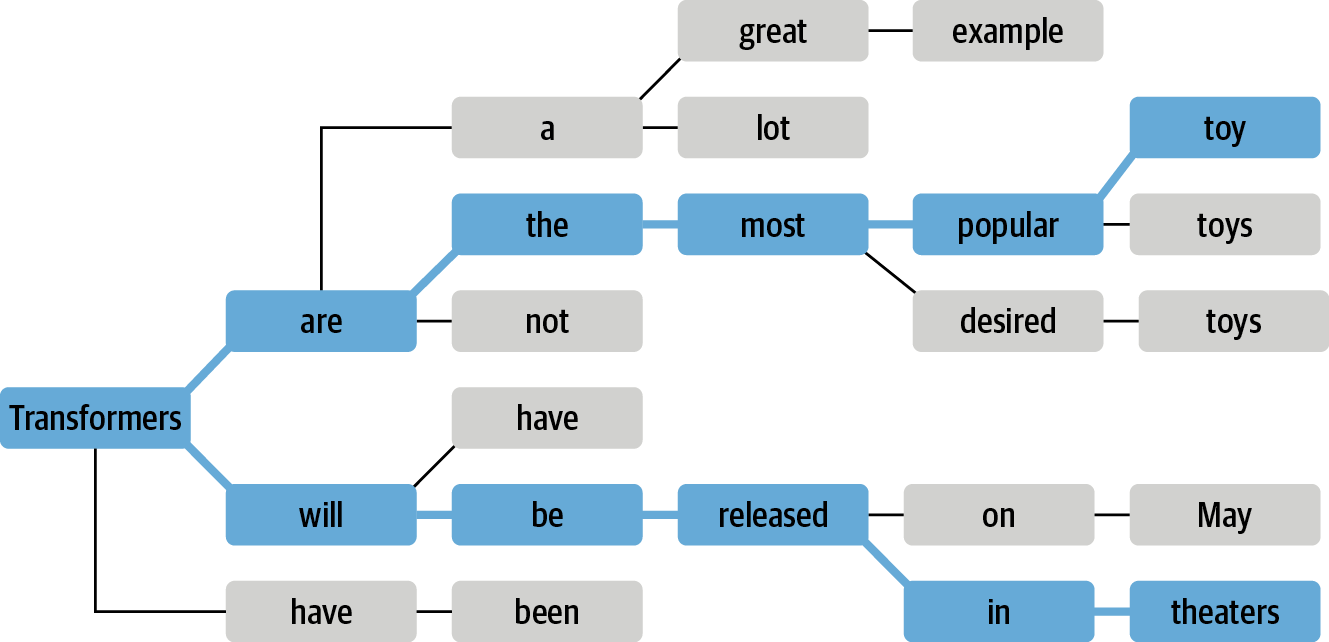

En lugar de decodificar el token con la mayor probabilidad en cada paso, beam search mantiene un registro de los próximos tokens más probables, donde $b$ se refiere al número de beams o hipótesis parciales. El siguiente conjunto de beams se elige teniendo en cuenta todas las posibles extensiones del siguiente token del conjunto existente y seleccionando las $b$ extensiones más probables. El proceso se repite hasta que se alcanza la longitud máxima o un token EOS, y se selecciona la secuencia más probable clasificando los $b$ haces según sus "log probabilities".

Calculemos y comparemos los log probabilities del texto generado por greedy search y beam search para ver si la beam search puede mejorar la probabilidad global:

In [ ]:
import torch.nn.functional as F

def log_probs_from_logits(logits, labels):
    logp = F.log_softmax(logits, dim=-1)
    logp_label = torch.gather(logp, 2, labels.unsqueeze(2)).squeeze(-1)
    return logp_label

In [ ]:
def sequence_logprob(model, labels, input_len=0):
    with torch.no_grad():
        output = model(labels)
        log_probs = log_probs_from_logits(
            output.logits[:, :-1, :], labels[:, 1:])
        seq_log_prob = torch.sum(log_probs[:, input_len:])
    return seq_log_prob.cpu().numpy()

Utilicemos estas funciones para calcular primero el log probaility de la secuencia del decodificador greedy:

In [ ]:
logp = sequence_logprob(model, output_greedy, input_len=len(input_ids[0]))
print(tokenizer.decode(output_greedy[0]))
print(f"\nlog-prob: {logp:.2f}")

En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇEl idioma de los unicornios!ˇ

log-prob: -20.17


Ahora comparemos esto con una secuencia que se genera con beam search:

In [ ]:
output_beam = model.generate(input_ids, max_length=max_length, num_beams=5,
                             do_sample=False)
logp = sequence_logprob(model, output_beam, input_len=len(input_ids[0]))
print(tokenizer.decode(output_beam[0]))
print(f"\nlog-prob: {logp:.2f}")

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. Ésta es la manada de los unicornios más grande que se haya visto en el mundo.La manada de los unicornios más grande que se haya visto en el mundo.La manada de los unicornios más grande que se haya visto en el mundo.La manada de los unicornios más grande que se haya visto en el mundo.La manada

log-prob: -44.11


Podemos ver que obtenemos una probabilidad parecida con beam search que con greedy search. Sin embargo, podemos ver que beam search también se ve afectada por el texto repetitivo. Una forma de solucionar esto es imponer una penalización de n-gramas:

In [ ]:
output_beam = model.generate(input_ids, max_length=max_length, num_beams=5,
                             do_sample=False, no_repeat_ngram_size=2)
logp = sequence_logprob(model, output_beam, input_len=len(input_ids[0]))
print(tokenizer.decode(output_beam[0]))
print(f"\nlog-prob: {logp:.2f}")

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. Ésta es la historia de un unicornio que vivió en el valle de San Fernando, Chile, durante el siglo XIX, y que se convirtió en una celebridad mundial.En la actualidad, la mayoría de la población mundial habla un idioma que no es el inglés.El idioma más hablado en todo el mundo, el español, es una de las lenguas más habladas

log-prob: -95.42


¡Esto no está tan mal!

## **7.3 Generación Creativa (Sampling)**

#### Temperatura

Podemos controlar fácilmente la diversidad de la salida añadiendo un parámetro de _temperatura_ $T$ que reescala los logits antes de tomar el softmax:

$$ P(y_t = w_i | y_{<t}, \mathbf{x}) = \frac{\exp(z_{t,i}/T)}{\sum_{j=1}^{|V|} \exp(z_{t,j}/T)} \,.$$

Una temperatura baja significa que los tokens con una alta probabilidad se disparan mientras que las probabilidades de los token menos probables son "damped". Para ver cómo podemos utilizar la temperatura para influir en el texto generado, tomemos una muestra con $T = 2$:

In [ ]:
torch.manual_seed(42)
output_temp = model.generate(input_ids, max_length=max_length, do_sample=True,
                             temperature=2.0, top_k=0)
print(tokenizer.decode(output_temp[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. Un 245% promulgó legítima Madame123Ter Els Matnhorias 2 guardianes Bilmen cuanta gran espejo TI Aire 181 cro hablarles sigue seLlevacta tes contactoVeamos: humana z doncol Dios bobo segundo europeas césped Su hervía recíproca Enlace consuetudinario emitir tent con Independencia dirá Senador cerca tornilloTu PO ruidos celebre principalmente reciclAportación buena ¿ Bajos Tres Propi colon PlaeranRegla evidente


Podemos ver claramente que una temperatura alta ha producido sobre todo un galimatías; al acentuar las tokens raras, hemos hecho que el modelo cree una gramática extraña y bastantes palabras inventadas. Veamos qué ocurre si reducimos la temperatura:

In [ ]:
torch.manual_seed(42)
output_temp = model.generate(input_ids, max_length=max_length, do_sample=True,
                             temperature=0.75, top_k=0)
print(tokenizer.decode(output_temp[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. ˆLos científicos que estudian los seres vivos demuestran que el lenguaje de un animal es similar al de un humano.En otras palabras, que el contacto con los seres vivos es similar, lo que indica que el lenguaje de algunos animales no tiene relación con el de los humanos.No obstante, en gran parte del mundo el inglés es una lengua muerta, incluso cuando


#### Top-k y top-p sampling

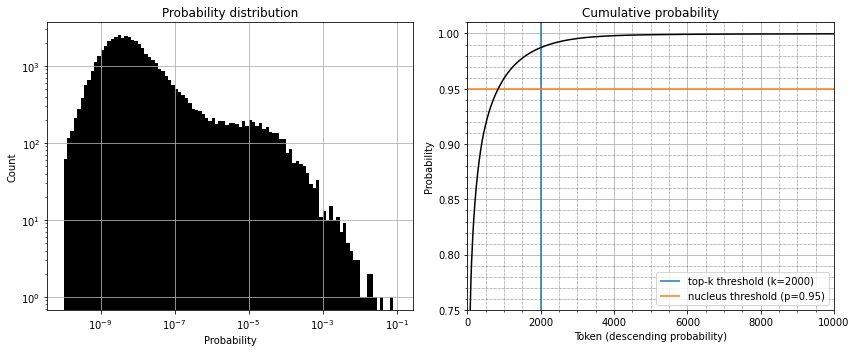

El muestreo top-k y el núcleo (top-p) son dos alternativas o extensiones populares al uso de la temperatura. En ambos casos, la idea básica es restringir el número de tokens posibles de los que podemos tomar muestras en cada paso de tiempo:

In [ ]:
torch.manual_seed(42)
output_topk = model.generate(input_ids, max_length=max_length, do_sample=True,
                             top_k=200)
print(tokenizer.decode(output_topk[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. ue la mayoría de los depredadores aéreos no entienden la palabra “viven”.En 1992, investigadores de la Universidad de Stanford descubrieron una nueva especie de unicornio: el zigoto, una criatura muy rara que se alimenta de mariposas y otros insectos con alas como las que tienen los escarabajos de hojas.Desde el descubrimiento de fósiles notables de vida en el


In [ ]:
torch.manual_seed(42)
output_topp = model.generate(input_ids, max_length=max_length, do_sample=True,
                             top_p=0.50)
print(tokenizer.decode(output_topp[0]))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un hallazgo sorprendente, los científicos descubrieron una manada de unicornios que vivía en un valle remoto, hasta ahora inexplorado, en la cordillera de los Andes. Más sorprendente aún para los investigadores fue el hecho de que los unicornios hablaban un inglés perfecto. ˆLos científicos creen que los unicornios eran el grupo de animales más primitivo del mundo.La palabra unicornio significa literalmente "el unicornio".Y es una referencia a los unicornios.El unicornio es un animal muy parecido a los unicornios.Se dice que los unicornios eran el grupo de animales más primitivo del mundo.


## **7.4 Comparativa de Resultados**
Al finalizar las pruebas, es útil comparar cómo varía la calidad del texto según el método elegido.

| Método | Ventajas | Inconvenientes |
|:-----:|:-------------------------:|:---------------------------------------------:|
| Greedy | Rápido y determinista. | Tiende a ser repetitivo y cíclico. |
| Beam Search | Mayor coherencia gramatical. | Puede sonar poco natural o "demasiado perfecto". |
| Top-P Sampling | Muy humano y creativo. | Riesgo de perder el sentido lógico o "alucinar". |

### Prueba tu propio Prompt

In [ ]:
def generar_texto_personalizado(mi_prompt, creatividad=0.8):
    ids = tokenizer.encode(mi_prompt, return_tensors="pt").to(device)
    salida = model.generate(
        ids,
        max_length=100,
        do_sample=True,
        top_p=0.9,
        temperature=creatividad
    )
    return tokenizer.decode(salida[0], skip_special_tokens=True)

# Ejemplo de uso
print(generar_texto_personalizado("En un lugar de la Mancha,"))

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


En un lugar de la Mancha, la historia de una mujer con el pelo largo le gana a la de un hombre joven.Es la primera vez que se encuentra con una mujer con el pelo largo y de ojos azules.Ella está sola y a veces no sale de su casa.Cuando es a la cama, su madre la encuentra y le dice que se vaya y se quede.Su madre lo rechaza y su padre le dice que no la ha visto en meses.En un lugar de la Mancha,
